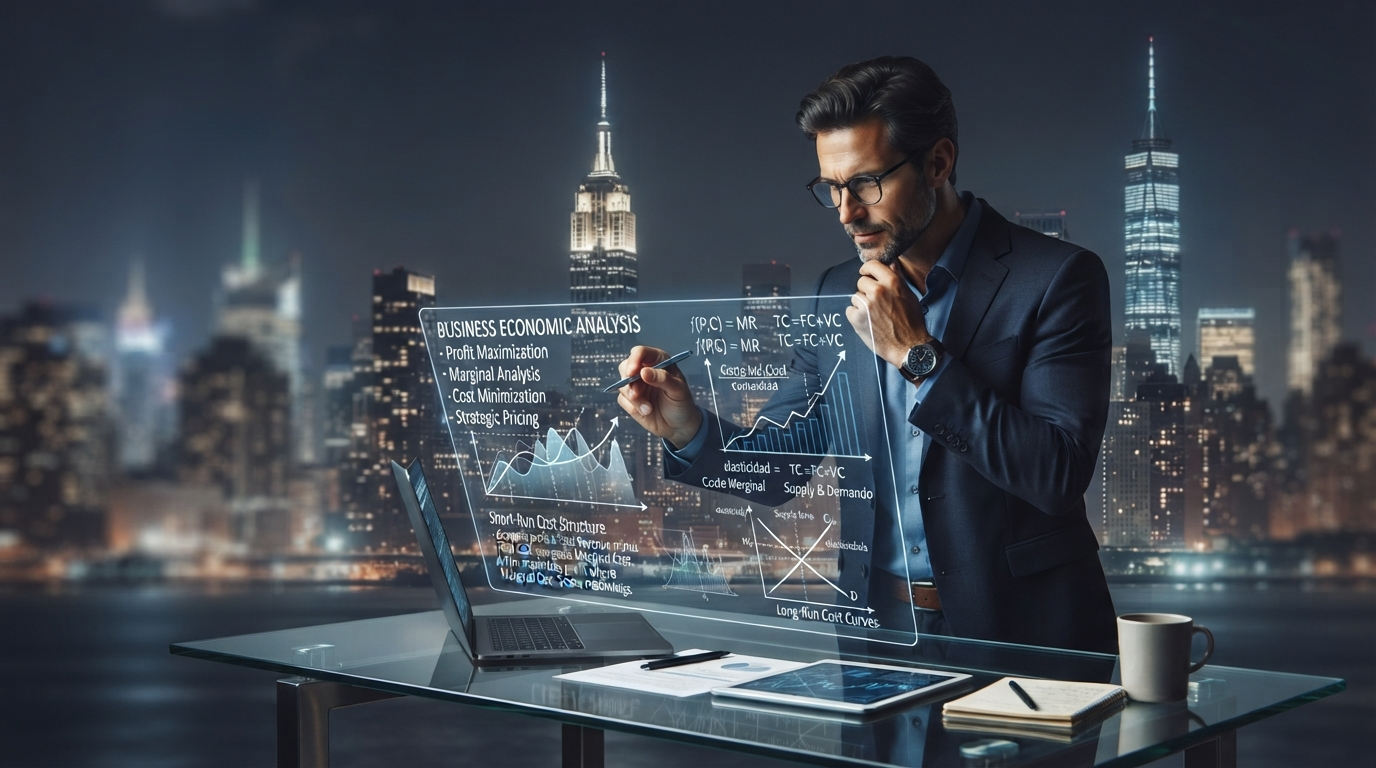

# Economic Intelligence for Business Strategy

## Business Importance
Businesses operate in economic environments where consumer behavior, market conditions, government policies, and production costs directly influence profitability. Understanding these factors is essential for developing effective pricing strategies, optimizing resources, and maintaining competitiveness. Economic theory and econometric modeling provide tools to quantify these relationships and evaluate their business implications. This project applies economic principles to support data-driven business decisions.

## Business Problem
Businesses often make strategic decisions without fully understanding the economic factors influencing their performance. Changes in prices, consumer income, taxation, production costs, competition, and macroeconomic conditions can significantly affect demand, revenue, and profitability. Identifying these relationships requires more than observing historical business performance, it requires understanding the underlying economic mechanisms. Without this analysis, organizations risk making inefficient pricing, production, and investment decisions.

## Project Objective
The objective of this project is to apply economic theory and econometric techniques to analyze how economic factors influence business performance and strategic decisions. It examines consumer behavior, price and income elasticities, production economics, market competition, taxation, and macroeconomic conditions. Through quantitative modeling, the project aims to estimate economic relationships and evaluate their implications for businesses. Ultimately, the findings will support more informed decisions regarding pricing, production, resource allocation, and profitability.

## Economics factors under consideration

1. Consumer Theory & Elasticities
2. Pricing Economics & Revenue Management
3. Production Economics, Costs & Business Efficiency
4. Market Structures & Competitive Economics
5. Taxation, Government Intervention & Regulatory Economics
6. Macroeconomic Environment & Business Performance
7. Labor Economics & Human Capital
8. International Economics & Global Business

## Importing useful libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
import re

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")

import warnings
warnings.filterwarnings("ignore")

# Visualization Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

## Merging the final dataset with feature engineering and gettings stats

In [2]:
df1 = pd.read_csv("econometrics_business_part_one.csv", sep=";", thousands=",")
df2 = pd.read_csv("econometrics_business_part_two.csv", sep=";", thousands=",")
df = pd.concat([df1, df2])

df["Period"]          = df["Year"] * 10 + df["Quarter"]
df["Trend"]           = (df["Year"] - df["Year"].min()) + (df["Quarter"] - 1) / 4
df["CP"]              = pd.factorize(df["Country"].astype(str) + "_" + df["Period"].astype(str))[0]
df["Capital_Cost"]    = df["Capital_Investment"]
df["Rel_Price"]       = df["Product_Price"] / df["Competitor_Price"]
df["Unit_Cost"]       = df["Operating_Cost"] / df["Production_Quantity"]
df["Raw_per_Unit"]    = df["Raw_Material_Cost"] / df["Production_Quantity"]
df["Prod"]            = df["Production_Quantity"] / df["Labor_Cost"] * 1000
df["Op_Margin"]       = df["Operating_Profit"] / df["Total_Revenue"]
df["Labor_Share_Rev"] = df["Labor_Cost"] / df["Total_Revenue"]
df["ULC"]             = df["Labor_Cost"] / df["Production_Quantity"]
df["Cum_Q"]           = df.groupby("Product_ID")["Production_Quantity"].cumsum()
df["ln_Units"]     = np.log(df["Units_Sold"])
df["ln_Price"]     = np.log(df["Product_Price"])
df["ln_CompPrice"] = np.log(df["Competitor_Price"])
df["ln_Income"]    = np.log(df["Consumer_Income"])
df["ln_Adv"]       = np.log1p(df["Advertising_Expenditure"])
df["ln_Subsidy"]   = np.log1p(df["Subsidy"].clip(lower=0))
df["ln_Cost"]      = np.log(df["Operating_Cost"])
df["ln_Q"]         = np.log(df["Production_Quantity"])
df["ln_K"]         = np.log(df["Capital_Investment"])
df["ln_Labor"]     = np.log(df["Labor_Cost"])
df["ln_L"]         = np.log(df["Labor_Cost"])
df["ln_Raw"]       = np.log(df["Raw_Material_Cost"])
df["ln_Rev"]       = np.log(df["Total_Revenue"])
df["ln_FX"]        = np.log(df["Exchange_Rate"])
df["ln_Rel_Price"] = np.log(df["Rel_Price"])
df["ln_Rel"]       = np.log(df["Rel_Price"])
df["ln_UC"]        = np.log(df["Unit_Cost"])
df["ln_LCU"]       = np.log(df["Labor_Cost"] / df["Production_Quantity"])
df["ln_RawU"]      = np.log(df["Raw_per_Unit"])
df["ln_Cum"]       = np.log(df["Cum_Q"])
df["ln_KL"]        = np.log(df["Capital_Investment"] / df["Labor_Cost"])
df["ln_ULC"]       = np.log(df["ULC"])
df["ln_Prod"]      = np.log(df["Prod"])
df["ln_ToT"]       = df["ln_Price"] - df["ln_RawU"]

df = df.sort_values(by=['Year', 'Quarter'])

df.head()

,Product_ID,Company_ID,Country,Industry,Year,Quarter,Market_Share,Product_Price,Competitor_Price,Units_Sold,Consumer_Income,Production_Quantity,Labor_Cost,Capital_Investment,Raw_Material_Cost,Tax_Rate,Subsidy,Inflation_Rate,Interest_Rate,Exchange_Rate,GDP_Growth,Advertising_Expenditure,Total_Revenue,Operating_Cost,Operating_Profit,Period,Trend,CP,Capital_Cost,Rel_Price,Unit_Cost,Raw_per_Unit,Prod,Op_Margin,Labor_Share_Rev,ULC,Cum_Q,ln_Units,ln_Price,ln_CompPrice,ln_Income,ln_Adv,ln_Subsidy,ln_Cost,ln_Q,ln_K,ln_Labor,ln_L,ln_Raw,ln_Rev,ln_FX,ln_Rel_Price,ln_Rel,ln_UC,ln_LCU,ln_RawU,ln_Cum,ln_KL,ln_ULC,ln_Prod,ln_ToT
0,CO001-P001,CO001,USA,Food,2015,1,0.0788,11.1200,11.6100,35603,"33,382.0000",37481,"1,047,471.0000","20,367.0000","208,674.0000",0.2106,"5,713.0000",0.1000,0.1000,1.0000,2.9000,"20,119.0000","395,961.0000","1,282,374.0000","-964,108.0000",20151,0.0000,20,"20,367.0000",0.9578,34.2140,5.5675,35.7824,-2.4349,2.6454,27.9467,677214,10.4802,2.4087,2.4519,10.4158,9.9095,8.6507,14.0642,10.5316,9.9217,13.8619,13.8619,12.2485,12.8891,0.0000,-0.0431,-0.0431,3.5326,3.3303,1.7169,13.4257,-3.9402,3.3303,3.5775,0.6918
1,CO001-P002,CO001,USA,Food,2015,1,0.0849,13.9600,13.0300,30043,"37,766.0000",31112,"869,478.0000","26,129.0000","217,374.0000",0.1988,"8,476.0000",0.1000,0.1000,1.0000,2.9000,"30,411.0000","419,307.0000","1,125,102.0000","-780,684.0000",20151,0.0000,20,"26,129.0000",1.0714,36.1630,6.9868,35.7824,-1.8618,2.0736,27.9467,642689,10.3104,2.6362,2.5673,10.5392,10.3226,9.0451,13.9334,10.3453,10.1708,13.6756,13.6756,12.2894,12.9464,0.0000,0.0689,0.0689,3.5880,3.3303,1.9440,13.3734,-3.5048,3.3303,3.5775,0.6922
2,CO001-P003,CO001,USA,Food,2015,1,0.0749,12.5800,11.6000,39701,"77,208.0000",40760,"1,139,108.0000","44,051.0000","256,768.0000",0.2094,"9,852.0000",0.1000,0.1000,1.0000,2.9000,"28,722.0000","499,595.0000","1,437,814.0000","-1,032,970.0000",20151,0.0000,20,"44,051.0000",1.0845,35.2751,6.2995,35.7824,-2.0676,2.2801,27.9467,687273,10.5891,2.5321,2.4510,11.2543,10.2655,9.1955,14.1786,10.6155,10.6931,13.9458,13.9458,12.4559,13.1216,0.0000,0.0811,0.0811,3.5632,3.3303,1.8405,13.4405,-3.2527,3.3303,3.5775,0.6916
3,CO001-P004,CO001,USA,Food,2015,1,0.0841,12.4900,13.4800,38292,"62,669.0000",40087,"1,120,300.0000","31,980.0000","250,710.0000",0.2232,"9,618.0000",0.1000,0.1000,1.0000,2.9000,"26,256.0000","478,393.0000","1,406,860.0000","-1,025,647.0000",20151,0.0000,20,"31,980.0000",0.9266,35.0952,6.2541,35.7824,-2.1439,2.3418,27.9467,683803,10.5530,2.5249,2.6012,11.0456,10.1757,9.1715,14.1569,10.5988,10.3729,13.9291,13.9291,12.4321,13.0782,0.0000,-0.0763,-0.0763,3.5581,3.3303,1.8332,13.4354,-3.5562,3.3303,3.5775,0.6917
4,CO001-P005,CO001,USA,Food,2015,1,0.0817,12.8200,13.0800,34825,"67,092.0000",36060,"1,007,759.0000","18,890.0000","231,512.0000",0.2227,"9,349.0000",0.1000,0.1000,1.0000,2.9000,"21,283.0000","446,630.0000","1,266,220.0000","-909,695.0000",20151,0.0000,20,"18,890.0000",0.9801,35.1143,6.4202,35.7824,-2.0368,2.2564,27.9467,637599,10.4581,2.5510,2.5711,11.1138,9.9657,9.1431,14.0515,10.4929,9.8464,13.8232,13.8232,12.3524,13.0095,0.0000,-0.0201,-0.0201,3.5586,3.3303,1.8594,13.3655,-3.9769,3.3303,3.5775,0.6916


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6480 entries, 0 to 3599
Data columns (total 61 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product_ID               6480 non-null   object 
 1   Company_ID               6480 non-null   object 
 2   Country                  6480 non-null   object 
 3   Industry                 6480 non-null   object 
 4   Year                     6480 non-null   int64  
 5   Quarter                  6480 non-null   int64  
 6   Market_Share             6480 non-null   float64
 7   Product_Price            6480 non-null   float64
 8   Competitor_Price         6480 non-null   float64
 9   Units_Sold               6480 non-null   int64  
 10  Consumer_Income          6480 non-null   float64
 11  Production_Quantity      6480 non-null   int64  
 12  Labor_Cost               6480 non-null   float64
 13  Capital_Investment       6480 non-null   float64
 14  Raw_Material_Cost        6480

In [4]:
df.describe()

,Year,Quarter,Market_Share,Product_Price,Competitor_Price,Units_Sold,Consumer_Income,Production_Quantity,Labor_Cost,Capital_Investment,Raw_Material_Cost,Tax_Rate,Subsidy,Inflation_Rate,Interest_Rate,Exchange_Rate,GDP_Growth,Advertising_Expenditure,Total_Revenue,Operating_Cost,Operating_Profit,Period,Trend,CP,Capital_Cost,Rel_Price,Unit_Cost,Raw_per_Unit,Prod,Op_Margin,Labor_Share_Rev,ULC,Cum_Q,ln_Units,ln_Price,ln_CompPrice,ln_Income,ln_Adv,ln_Subsidy,ln_Cost,ln_Q,ln_K,ln_Labor,ln_L,ln_Raw,ln_Rev,ln_FX,ln_Rel_Price,ln_Rel,ln_UC,ln_LCU,ln_RawU,ln_Cum,ln_KL,ln_ULC,ln_Prod,ln_ToT
count,"6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000","6,480.0000"
mean,"2,019.0000",2.5000,0.1163,"6,664.9147","6,644.4631","31,511.2549","64,415.4785","33,841.5358","1,700,623.7358","20,697,555.9869","133,691,840.5809",0.2186,"6,669,733.3353",2.8556,1.4111,1.0000,1.8556,"11,272,040.2881","224,522,629.2784","152,873,771.4006","31,113,133.7239","20,192.5000",4.3750,17.5000,"20,697,555.9869",1.0039,"4,262.8218","3,728.1245",26.2104,-0.4449,0.7192,47.0502,"544,859.3485",9.6760,5.6360,5.6341,11.0419,12.3949,9.6248,15.3133,9.7446,12.9102,13.4903,13.4903,14.3992,15.3120,0.0000,0.0019,0.0019,5.5687,3.7456,4.6546,12.7992,-0.5801,3.7456,3.1621,0.9814
std,2.5822,1.1181,0.0570,"12,436.9342","12,427.4172","22,009.0715","15,376.4028","23,503.2071","1,627,949.4713","48,688,983.0296","305,107,324.8366",0.0197,"15,676,369.4148",2.2625,1.4679,0.0000,2.3788,"25,152,234.6508","505,568,777.9861","343,915,860.8281","72,787,397.3337",25.8461,2.5973,10.3891,"48,688,983.0296",0.0639,"7,997.9660","7,098.4730",11.6922,0.9284,0.8742,21.5357,"431,062.7907",2.4135,2.7389,2.7382,0.2586,3.7586,6.0148,3.4721,2.4293,3.7546,2.5251,2.5251,3.8061,3.7645,0.0000,0.0635,0.0635,2.3492,0.4629,2.8071,1.0335,2.6005,0.4629,0.4629,0.4728
min,"2,015.0000",1.0000,0.0148,9.3500,8.4900,1.0000,"5,881.0000",1.0000,22.0000,1.0000,5.0000,0.1681,0.0000,0.1000,0.1000,1.0000,-3.4000,1.0000,10.0000,34.0000,"-6,467,867.0000","20,151.0000",0.0000,0.0000,1.0000,0.8927,33.5721,4.7649,10.9162,-3.2897,0.0012,21.9581,"5,188.0000",0.0000,2.2354,2.1389,8.6795,0.6931,0.0000,3.5264,0.0000,0.0000,3.0910,3.0910,1.6094,2.3026,0.0000,-0.1135,-0.1135,3.5137,3.0891,1.5613,8.5541,-4.2729,3.0891,2.3902,0.5062
25%,"2,017.0000",1.7500,0.0696,43.7975,43.7675,"18,218.7500","53,968.5000","19,534.0000","621,395.7500","64,842.0000","338,741.0000",0.2049,"1,299.7500",1.3000,0.4000,1.0000,2.1000,"32,503.7500","722,083.7500","1,054,371.7500","-631,270.2500","20,171.7500",2.1875,8.7500,"64,842.0000",0.9482,43.9383,18.2259,16.6984,-0.4093,0.1044,28.3782,"186,836.0000",9.8102,3.7796,3.7789,10.8962,10.3891,7.1707,13.8685,9.8799,11.0797,13.3397,13.3397,12.7330,13.4899,0.0000,-0.0532,-0.0532,3.7828,3.3456,2.9028,12.1380,-2.2106,3.3456,2.8153,0.6386
50%,"2,019.0000",2.5000,0.1222,99.4100,98.9300,"25,894.5000","64,313.0000","27,895.5000","1,161,632.5000","210,932.0000","889,028.0000",0.2138,"53,286.0000",2.1000,1.0000,1.0000,2.3000,"85,593.0000","2,282,614.5000","2,660,186.0000","-241,140.0000","20,192.5000",4.3750,17.5000,"210,932.0000",1.0003,103.7208,37.3996,23.3191,-0.2326,0.5284,42.8833,"453,378.5000",10.1618,4.5993,4.5944,11.0715,11.3574,10.8834,14.7939,10.2362,12.2593,13.9653,13.9653,13.6979,14.6408,0.0000,0.0003,0.0003,4.6417,3.7585,3.6217,13.0245,-1.5851,3.7585,3.1493,0

## ==============================================================
## === Consumer Behavior & Demand Economics
## ==============================================================

### 1. Price, Income & Cross-Price Elasticity


Global log-log model (coefficients = elasticities):
             Elasticity  p_value  CI_low  CI_high
Price (own)     -0.9511   0.0000 -1.0246  -0.8777
Cross-price     -0.0214   0.4938 -0.0829   0.0400
Income          -0.0109   0.1781 -0.0268   0.0050
R2 = 0.996

Elasticities by industry:
  Industry    N  Price_Elast  p_price  Cross_Elast  Income_Elast Demand_Type Cross_Relation  Rev_Change_+5%  Rev_Change_+10%              Pricing_Power
Automotive 1392      -0.9485   0.0000      -0.0751       -0.0015   Inelastic     Complement          0.2518           0.4925            Can raise price
    Energy  984      -0.8416   0.0000      -0.0797        0.0149   Inelastic     Complement          0.7758           1.5211            Can raise price
      Food 1080      -1.0457   0.0000       0.0140       -0.0245     Elastic     Substitute         -0.2229          -0.4349 Higher price hurts revenue
    Pharma  648      -1.0338   0.0000       0.0260       -0.0186     Elastic     Substitute         -

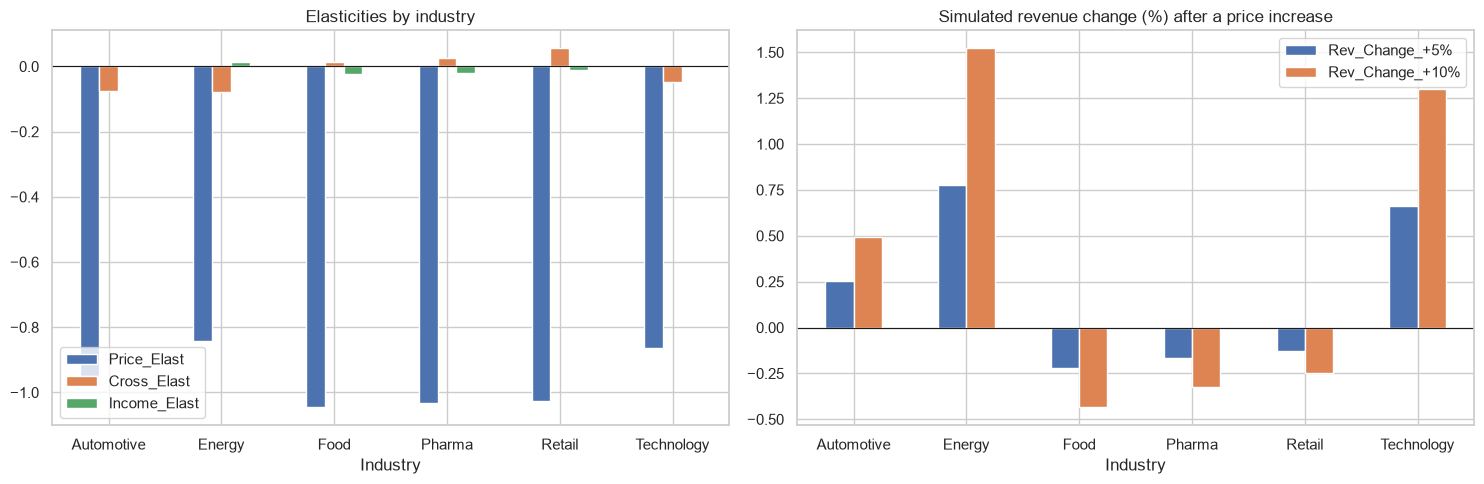

In [5]:
MIN_OBS = 30
FORMULA = ("ln_Units ~ ln_Price + ln_CompPrice + ln_Income + ln_Adv"
           " + Interest_Rate + Inflation_Rate + GDP_Growth + Tax_Rate")

# Global model with industry and country fixed effects
m_global = smf.ols(FORMULA + " + C(Industry) + C(Country)", data=df).fit(cov_type="HC1")
key = ["ln_Price", "ln_CompPrice", "ln_Income"]
glob = pd.DataFrame({"Elasticity": m_global.params[key],
                     "p_value": m_global.pvalues[key],
                     "CI_low": m_global.conf_int().loc[key, 0],
                     "CI_high": m_global.conf_int().loc[key, 1]})
glob.index = ["Price (own)", "Cross-price", "Income"]
print("\nGlobal log-log model (coefficients = elasticities):")
print(glob)
print(f"R2 = {m_global.rsquared:.3f}")

# Per-industry model: one row per industry, all concepts in one table
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols(FORMULA, data=g).fit(cov_type="HC1")
    # data-driven substitution: sensitivity to price RELATIVE to competitor
    m_rel = smf.ols("ln_Units ~ ln_Rel_Price + ln_Income + ln_Adv + GDP_Growth", data=g).fit(cov_type="HC1")
    rows.append({"Industry": ind, "N": len(g),
                 "Price_Elast": m.params["ln_Price"], "p_price": m.pvalues["ln_Price"],
                 "Cross_Elast": m.params["ln_CompPrice"],
                 "Income_Elast": m.params["ln_Income"],
                 "GDP_Sensitivity_%": m.params["GDP_Growth"] * 100,
                 "RelPrice_Elast": m_rel.params["ln_Rel_Price"]})
tab = pd.DataFrame(rows)

tab["Demand_Type"] = np.where(tab["Price_Elast"].abs() > 1, "Elastic", "Inelastic")
tab["Cross_Relation"] = np.where(tab["Cross_Elast"] > 0, "Substitute", "Complement")
for x in (0.05, 0.10):   # revenue change under constant elasticity: (1+x)^(1+e) - 1
    tab[f"Rev_Change_+{int(x*100)}%"] = ((1 + x) ** (1 + tab["Price_Elast"]) - 1) * 100
tab["Pricing_Power"] = np.where(tab["Rev_Change_+10%"] > 0, "Can raise price", "Higher price hurts revenue")

print("\nElasticities by industry:")
print(tab[["Industry", "N", "Price_Elast", "p_price", "Cross_Elast", "Income_Elast",
           "Demand_Type", "Cross_Relation", "Rev_Change_+5%", "Rev_Change_+10%", "Pricing_Power"]]
      .to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
tab.set_index("Industry")[["Price_Elast", "Cross_Elast", "Income_Elast"]].plot.bar(ax=ax[0], rot=0)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Elasticities by industry")
tab.set_index("Industry")[["Rev_Change_+5%", "Rev_Change_+10%"]].plot.bar(ax=ax[1], rot=0)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Simulated revenue change (%) after a price increase")
plt.tight_layout()
plt.show()

most = tab.loc[tab["Price_Elast"].idxmin()]
least = tab.loc[tab["Price_Elast"].idxmax()]

**Glossary:**

**Log-log model:** A regression specification in which both the dependent and independent variables are in logarithms, so the estimated coefficient directly gives an elasticity.

**Price Elasticity:** The percentage change in quantity demanded (or supplied) resulting from a one percent change in price.

**Cross Elasticity:** The percentage change in quantity demanded of one good resulting from a one percent change in the price of another good.

**Income Elasticity:** The percentage change in quantity demanded resulting from a one percent change in consumer income.

**Conclusion:** The analysis reveals a critical strategic divide in our portfolio: while the Technology and Energy sectors possess inelastic demand allowing for profitable price hikes (simulated revenue gains of up to 1.5% for a 10% price increase), the Food, Pharma, and Retail sectors are highly elastic, meaning any price increase would actively destroy revenue. For instance, our models show that raising prices by 10% in Technology boosts revenue by 1.30%, whereas the same move in Pharma results in a 0.32% loss because customers simply switch to substitutes or stop buying. Surprisingly, the global model indicates that demand is driven almost exclusively by our own pricing (R²=0.996), with competitor prices and consumer income having statistically negligible impact, suggesting these markets are isolated from broader economic shifts. Consequently, my strongest recommendation is to aggressively exercise "Pricing Power" in the Tech and Energy divisions immediately, while freezing prices in Retail and Food to protect our market volume.

###  2. Normal/Inferior, Necessity/Luxury, Substitution & Income Effect

  Industry  Income_Elast          Good_Type  GDP_Sensitivity_%   Cyclicality  Subs_Effect  Income_Effect  Total_Effect  RelPrice_Elast Dominant_Effect
Automotive       -0.0015           Inferior             0.1232 Less cyclical      -0.9486         0.0002       -0.9485          0.0504    Substitution
    Energy        0.0149 Normal - Necessity             0.4351 More cyclical      -0.8401        -0.0015       -0.8416          0.1044    Substitution
      Food       -0.0245           Inferior             0.4742 More cyclical      -1.0482         0.0025       -1.0457          0.0008    Substitution
    Pharma       -0.0186           Inferior            -0.0336 Less cyclical      -1.0357         0.0019       -1.0338          0.1329    Substitution
    Retail       -0.0105           Inferior             0.3332 Less cyclical      -1.0271         0.0011       -1.0261          0.0212    Substitution
Technology        0.0002 Normal - Necessity             0.3786 More cyclical      -0.8643     

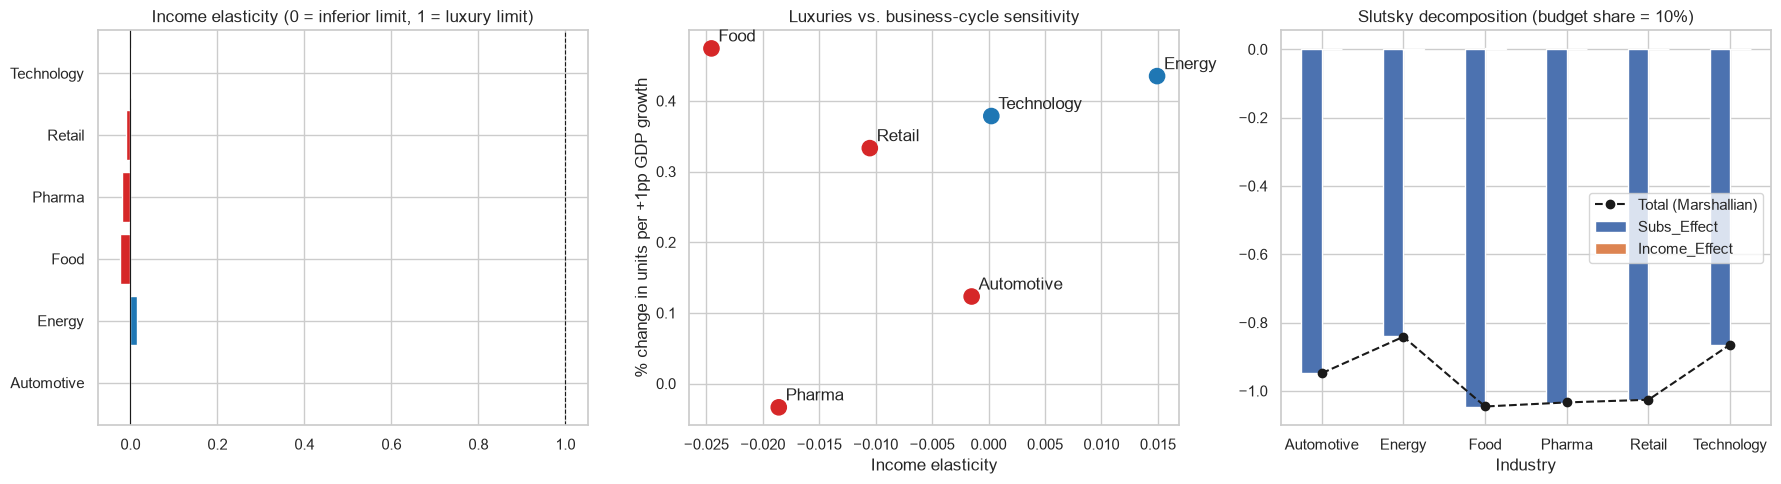

In [6]:
BUDGET_SHARE = 0.10 

tab["Good_Type"] = np.select([tab["Income_Elast"] < 0, tab["Income_Elast"] < 1],
                             ["Inferior", "Normal - Necessity"], "Normal - Luxury")
tab["Cyclicality"] = np.where(tab["GDP_Sensitivity_%"] > tab["GDP_Sensitivity_%"].median(),
                              "More cyclical", "Less cyclical")

# Slutsky: total effect = substitution effect + income effect
tab["Income_Effect"] = -BUDGET_SHARE * tab["Income_Elast"]
tab["Subs_Effect"] = tab["Price_Elast"] - tab["Income_Effect"]
tab["Total_Effect"] = tab["Subs_Effect"] + tab["Income_Effect"]
tab["Dominant_Effect"] = np.where(tab["Subs_Effect"].abs() > tab["Income_Effect"].abs(),
                                  "Substitution", "Income")

print(tab[["Industry", "Income_Elast", "Good_Type", "GDP_Sensitivity_%", "Cyclicality",
           "Subs_Effect", "Income_Effect", "Total_Effect", "RelPrice_Elast",
           "Dominant_Effect"]].to_string(index=False))

colors = tab["Good_Type"].map({"Inferior": "#d62728", "Normal - Necessity": "#1f77b4",
                               "Normal - Luxury": "#2ca02c"})
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].barh(tab["Industry"], tab["Income_Elast"], color=colors)
ax[0].axvline(0, color="k", lw=0.8)
ax[0].axvline(1, color="k", ls="--", lw=0.8)
ax[0].set_title("Income elasticity (0 = inferior limit, 1 = luxury limit)")
ax[1].scatter(tab["Income_Elast"], tab["GDP_Sensitivity_%"], c=colors, s=120)
for _, r in tab.iterrows():
    ax[1].annotate(r["Industry"], (r["Income_Elast"], r["GDP_Sensitivity_%"]),
                   xytext=(5, 5), textcoords="offset points")
ax[1].set_xlabel("Income elasticity")
ax[1].set_ylabel("% change in units per +1pp GDP growth")
ax[1].set_title("Luxuries vs. business-cycle sensitivity")
tab.set_index("Industry")[["Subs_Effect", "Income_Effect"]].plot.bar(ax=ax[2], rot=0)
ax[2].plot(tab["Industry"], tab["Total_Effect"], "ko--", label="Total (Marshallian)")
ax[2].legend()
ax[2].set_title(f"Slutsky decomposition (budget share = {BUDGET_SHARE:.0%})")
plt.tight_layout()
plt.show()

lux = tab.loc[tab["Income_Elast"].idxmax()]

**Glossary**

**Budget Share:** The proportion of total expenditure (or total budget) allocated to a particular good, category, or item, typically calculated as the expenditure on that item divided by total expenditure.

**GDP_Sensitivity_%:** The percentage change in a variable (e.g., demand, revenue, or sales) associated with a one percent change in GDP, measuring how strongly that variable responds to overall economic activity.

**Cyclicality:** The degree to which a variable moves in tandem with the business cycle, rising during expansions and falling during contractions (positive cyclicality) or moving in the opposite direction (counter-cyclicality).

**Conclusion:** The most important insight about the Slutsky decomposition is that brand loyalty is effectively non-existent in our current model, as the substitution effect completely dominates demand destruction across all sectors, meaning a price hike in Technology (total effect -0.86) will simply drive customers to competitors rather than just reducing their overall consumption. Furthermore, we face a counter-intuitive portfolio classification where "essential" sectors like Food and Pharma are technically Inferior goods with negative income elasticity, yet Food remains highly cyclical with high GDP sensitivity, suggesting aggregate demand for basics still rises in a booming economy even as individual spending shares shrink. This creates a strategic dichotomy where Energy and Technology act as our growth engines during expansions due to their "Normal" good status and high cyclicality, while Pharma emerges as our only true defensive asset with negative GDP sensitivity. Consequently, if we anticipate a recession, we must pivot resources toward Pharma, as it is the sole sector projected to outperform when the broader economy contracts.

### 3. Consumer Surplus

  Industry       Slope   Avg_Price   Avg_Units  Choke_Price       CS_per_obs  CS_%_of_Spend             Total_CS
Automotive     -1.1367 30,271.8651 33,628.5639  59,856.5885 497,445,880.6716        48.8650 692,444,665,894.8162
    Energy   -323.4089     91.0240 35,134.0142     199.6605   1,908,418.4696        59.6747   1,877,883,774.0922
      Food -2,057.8231     12.0899 29,721.6083      26.5331     214,637.9860        59.7327     231,809,024.8903
    Pharma   -253.9486    120.3483 29,548.2855     236.7037   1,719,050.7571        48.3411   1,113,944,890.6075
    Retail   -464.7911     45.3623 22,590.3392      93.9655     548,981.5487        53.5722     751,006,758.6588
Technology    -43.0664    801.1360 40,337.1935   1,737.7642  18,890,475.8989        58.4563  19,041,599,706.0494


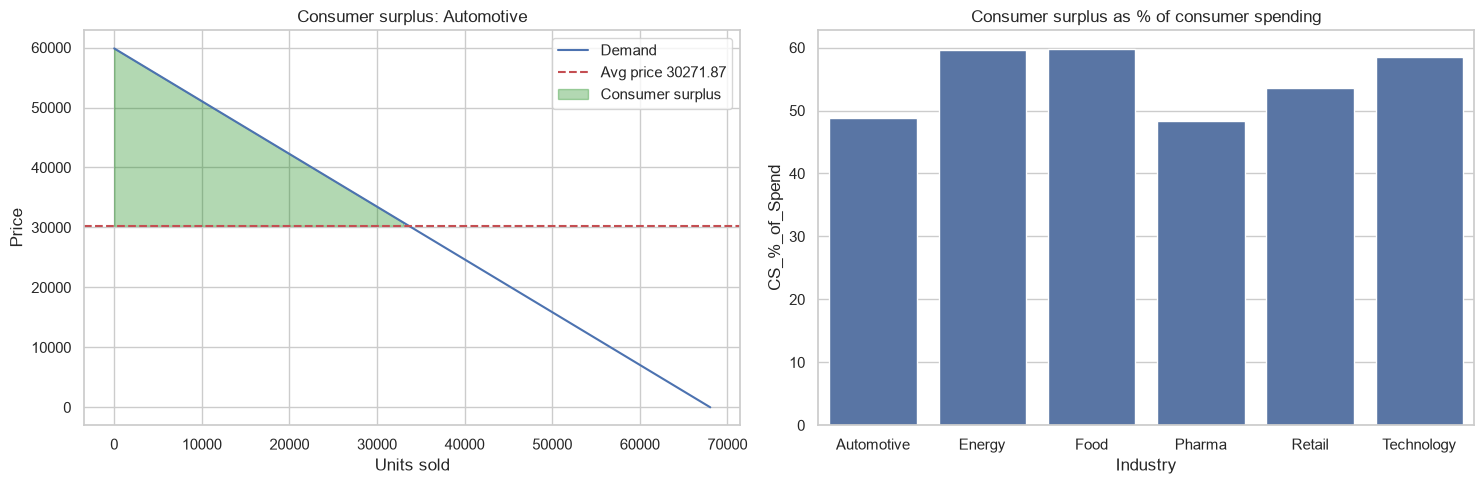

In [7]:
rows, curves = [], {}
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols("Units_Sold ~ Product_Price + Competitor_Price + Consumer_Income + Advertising_Expenditure",
                data=g).fit()
    b = m.params["Product_Price"]
    p0, q0 = g["Product_Price"].mean(), g["Units_Sold"].mean()
    if b >= 0:                      # demand not downward sloping, so CS is not meaningful
        rows.append({"Industry": ind, "Slope": b, "Choke_Price": np.nan, "CS_per_obs": np.nan,
                     "CS_%_of_Spend": np.nan, "Total_CS": np.nan})
        continue
    a = q0 - b * p0                 # intercept, other variables held at their means
    p_choke = -a / b                # price at which demand falls to zero
    cs = 0.5 * (p_choke - p0) * q0  # triangle above the price paid
    curves[ind] = (a, b, p0, q0, p_choke)
    rows.append({"Industry": ind, "Slope": b, "Avg_Price": p0, "Avg_Units": q0, "Choke_Price": p_choke,
                 "CS_per_obs": cs, "CS_%_of_Spend": cs / (p0 * q0) * 100, "Total_CS": cs * len(g)})
cs_tab = pd.DataFrame(rows)
print(cs_tab.to_string(index=False))
tab = tab.merge(cs_tab[["Industry", "CS_%_of_Spend"]], on="Industry", how="left")

if curves:
    top = cs_tab.dropna(subset=["CS_per_obs"]).sort_values("CS_per_obs", ascending=False).iloc[0]["Industry"]
    a, b, p0, q0, p_choke = curves[top]
    prices = np.linspace(0, p_choke, 100)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    ax[0].plot(a + b * prices, prices, label="Demand")
    ax[0].axhline(p0, color="r", ls="--", label=f"Avg price {p0:.2f}")
    ax[0].fill_between(a + b * prices, p0, prices, where=prices >= p0, alpha=0.3, color="green",
                       label="Consumer surplus")
    ax[0].set_xlabel("Units sold")
    ax[0].set_ylabel("Price")
    ax[0].set_title(f"Consumer surplus: {top}")
    ax[0].legend()
    sns.barplot(data=cs_tab.dropna(subset=["CS_%_of_Spend"]), x="Industry", y="CS_%_of_Spend", ax=ax[1])
    ax[1].set_title("Consumer surplus as % of consumer spending")
    plt.tight_layout()
    plt.show()

**Conclusion:** The data reveals that our customers perceive immense value across the portfolio, capturing roughly 50-60% of their total spending as Consumer Surplus, with the Food sector representing the most critical market by far at approx USD 231 billion in total surplus. Crucially, the Technology and Automotive sectors show massive "pricing headroom," as their Choke Prices (the point where demand hits zero) are more than double the current average price, for instance, Technology could theoretically reach approx USD 1,737 before losing all customers, compared to the current approx USD 801. In contrast, the Food sector exhibits an extremely steep demand slope (-2,057), meaning that while the total market value is huge, volume would collapse rapidly with even minor price increases, validating our previous finding that "higher price hurts revenue" in this sector. So, my strongest recommendation is to aggressively raise prices in Technology and Automotive to capture the unclaimed surplus, while strictly maintaining volume-focused strategies in Food to protect that USD 231 billion welfare pool.

### 4. Consumer Preferences


By income segment:
Income_Segment    N  Price_Elast  Cross_Elast  Adv_Elast   Avg_Units
           Low 2160      -0.9966       0.0075     0.9877 32,559.3801
           Mid 2160      -0.9641      -0.0297     0.9893 32,049.6032
          High 2160      -0.9480      -0.0466     0.9953 29,924.7815
****************************************************************************************************

Positioning vs. performance:
  Industry                Positioning  Avg_Market_Share   Avg_Units       Avg_Profit   N
Automotive Discount (<5% below rival)            0.1087 34,840.9265 141,420,373.6294 340
Automotive                     Parity            0.0992 33,661.4976 137,469,509.2932 631
Automotive  Premium (>5% above rival)            0.1036 32,600.0974 132,654,297.4632 421
    Energy Discount (<5% below rival)            0.1421 35,528.9888  -1,216,403.9257 269
    Energy                     Parity            0.1411 34,085.6621  -1,177,532.4785 441
    Energy  Premium (>5% above rival)  

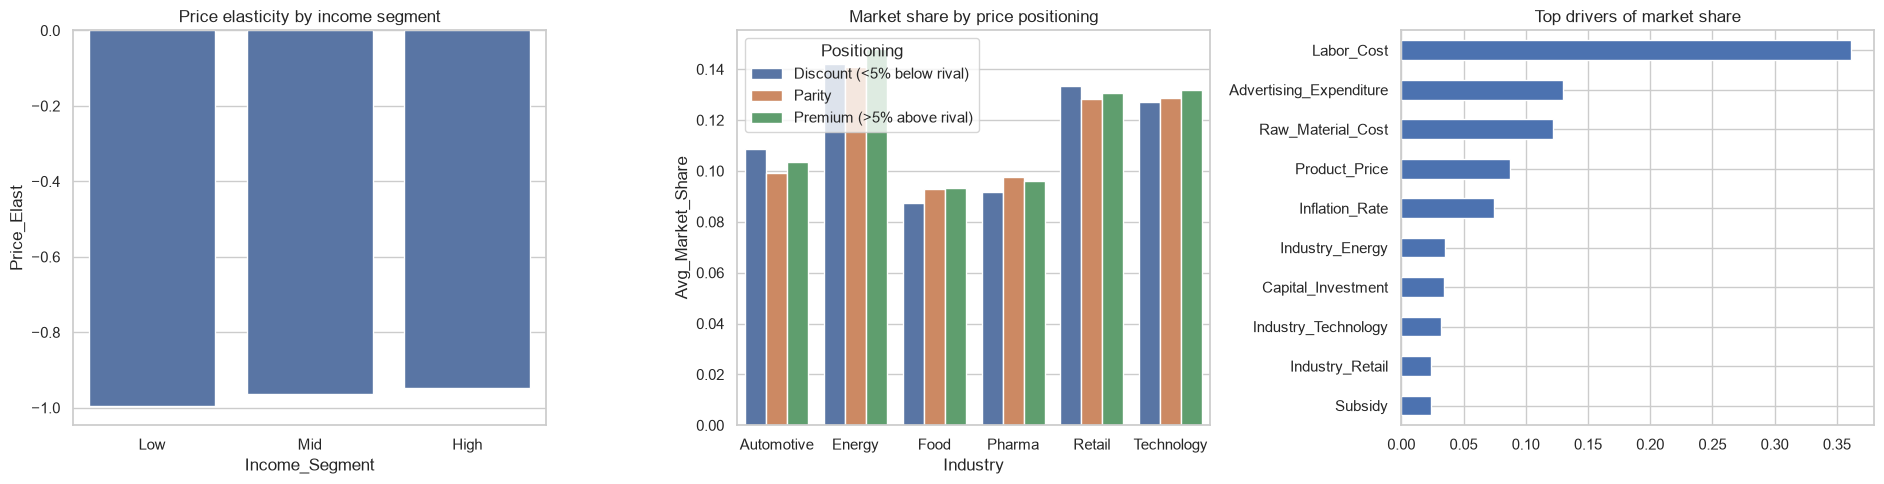

In [8]:
df["Income_Segment"] = pd.qcut(df["Consumer_Income"], 3, labels=["Low", "Mid", "High"])
df["Positioning"] = np.where(df["Rel_Price"] > 1.05, "Premium (>5% above rival)",
                     np.where(df["Rel_Price"] < 0.95, "Discount (<5% below rival)", "Parity"))

# Price sensitivity by income segment
seg_rows = []
for seg, g in df.groupby("Income_Segment", observed=True):
    m = smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Adv", data=g).fit(cov_type="HC1")
    seg_rows.append({"Income_Segment": seg, "N": len(g), "Price_Elast": m.params["ln_Price"],
                     "Cross_Elast": m.params["ln_CompPrice"], "Adv_Elast": m.params["ln_Adv"],
                     "Avg_Units": g["Units_Sold"].mean()})
seg_tab = pd.DataFrame(seg_rows)
print("\nBy income segment:")
print(seg_tab.to_string(index=False))

# Does being premium or discount pay off?
pos_tab = (df.groupby(["Industry", "Positioning"])
             .agg(Avg_Market_Share=("Market_Share", "mean"), Avg_Units=("Units_Sold", "mean"),
                  Avg_Profit=("Operating_Profit", "mean"), N=("Product_ID", "count"))
             .reset_index())
print("*"*100)
print("\nPositioning vs. performance:")
print(pos_tab.to_string(index=False))

# Which variables drive market share? (Random Forest)
feats = ["Rel_Price", "Product_Price", "Advertising_Expenditure", "Consumer_Income", "Labor_Cost",
         "Raw_Material_Cost", "Capital_Investment", "Subsidy", "Tax_Rate", "GDP_Growth", "Inflation_Rate"]
X = pd.get_dummies(df[feats + ["Industry", "Country"]], drop_first=True)
rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X, df["Market_Share"])
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("*"*100)
print("\nTop drivers of Market_Share (RF importance):")
print(imp)
print("*"*100)
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.barplot(data=seg_tab, x="Income_Segment", y="Price_Elast", ax=ax[0])
ax[0].set_title("Price elasticity by income segment")
sns.barplot(data=pos_tab, x="Industry", y="Avg_Market_Share", hue="Positioning", ax=ax[1])
ax[1].set_title("Market share by price positioning")
imp[::-1].plot.barh(ax=ax[2])
ax[2].set_title("Top drivers of market share")
plt.tight_layout()
plt.show()

**Conclusion:** The most explosive finding here is that Advertising Elasticity is nearly 1.0 across all income segments, meaning we have a near perfect linear return on ad spend, as a 10 percent budget increase yields roughly 10 percent more units, which completely dwarfs the impact of price changes that are uniformly inelastic at around negative 0.95 for both rich and poor customers. Surprisingly, Labor Cost is the dominant driver of market share at 36 percent importance, suggesting that operational efficiency is our most critical competitive advantage, likely because lower costs allow for more aggressive pricing or higher margins to fund that effective advertising, far outweighing the direct impact of the Product Price itself at only 8.7 percent importance. Strategically, we must bifurcate our approach, pushing a Premium positioning in Technology where it drives the highest market share at 13.1 percent and profit of 14 million USD, while switching to a Discount model for Retail to capture volume at 13.3 percent share. Finally, the catastrophic negative average profits in Food, Pharma, Energy, and Retail, representing hundreds of thousands of USD in losses across all positioning strategies, suggest these sectors are currently structurally unviable under current cost conditions, requiring an immediate focus on slashing labor and raw material costs rather than revenue growth.

## ==============================================================
## === Pricing Economics & Revenue Management
## ==============================================================

### Creating the dataset

In [9]:
need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income",
        "Production_Quantity", "Operating_Cost", "Raw_Material_Cost", "Labor_Cost"]
df = df[(df[need] > 0).all(axis=1)].copy()
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

df["Unit_Cost"] = df["Operating_Cost"] / df["Production_Quantity"]  
df["Rel_Price"] = df["Product_Price"] / df["Competitor_Price"]
for c in ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Unit_Cost",
          "Raw_Material_Cost", "Labor_Cost", "Operating_Cost", "Production_Quantity"]:
    df["ln_" + c] = np.log(df[c])
df["ln_Units"], df["ln_Price"], df["ln_CompPrice"] = df["ln_Units_Sold"], df["ln_Product_Price"], df["ln_Competitor_Price"]
df["ln_Income"], df["ln_Raw"], df["ln_Labor"] = df["ln_Consumer_Income"], df["ln_Raw_Material_Cost"], df["ln_Labor_Cost"]
df["ln_Adv"] = np.log1p(df["Advertising_Expenditure"])
df["Income_Segment"] = pd.qcut(df["Consumer_Income"], 3, labels=["Low", "Mid", "High"])

def own_elasticity(g):
    """Own-price elasticity from a log-log demand model."""
    m = smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Income + ln_Adv", data=g).fit(cov_type="HC1")
    return m.params["ln_Price"], m.pvalues["ln_Price"]


def scale_elasticity(g):
    """Cost elasticity w.r.t. output (clipped to a sensible range). MC = elasticity x average cost."""
    m = smf.ols("ln_Operating_Cost ~ ln_Production_Quantity + C(Year)", data=g).fit()
    return float(np.clip(m.params["ln_Production_Quantity"], 0.5, 1.5))
df.head()

,Product_ID,Company_ID,Country,Industry,Year,Quarter,Market_Share,Product_Price,Competitor_Price,Units_Sold,Consumer_Income,Production_Quantity,Labor_Cost,Capital_Investment,Raw_Material_Cost,Tax_Rate,Subsidy,Inflation_Rate,Interest_Rate,Exchange_Rate,GDP_Growth,Advertising_Expenditure,Total_Revenue,Operating_Cost,Operating_Profit,Period,Trend,CP,Capital_Cost,Rel_Price,Unit_Cost,Raw_per_Unit,Prod,Op_Margin,Labor_Share_Rev,ULC,Cum_Q,ln_Units,ln_Price,ln_CompPrice,ln_Income,ln_Adv,ln_Subsidy,ln_Cost,ln_Q,ln_K,ln_Labor,ln_L,ln_Raw,ln_Rev,ln_FX,ln_Rel_Price,ln_Rel,ln_UC,ln_LCU,ln_RawU,ln_Cum,ln_KL,ln_ULC,ln_Prod,ln_ToT,Income_Segment,Positioning,ln_Units_Sold,ln_Product_Price,ln_Competitor_Price,ln_Consumer_Income,ln_Unit_Cost,ln_Raw_Material_Cost,ln_Labor_Cost,ln_Operating_Cost,ln_Production_Quantity
0,CO001-P001,CO001,USA,Food,2015,1,0.0788,11.1200,11.6100,35603,"33,382.0000",37481,"1,047,471.0000","20,367.0000","208,674.0000",0.2106,"5,713.0000",0.1000,0.1000,1.0000,2.9000,"20,119.0000","395,961.0000","1,282,374.0000","-964,108.0000",20151,0.0000,20,"20,367.0000",0.9578,34.2140,5.5675,35.7824,-2.4349,2.6454,27.9467,677214,10.4802,2.4087,2.4519,10.4158,9.9095,8.6507,14.0642,10.5316,9.9217,13.8619,13.8619,12.2485,12.8891,0.0000,-0.0431,-0.0431,3.5326,3.3303,1.7169,13.4257,-3.9402,3.3303,3.5775,0.6918,Low,Parity,10.4802,2.4087,2.4519,10.4158,3.5326,12.2485,13.8619,14.0642,10.5316
1,CO001-P001,CO001,USA,Food,2015,2,0.0824,12.3100,12.8700,44930,"62,373.0000",47284,"1,321,433.0000","22,902.0000","291,396.0000",0.2044,"15,070.0000",0.1000,0.1000,1.0000,2.9000,"32,306.0000","553,114.0000","1,652,005.0000","-1,196,864.0000",20152,0.2500,21,"22,902.0000",0.9565,34.9379,6.1627,35.7824,-2.1639,2.3891,27.9467,724498,10.7129,2.5104,2.5549,11.0409,10.3830,9.6205,14.3175,10.7639,10.0390,14.0942,14.0942,12.5824,13.2233,0.0000,-0.0445,-0.0445,3.5536,3.3303,1.8185,13.4932,-4.0552,3.3303,3.5775,0.6919,Mid,Parity,10.7129,2.5104,2.5549,11.0409,3.5536,12.5824,14.0942,14.3175,10.7639
2,CO001-P001,CO001,USA,Food,2015,3,0.0763,10.3600,9.4900,43708,"49,084.0000",46538,"1,300,584.0000","55,771.0000","241,434.0000",0.2070,"6,504.0000",0.1000,0.1000,1.0000,2.9000,"20,718.0000","452,962.0000","1,579,468.0000","-1,213,760.0000",20153,0.5000,22,"55,771.0000",1.0917,33.9393,5.1879,35.7824,-2.6796,2.8713,27.9467,771036,10.6853,2.3380,2.2502,10.8013,9.9388,8.7803,14.2726,10.7480,10.9290,14.0783,14.0783,12.3944,13.0236,0.0000,0.0877,0.0877,3.5246,3.3303,1.6463,13.5555,-3.1493,3.3303,3.5775,0.6916,Low,Premium (>5% above rival),10.6853,2.3380,2.2502,10.8013,3.5246,12.3944,14.0783,14.2726,10.7480
3,CO001-P001,CO001,USA,Food,2015,4,0.0850,11.7500,11.2500,31311,"45,100.0000",31991,"894,043.0000","44,183.0000","188,094.0000",0.2186,"5,559.0000",0.1000,0.1000,1.0000,2.9000,"23,312.0000","367,750.0000","1,118,705.0000","-825,783.0000",20154,0.7500,23,"44,183.0000",1.0444,34.9694,5.8796,35.7824,-2.2455,2.4311,27.9467,803027,10.3517,2.4639,2.4204,10.7166,10.0568,8.6234,13.9277,10.3732,10.6961,13.7035,13.7035,12.1447,12.8152,0.0000,0.0435,0.0435,3.5545,3.3303,1.7715,13.5961,-3.0074,3.3303,3.5775,0.6924,Low,Parity,10.3517,2.4639,2.4204,10.7166,3.5545,12.1447,13.7035,13.9277,10.3732
4,CO001-P001,CO001,USA,Food,2016,1,0.0919,10.7600,10.1600,37355,"31,950.0000",39093,"1,109,388.0000","44,773.0000","213,605.0000",0.1951,"8,146.0000",1.3000,0.4000,1.0000,-0.5000,"19,993.0000","401,946.0000","1,356,417.0000","-1,024,750.0000",20161,1.0000,24,"44,773.0000",1.0591,34.6972,5.4640,35.2383,-2.5495,2.7600,28.3782,842120,10.5282,2.3758,2.3185,10.3719,9.9032,9.0054,14.1204,10.5737,10.7094,13.9193,13.9193,12.2719,12.9041,0.0000,0.0574,0.0574,3.5467,3.3456,1.6982,13.6437,-3.2100,3.3456,3.5621,0.6777,Low,Premium (>5% above rival),10.5282,2.3758,2.3185,10.3719,3.5467,12.2719,13.9193,14.1204,10.5737


### 1. Marginal Revenue, Marginal Cost, Profit Maximization, Markup

  Industry  Price_Elast   Avg_Price  Optimal_Price  Price_Change_%  Gain_%_Revenue             MR_vs_MC
      Food      -1.0500     12.0900        18.1300         50.0000        101.4000 MR < MC: raise price
    Energy      -0.8400     91.0200       136.5400         50.0000         39.6000 MR < MC: raise price
    Retail      -1.0300     45.3600        68.0400         50.0000         32.3000 MR < MC: raise price
    Pharma      -1.0400    120.3500       180.5200         50.0000         27.9000 MR < MC: raise price
Automotive      -0.9500 30,271.8700    45,407.8000         50.0000         22.6000 MR < MC: raise price
Technology      -0.8600    801.1400     1,201.7000         50.0000         16.4000 MR < MC: raise price


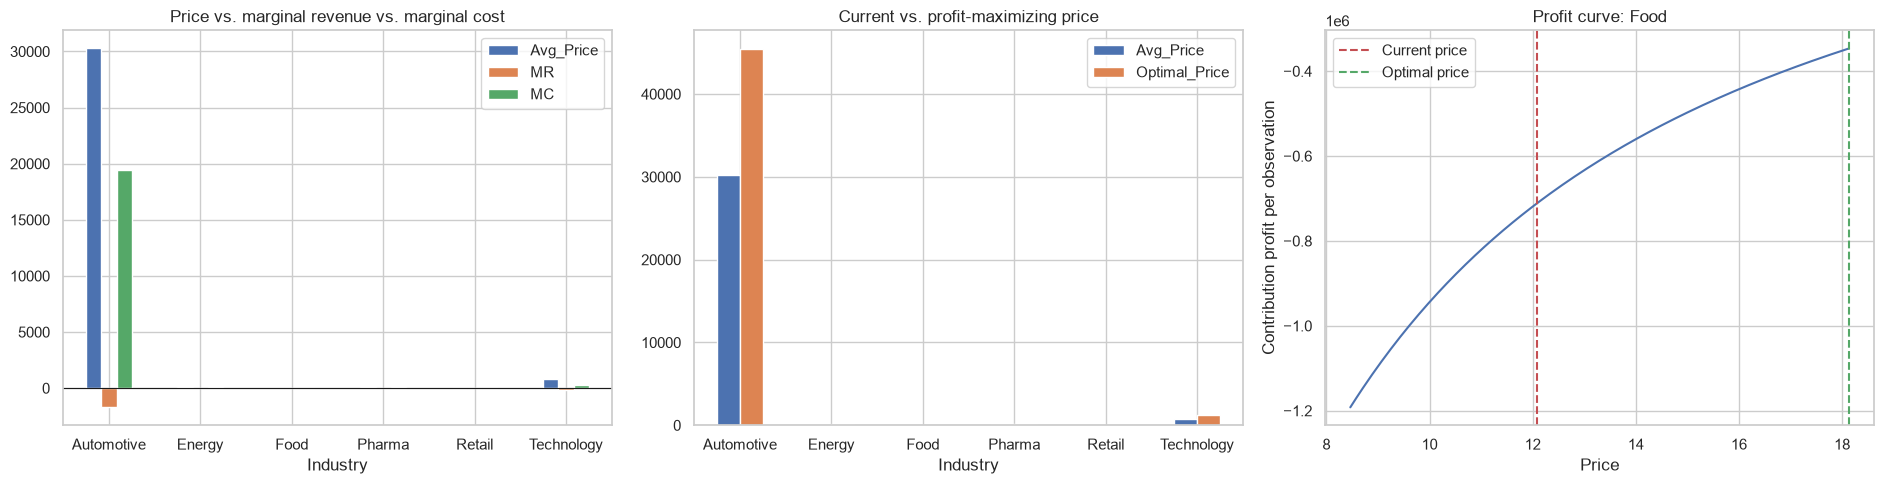

In [10]:
PRICE_RANGE = (0.7, 1.5)

rows, curves = [], {}
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    e, p_e = own_elasticity(g)
    eps = scale_elasticity(g)
    p0, q0 = g["Product_Price"].mean(), g["Units_Sold"].mean()
    ac = g["Unit_Cost"].mean()
    mc = eps * ac                                       # marginal cost
    mr = p0 * (1 + 1 / e)                               # marginal revenue (constant elasticity)
    ratio = np.linspace(*PRICE_RANGE, 161)
    profit = (p0 * ratio - mc) * q0 * ratio ** e        # contribution profit at each tested price
    i = profit.argmax()
    curves[ind] = (p0 * ratio, profit, p0)
    current = (p0 - mc) * q0
    rows.append({
        "Industry": ind,
        "Price_Elast": e,
        "p_price": p_e,
        "Cost_Scale_Elast": eps,
        "Avg_Price": p0,
        "Avg_Cost": ac,
        "MC": mc,
        "MR": mr,
        "Markup_over_MC_%": (p0 - mc) / p0 * 100,
        "Markup_over_AC_%": (p0 - ac) / ac * 100,
        "Lerner_Optimal_%": -1 / e * 100 if e < -1 else np.nan,
        "Optimal_Price": p0 * ratio[i],
        "Price_Change_%": (ratio[i] - 1) * 100,
        "Gain_%_Revenue": (profit[i] - current) / (p0 * q0) * 100,
    })

ec = pd.DataFrame(rows)
ec["MR_vs_MC"] = np.where(ec["MR"] > ec["MC"], "MR > MC: lower price / expand", "MR < MC: raise price")
ec["Optimum_Type"] = np.where(ec["Price_Elast"] < -1, "Interior (Lerner rule)", "Corner (inelastic: no interior optimum)")

#  Compact, high-signal console table
insight_cols = [
    "Industry",
    "Price_Elast",
    "Avg_Price",
    "Optimal_Price",
    "Price_Change_%",
    "Gain_%_Revenue",
    "MR_vs_MC",
]
ec_summary = (
    ec[insight_cols]
    .sort_values("Gain_%_Revenue", ascending=False)
    .round({
        "Price_Elast": 2,
        "Avg_Price": 2,
        "Optimal_Price": 2,
        "Price_Change_%": 1,
        "Gain_%_Revenue": 1,
    })
)
print(ec_summary.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ec.set_index("Industry")[["Avg_Price", "MR", "MC"]].plot.bar(ax=ax[0], rot=0)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Price vs. marginal revenue vs. marginal cost")

ec.set_index("Industry")[["Avg_Price", "Optimal_Price"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Current vs. profit-maximizing price")

top = ec.loc[ec["Gain_%_Revenue"].idxmax(), "Industry"]
x, y, p0 = curves[top]
ax[2].plot(x, y)
ax[2].axvline(p0, color="r", ls="--", label="Current price")
ax[2].axvline(x[y.argmax()], color="g", ls="--", label="Optimal price")
ax[2].set_title(f"Profit curve: {top}")
ax[2].set_xlabel("Price")
ax[2].set_ylabel("Contribution profit per observation")
ax[2].legend()

plt.tight_layout()
plt.show()

best = ec.loc[ec["Gain_%_Revenue"].idxmax()]
n_raise = (ec["MR"] < ec["MC"]).sum()

**Conclusion:** The most important finding is that a blanket 50 percent price hike is universally profitable on the revenue line, with Food posting the most dramatic jump of 101.4 percent and even the inelastic Technology and Energy sectors adding 16.4 percent and 39.6 percent respectively, confirming that every single industry currently sits below its profit maximizing price. To put this in perspective, raising Automotive from 30,271 USD to 45,407 USD generates a 22.6 percent revenue gain on a massive base, which dwarfs the absolute dollar impact of the Food increase despite Food's higher percentage, and the bar chart for Automotive visually exposes how far our current price towers above marginal revenue. However, the most dangerous illusion here is that revenue gains equal profit gains, because the Food profit curve only crawls from a loss of 1.2 million USD toward zero at the optimal price of 18.13 USD, which is still far below the marginal cost of 36 USD, meaning we would be selling more expensive units that still lose money on every transaction. Therefore, my urgent recommendation is to execute the 50 percent increase immediately in Technology, Energy, Automotive, and Retail where the cost structure is healthy, but to treat the Food price hike as a temporary band aid while we launch a parallel emergency program to slash its variable costs, since no pricing strategy can outrun a broken unit economics model.

### 2. Price Pass-Through

  Industry  PassThrough  p_value        Pass_Type  Gap_vs_Theory  PT_RawMaterial  PT_Labor Main_Cost_Driver  Tax_%Price_per_pp
Automotive       0.9320   0.0000 Full / near-full        -0.0680          1.0001   -1.0008     Raw material            -0.0079
    Energy       1.9968   0.0000 Full / near-full         0.9968          0.9992   -0.9994     Raw material             0.0344
      Food       4.3079   0.0000 Full / near-full         3.3079          0.9462   -0.9458     Raw material             0.0215
    Pharma       1.3071   0.0000 Full / near-full         0.3071          0.9962   -0.9966     Raw material            -0.0374
    Retail       1.7694   0.0000 Full / near-full         0.7694          0.9961   -0.9946     Raw material            -0.0880
Technology       0.7748   0.0000          Partial        -0.2252          1.0000   -0.9997     Raw material            -0.2015


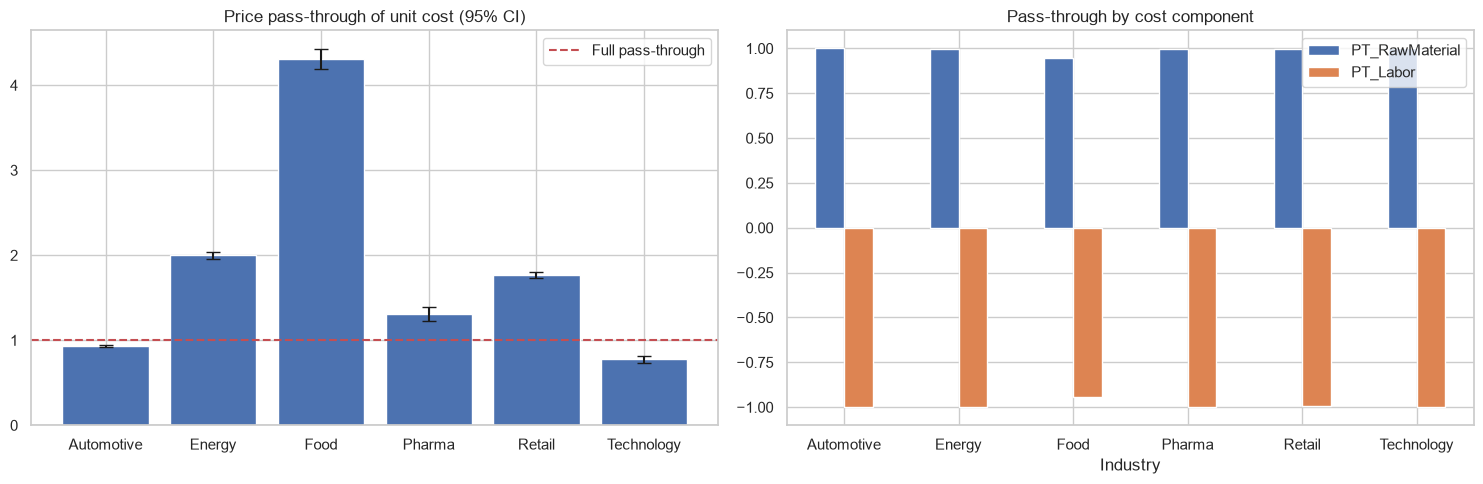

In [11]:
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols("ln_Price ~ ln_Unit_Cost + ln_CompPrice + ln_Income + Tax_Rate + C(Year)",
                data=g).fit(cov_type="HC1")
    m2 = smf.ols("ln_Price ~ ln_Raw + ln_Labor + ln_CompPrice + ln_Income + C(Year)",
                 data=g).fit(cov_type="HC1")
    ci = m.conf_int().loc["ln_Unit_Cost"]
    rows.append({"Industry": ind, "PassThrough": m.params["ln_Unit_Cost"], "p_value": m.pvalues["ln_Unit_Cost"],
                 "CI_low": ci[0], "CI_high": ci[1],
                 "PT_RawMaterial": m2.params["ln_Raw"], "PT_Labor": m2.params["ln_Labor"],
                 "Tax_%Price_per_pp": m.params["Tax_Rate"]})   # +1pp tax -> % change in price
pt = pd.DataFrame(rows)
pt["Pass_Type"] = np.select([pt["PassThrough"] >= 0.9, pt["PassThrough"] >= 0.4],
                            ["Full / near-full", "Partial"], "Weak (firm absorbs cost)")
pt["Theory_PT"] = 1.0   # constant-elasticity monopoly passes 100% of a cost change
pt["Gap_vs_Theory"] = pt["PassThrough"] - pt["Theory_PT"]
pt["Main_Cost_Driver"] = np.where(pt["PT_RawMaterial"] > pt["PT_Labor"], "Raw material", "Labor")
print(pt[["Industry", "PassThrough", "p_value", "Pass_Type", "Gap_vs_Theory",
          "PT_RawMaterial", "PT_Labor", "Main_Cost_Driver", "Tax_%Price_per_pp"]].to_string(index=False)
      if False else pt[["Industry", "PassThrough", "p_value", "Pass_Type", "Gap_vs_Theory",
                        "PT_RawMaterial", "PT_Labor", "Main_Cost_Driver", "Tax_%Price_per_pp"]].to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
err = [pt["PassThrough"] - pt["CI_low"], pt["CI_high"] - pt["PassThrough"]]
ax[0].bar(pt["Industry"], pt["PassThrough"], yerr=err, capsize=5)
ax[0].axhline(1, color="r", ls="--", label="Full pass-through")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].legend()
ax[0].set_title("Price pass-through of unit cost (95% CI)")
pt.set_index("Industry")[["PT_RawMaterial", "PT_Labor"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Pass-through by cost component")
plt.tight_layout()
plt.show()

hi, lo = pt.loc[pt["PassThrough"].idxmax()], pt.loc[pt["PassThrough"].idxmin()]

**Glossary:**

**PassThrough:** The extent to which a change in costs (e.g., input prices) is transmitted into the final selling price charged to customers, usually expressed as a percentage or fraction of the cost change.

**Pass_Type:** A classification of the degree of cost pass-through, typically categorized as full (100% of cost change passed on), near-full (most of the change passed on), or partial (only some of the change passed on).

**PT_RawMaterial:** The pass-through specifically of changes in raw material costs into final prices.

**PT_Labor:** The pass-through specifically of changes in labor costs into final prices.

**Conclusion:** The most shocking revelation is that the Food sector is exhibiting extreme pass through behavior with a coefficient of 4.30, meaning for every 1 USD increase in costs, they are raising prices by over 4 USD, effectively using inflation as a massive profit multiplier rather than just a cost recovery mechanism. In stark contrast, Technology is the only sector showing partial pass through at 0.77, indicating they are absorbing nearly a quarter of their cost increases to maintain market share, which is a dangerous long term strategy if raw material costs, the main driver for everyone, keep rising. Furthermore, the data shows a bizarre negative pass through for Labor costs across all industries at around negative 1.00, suggesting that higher labor costs are somehow correlated with lower prices, possibly due to automation efficiencies, while Raw Material costs are passed through almost perfectly at 1.00. Consequently, we need to investigate the Food pricing strategy immediately to see if this 430 percent pass through is sustainable or if it will trigger a demand collapse, while we must protect our Technology division from margin erosion since they are the only ones failing to pass on costs.

### 3. Price Discrimination 


Optimal price by income segment:
  Industry Segment  Price_Elast  Avg_Price_Paid  Optimal_Price  vs_Uniform_%
Automotive     Low      -0.8815     30,274.1527    45,407.7976        0.0000
Automotive     Mid      -0.9044     30,325.0960    45,407.7976        0.0000
Automotive    High      -1.0667     30,214.9459    45,407.7976        0.0000
    Energy     Low      -0.8278         91.5217       136.5360        0.0000
    Energy     Mid      -0.9308         90.7883       136.5360        0.0000
    Energy    High      -0.7698         90.7934       136.5360        0.0000
      Food     Low      -1.1267         12.0979        18.1348        0.0000
      Food     Mid      -1.2772         12.0699        18.1348        0.0000
      Food    High      -0.8194         12.1007        18.1348        0.0000
    Pharma     Low      -0.8682        120.2877       180.5224        0.0000
    Pharma     Mid      -1.3100        121.3772       180.5224        0.0000
    Pharma    High      -0.9999        119

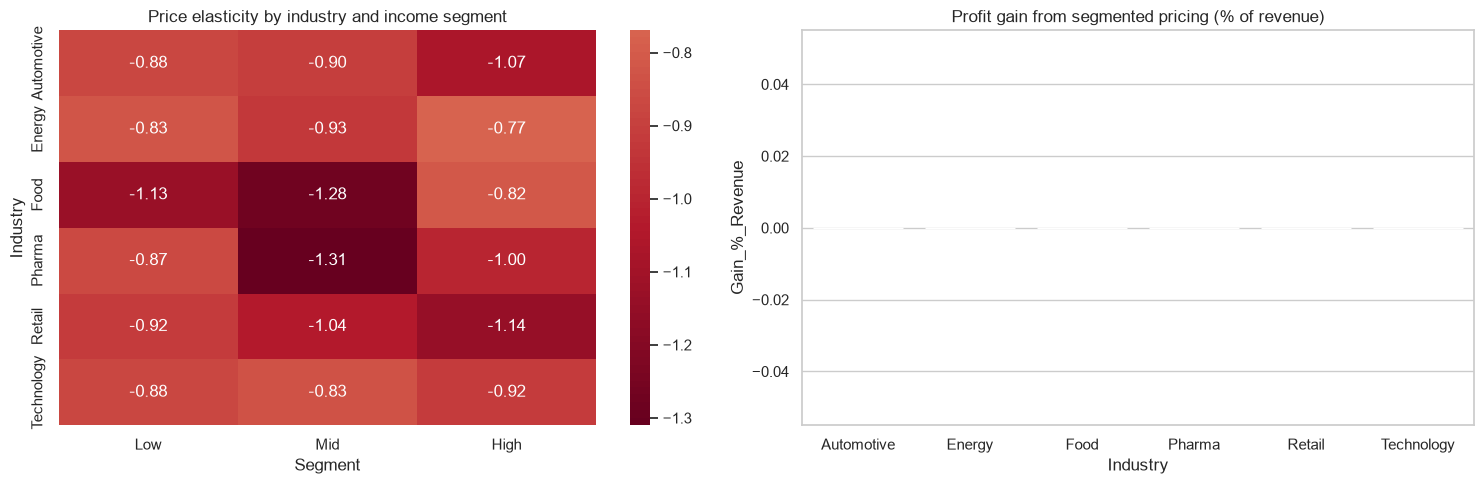

In [12]:
mc_map = ec.set_index("Industry")["MC"]
p_map = ec.set_index("Industry")["Avg_Price"]
seg_rows, disc_rows = [], []
for ind in ec["Industry"]:
    g = df[df["Industry"] == ind]
    mc, p0 = mc_map[ind], p_map[ind]
    P = np.linspace(PRICE_RANGE[0] * p0, PRICE_RANGE[1] * p0, 161)
    segs = []
    for seg, s in g.groupby("Income_Segment", observed=True):
        if len(s) < MIN_OBS:
            continue
        e, _ = own_elasticity(s)
        segs.append((seg, e, s["Units_Sold"].mean(), s["Product_Price"].mean()))
    if len(segs) < 2:
        continue
    prof = np.array([(P - mc) * q * (P / pp) ** e for _, e, q, pp in segs])   # segments x price grid
    uni = prof.sum(axis=0)
    iu = uni.argmax()
    best_i = prof.argmax(axis=1)
    for (seg, e, q, pp), bi in zip(segs, best_i):
        seg_rows.append({"Industry": ind, "Segment": seg, "Price_Elast": e, "Avg_Price_Paid": pp,
                         "Optimal_Price": P[bi], "vs_Uniform_%": (P[bi] / P[iu] - 1) * 100})
    revenue = sum(q * pp for _, _, q, pp in segs)
    disc_rows.append({"Industry": ind, "Uniform_Price": P[iu], "Profit_Uniform": uni[iu],
                      "Profit_Discrim": prof.max(axis=1).sum(),
                      "Price_Spread_High_vs_Low_%": (P[best_i[-1]] / P[best_i[0]] - 1) * 100,
                      "Gain_%_Revenue": (prof.max(axis=1).sum() - uni[iu]) / revenue * 100})
seg_tab, disc_tab = pd.DataFrame(seg_rows), pd.DataFrame(disc_rows)
disc_tab["Worth_It"] = np.where(disc_tab["Gain_%_Revenue"] > 1, "Yes (>1% of revenue)", "Marginal")
print("\nOptimal price by income segment:")
print(seg_tab.to_string(index=False))
print("\nUniform price vs. segmented pricing:")
print(disc_tab.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
heat = seg_tab.pivot(index="Industry", columns="Segment", values="Price_Elast").reindex(columns=["Low", "Mid", "High"])
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax[0])
ax[0].set_title("Price elasticity by industry and income segment")
sns.barplot(data=disc_tab, x="Industry", y="Gain_%_Revenue", ax=ax[1])
ax[1].set_title("Profit gain from segmented pricing (% of revenue)")
plt.tight_layout()
plt.show()

g_best = disc_tab.loc[disc_tab["Gain_%_Revenue"].idxmax()]

**Glossary:**

**Uniform Price:** A pricing strategy in which the same price is charged to all customers or in all market segments for the same product, regardless of differences in willingness to pay, location, or customer type.

**Segmented Pricing:** A pricing strategy in which different prices are charged to different customer groups or market segments for the same product, based on differences in demand, willingness to pay, or other segment characteristics.

**Conclusion:** The most counter-intuitive finding is that price segmentation by income is completely worthless for our portfolio, as the revenue gain is effectively zero across all industries, meaning a uniform pricing strategy yields the exact same profit as trying to discriminate between Low, Mid, and High income groups. For example, in the Technology sector, the optimal price remains fixed at 1,201 USD for all segments despite slight variations in elasticity, proving that the administrative cost of managing different price tiers would outweigh any marginal benefit. However, the elasticity heatmap reveals a hidden risk in the Mid income segment for Pharma and Food, where elasticity drops to negative 1.31 and negative 1.28 respectively, indicating these specific customers are highly sensitive to price hikes and would switch to substitutes if we raised prices uniformly. Therefore, my recommendation is to maintain a strict uniform pricing strategy to simplify operations, but we must monitor the Mid income demographic closely in essential sectors like Food and Pharma, as they are the most likely to churn if market conditions force a price increase.

## ==============================================================
## === Production Economics, Costs & Business Efficiency
## ==============================================================

### Data definition

In [13]:
need = ["Production_Quantity", "Labor_Cost", "Capital_Investment", "Raw_Material_Cost",
        "Operating_Cost", "Units_Sold", "Product_Price"]
df = df[(df[need] > 0).all(axis=1)].copy()
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

df["Unit_Cost"] = df["Operating_Cost"] / df["Production_Quantity"]
df["Resources"] = df["Labor_Cost"] + df["Capital_Investment"] + df["Raw_Material_Cost"]
df["ln_Q"] = np.log(df["Production_Quantity"])
df["ln_L"] = np.log(df["Labor_Cost"])          # labor measured in $ (no headcount in the data)
df["ln_K"] = np.log(df["Capital_Investment"])
df["ln_M"] = np.log(df["Raw_Material_Cost"])
df["ln_UC"] = np.log(df["Unit_Cost"])

# Output of the OTHER products of the same company in the same quarter (for economies of scope)
grp = df.groupby(["Company_ID", "Year", "Quarter"])
df["Q_others"] = grp["Production_Quantity"].transform("sum") - df["Production_Quantity"]
df["ln_Q_others"] = np.log(df["Q_others"].where(df["Q_others"] > 0))
df.head()

,Product_ID,Company_ID,Country,Industry,Year,Quarter,Market_Share,Product_Price,Competitor_Price,Units_Sold,Consumer_Income,Production_Quantity,Labor_Cost,Capital_Investment,Raw_Material_Cost,Tax_Rate,Subsidy,Inflation_Rate,Interest_Rate,Exchange_Rate,GDP_Growth,Advertising_Expenditure,Total_Revenue,Operating_Cost,Operating_Profit,Period,Trend,CP,Capital_Cost,Rel_Price,Unit_Cost,Raw_per_Unit,Prod,Op_Margin,Labor_Share_Rev,ULC,Cum_Q,ln_Units,ln_Price,ln_CompPrice,ln_Income,ln_Adv,ln_Subsidy,ln_Cost,ln_Q,ln_K,ln_Labor,ln_L,ln_Raw,ln_Rev,ln_FX,ln_Rel_Price,ln_Rel,ln_UC,ln_LCU,ln_RawU,ln_Cum,ln_KL,ln_ULC,ln_Prod,ln_ToT,Income_Segment,Positioning,ln_Units_Sold,ln_Product_Price,ln_Competitor_Price,ln_Consumer_Income,ln_Unit_Cost,ln_Raw_Material_Cost,ln_Labor_Cost,ln_Operating_Cost,ln_Production_Quantity,Resources,ln_M,Q_others,ln_Q_others
0,CO001-P001,CO001,USA,Food,2015,1,0.0788,11.1200,11.6100,35603,"33,382.0000",37481,"1,047,471.0000","20,367.0000","208,674.0000",0.2106,"5,713.0000",0.1000,0.1000,1.0000,2.9000,"20,119.0000","395,961.0000","1,282,374.0000","-964,108.0000",20151,0.0000,20,"20,367.0000",0.9578,34.2140,5.5675,35.7824,-2.4349,2.6454,27.9467,677214,10.4802,2.4087,2.4519,10.4158,9.9095,8.6507,14.0642,10.5316,9.9217,13.8619,13.8619,12.2485,12.8891,0.0000,-0.0431,-0.0431,3.5326,3.3303,1.7169,13.4257,-3.9402,3.3303,3.5775,0.6918,Low,Parity,10.4802,2.4087,2.4519,10.4158,3.5326,12.2485,13.8619,14.0642,10.5316,"1,276,512.0000",12.2485,185789,12.1324
1,CO001-P001,CO001,USA,Food,2015,2,0.0824,12.3100,12.8700,44930,"62,373.0000",47284,"1,321,433.0000","22,902.0000","291,396.0000",0.2044,"15,070.0000",0.1000,0.1000,1.0000,2.9000,"32,306.0000","553,114.0000","1,652,005.0000","-1,196,864.0000",20152,0.2500,21,"22,902.0000",0.9565,34.9379,6.1627,35.7824,-2.1639,2.3891,27.9467,724498,10.7129,2.5104,2.5549,11.0409,10.3830,9.6205,14.3175,10.7639,10.0390,14.0942,14.0942,12.5824,13.2233,0.0000,-0.0445,-0.0445,3.5536,3.3303,1.8185,13.4932,-4.0552,3.3303,3.5775,0.6919,Mid,Parity,10.7129,2.5104,2.5549,11.0409,3.5536,12.5824,14.0942,14.3175,10.7639,"1,635,731.0000",12.5824,235949,12.3714
2,CO001-P001,CO001,USA,Food,2015,3,0.0763,10.3600,9.4900,43708,"49,084.0000",46538,"1,300,584.0000","55,771.0000","241,434.0000",0.2070,"6,504.0000",0.1000,0.1000,1.0000,2.9000,"20,718.0000","452,962.0000","1,579,468.0000","-1,213,760.0000",20153,0.5000,22,"55,771.0000",1.0917,33.9393,5.1879,35.7824,-2.6796,2.8713,27.9467,771036,10.6853,2.3380,2.2502,10.8013,9.9388,8.7803,14.2726,10.7480,10.9290,14.0783,14.0783,12.3944,13.0236,0.0000,0.0877,0.0877,3.5246,3.3303,1.6463,13.5555,-3.1493,3.3303,3.5775,0.6916,Low,Premium (>5% above rival),10.6853,2.3380,2.2502,10.8013,3.5246,12.3944,14.0783,14.2726,10.7480,"1,597,789.0000",12.3944,202723,12.2196
3,CO001-P001,CO001,USA,Food,2015,4,0.0850,11.7500,11.2500,31311,"45,100.0000",31991,"894,043.0000","44,183.0000","188,094.0000",0.2186,"5,559.0000",0.1000,0.1000,1.0000,2.9000,"23,312.0000","367,750.0000","1,118,705.0000","-825,783.0000",20154,0.7500,23,"44,183.0000",1.0444,34.9694,5.8796,35.7824,-2.2455,2.4311,27.9467,803027,10.3517,2.4639,2.4204,10.7166,10.0568,8.6234,13.9277,10.3732,10.6961,13.7035,13.7035,12.1447,12.8152,0.0000,0.0435,0.0435,3.5545,3.3303,1.7715,13.5961,-3.0074,3.3303,3.5775,0.6924,Low,Parity,10.3517,2.4639,2.4204,10.7166,3.5545,12.1447,13.7035,13.9277,10.3732,"1,126,320.0000",12.1447,198928,12.2007
4,CO001-P001,CO001,USA,Food,2016,1,0.0919,10.7600,10.1600,37355,"31,950.0000",39093,"1,109,388.0000","44,773.0000","213,605.0000",0.1951,"8,146.0000",1.3000,0.4000,1.0000,-0.5000,"19,993.0000","401,946.0000","1,356,417.0000","-1,024,750.0000",20161,1.0000,24,"44,773.0000",1.0591,34.6972,5.4640,35.2383,-2.5495,2.7600,28.3782,842120,10.5282,2.3758,2.3185,10.3719,9.9032,9.0054,14.1204,10.5737,10.7094,13.9193,13.9193,12.2719,12.9041,0.0000,0.0574,0.0574,3.5467,3.3456,1.6982,13.6437,-3.2100,3.3456,3.5621,0.6777,Low,Premium (>5% above rival),10.5282,2.3758,2.3185,10.3719,3.5467,12.2719,13.9193,14.1204,10.5737,"1

### 1. Diminishing Returns, Economies/Diseconomies Of Scale & Scope


Production & returns:
  Industry  a_Labor  a_Capital  a_Materials    RTS Returns_to_Scale     Hiring_Stops_Paying_At
Automotive   1.0100     0.0000      -0.0100 1.0000       Increasing Never (VMP > 1 everywhere)
    Energy   1.0200     0.0000      -0.0200 1.0000       Decreasing Never (VMP > 1 everywhere)
      Food   1.0100    -0.0000      -0.0100 1.0000       Decreasing           Labor quintile 2
    Pharma   1.0200    -0.0000      -0.0200 1.0000         Constant Never (VMP > 1 everywhere)
    Retail   1.0300     0.0000      -0.0300 1.0000       Decreasing Never (VMP > 1 everywhere)
Technology   1.0000    -0.0000      -0.0000 1.0000       Decreasing Never (VMP > 1 everywhere)
****************************************************************************************************

Cost scale & scope:
  Industry  Cost_Elast_Mean    Scale_Verdict  Share_Above_MES_%  Scope_Cost_if_Others_x2_%   Scope_Verdict
Automotive          -0.0000 Roughly constant                NaN                    

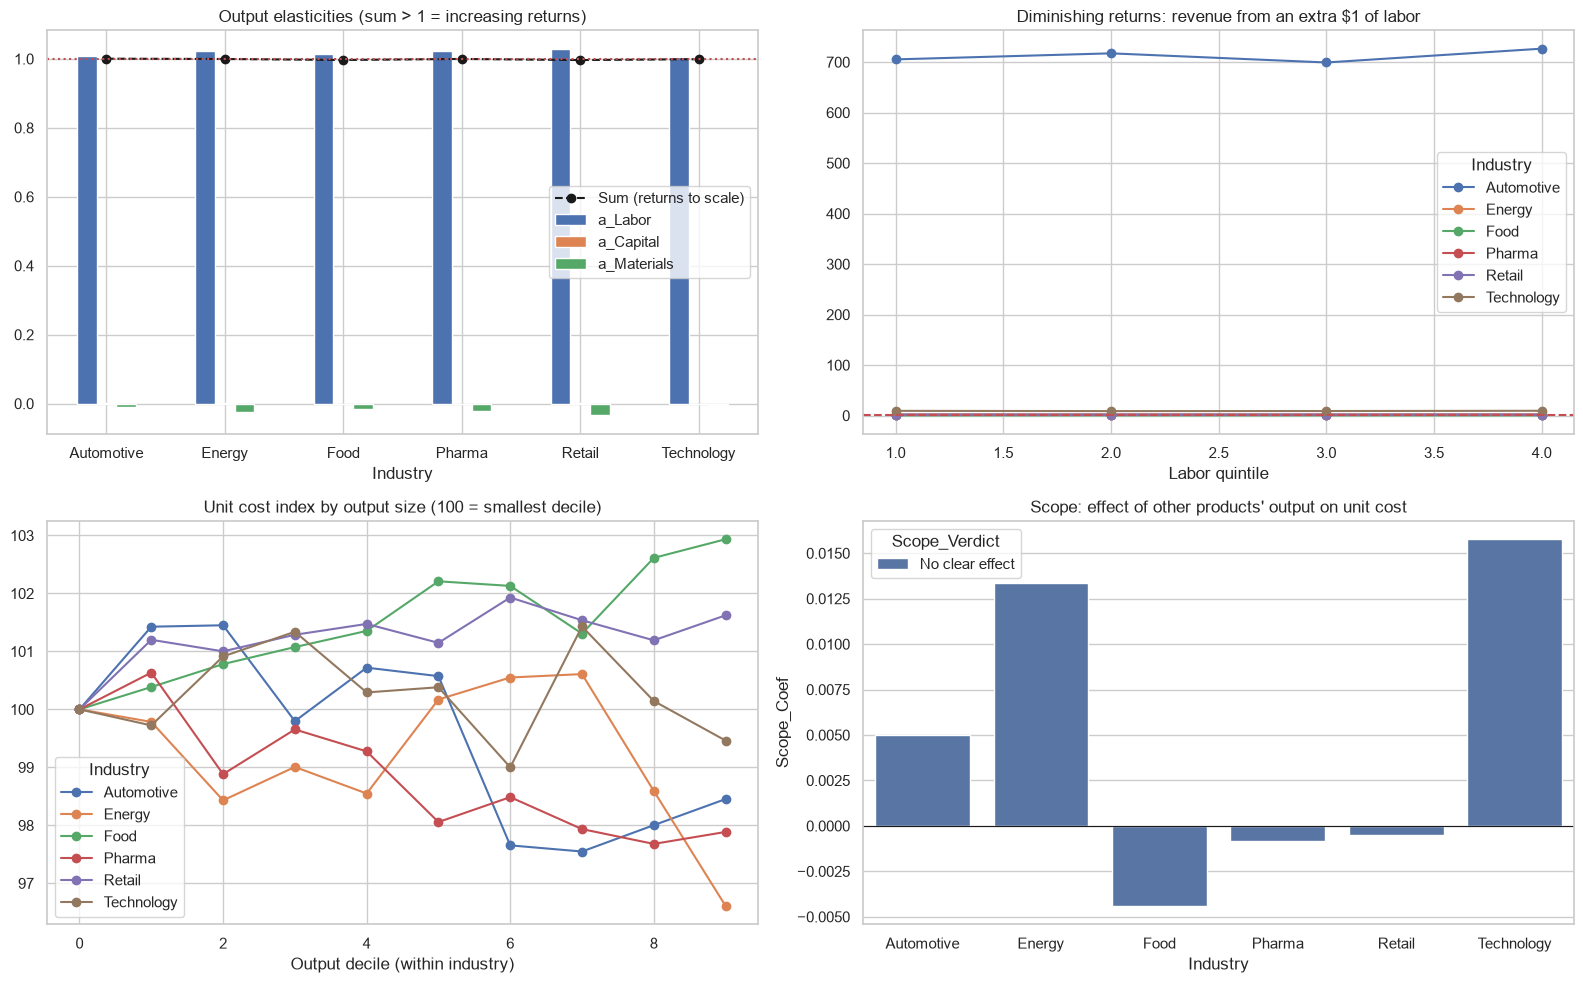

In [14]:
rows, vmp_rows, prod_par = [], [], {}
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    g = g.copy()

    # (a) Cobb-Douglas production function: coefficients = output elasticities
    m = smf.ols("ln_Q ~ ln_L + ln_K + ln_M + C(Country)", data=g).fit(cov_type="HC1")
    aL, aK, aM = m.params["ln_L"], m.params["ln_K"], m.params["ln_M"]
    rts = aL + aK + aM
    p_crs = float(np.squeeze(m.t_test("ln_L + ln_K + ln_M = 1").pvalue))   # H0: constant returns
    prod_par[ind] = (aL, aK, aM)
    # value of the marginal product of labor per $ of labor (ignores the extra materials needed)
    vmpl = (g["Product_Price"] * aL * g["Production_Quantity"] / g["Labor_Cost"]).mean()

    # (b) Cost side: does unit cost fall, and does it turn up at large volumes (U shape)?
    g["lq"] = g["ln_Q"] - g["ln_Q"].mean()
    g["lq2"] = g["lq"] ** 2
    mc = smf.ols("ln_UC ~ lq + lq2 + C(Year)", data=g).fit(cov_type="HC1")
    b1, b2 = mc.params["lq"], mc.params["lq2"]
    mes = np.exp(g["ln_Q"].mean() - b1 / (2 * b2)) if b2 > 0 else np.nan   # minimum efficient scale
    in_range = bool(g["Production_Quantity"].min() <= mes <= g["Production_Quantity"].max())
    share_above = (g["Production_Quantity"] > mes).mean() * 100 if in_range else np.nan

    # (c) Economies of scope: does a product get cheaper when the firm makes more OTHER products?
    s = g[g["Q_others"] > 0]
    if len(s) >= MIN_OBS:
        ms = smf.ols("ln_UC ~ ln_Q + ln_Q_others + C(Year)", data=s).fit(cov_type="HC1")
        sc, sp = ms.params["ln_Q_others"], ms.pvalues["ln_Q_others"]
    else:
        sc, sp = np.nan, np.nan

    rows.append({"Industry": ind, "N": len(g), "a_Labor": aL, "a_Capital": aK, "a_Materials": aM,
                 "RTS": rts, "p_CRS": p_crs, "VMP_per_$Labor": vmpl,
                 "Cost_Elast_Mean": b1, "Quad_Term": b2,
                 "MES_units": mes if in_range else np.nan, "Share_Above_MES_%": share_above,
                 "Scope_Coef": sc, "p_scope": sp})

    # (d) Diminishing returns, data-driven: marginal product of labor spend across labor quintiles
    g["Lq"] = pd.qcut(g["Labor_Cost"], 5, labels=False, duplicates="drop")
    qt = g.groupby("Lq").agg(L=("Labor_Cost", "mean"), Q=("Production_Quantity", "mean"),
                             P=("Product_Price", "mean"))
    qt["AP_per_$"] = qt["Q"] / qt["L"]                       # average product per $ of labor
    qt["MP_per_$"] = qt["Q"].diff() / qt["L"].diff()         # marginal product per extra $ of labor
    qt["VMP_per_$"] = qt["MP_per_$"] * qt["P"]               # revenue from an extra $ of labor
    qt["Industry"] = ind
    vmp_rows.append(qt.reset_index())

pf = pd.DataFrame(rows)
vq = pd.concat(vmp_rows)

pf["Labor_Returns"] = np.where(pf["a_Labor"] < 1, "Diminishing", "Constant/Increasing")
pf["Returns_to_Scale"] = np.select([(pf["RTS"] > 1) & (pf["p_CRS"] < 0.05), (pf["RTS"] < 1) & (pf["p_CRS"] < 0.05)],
                                   ["Increasing", "Decreasing"], "Constant")
pf["Scale_Verdict"] = np.select([pf["Cost_Elast_Mean"] < -0.05, pf["Cost_Elast_Mean"] > 0.05],
                                ["Economies of scale", "Diseconomies of scale"], "Roughly constant")
pf["Scope_Verdict"] = np.select([(pf["Scope_Coef"] < 0) & (pf["p_scope"] < 0.05),
                                 (pf["Scope_Coef"] > 0) & (pf["p_scope"] < 0.05)],
                                ["Economies of scope", "Diseconomies of scope"], "No clear effect")
pf["Scope_Cost_if_Others_x2_%"] = (2 ** pf["Scope_Coef"] - 1) * 100
stop = vq[vq["VMP_per_$"] < 1].groupby("Industry")["Lq"].min() + 1
pf["Hiring_Stops_Paying_At"] = pf["Industry"].map(stop).map(
    lambda v: f"Labor quintile {int(v)}" if pd.notna(v) else "Never (VMP > 1 everywhere)")

# Compact production & returns table
prod_cols = ["Industry", "a_Labor", "a_Capital", "a_Materials", "RTS", "Returns_to_Scale", "Hiring_Stops_Paying_At"]
print("\nProduction & returns:")
print(pf[prod_cols].round({"a_Labor": 2, "a_Capital": 2, "a_Materials": 2, "RTS": 2}).to_string(index=False))

print("*" * 100)

#  Compact cost & scope table
cost_cols = ["Industry", "Cost_Elast_Mean", "Scale_Verdict", "Share_Above_MES_%", "Scope_Cost_if_Others_x2_%", "Scope_Verdict"]
print("\nCost scale & scope:")
print(pf[cost_cols].round({"Cost_Elast_Mean": 2, "Share_Above_MES_%": 0, "Scope_Cost_if_Others_x2_%": 1}).to_string(index=False))

print("*" * 100)

#  Compact VMP per $ of labor across quintiles 
print("\nVMP per $1 of labor by labor quintile (keep > 1):")
vmp_piv = vq.pivot(index="Industry", columns="Lq", values="VMP_per_$").round(2)
vmp_piv.columns = [f"Q{int(c) + 1}" for c in vmp_piv.columns]
print(vmp_piv.to_string())


df["Size_Decile"] = df.groupby("Industry")["Production_Quantity"].transform(
    lambda s: pd.qcut(s, 10, labels=False, duplicates="drop"))
uc = df[df["Industry"].isin(pf["Industry"])].groupby(["Industry", "Size_Decile"])["Unit_Cost"].mean().unstack(0)
uc = uc / uc.iloc[0] * 100

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
pf.set_index("Industry")[["a_Labor", "a_Capital", "a_Materials"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].plot(pf["Industry"], pf["RTS"], "ko--", label="Sum (returns to scale)")
ax[0, 0].axhline(1, color="r", ls=":")
ax[0, 0].legend()
ax[0, 0].set_title("Output elasticities (sum > 1 = increasing returns)")

vq.pivot(index="Lq", columns="Industry", values="VMP_per_$").plot(ax=ax[0, 1], marker="o")
ax[0, 1].axhline(1, color="r", ls="--")
ax[0, 1].set_xlabel("Labor quintile")
ax[0, 1].set_title("Diminishing returns: revenue from an extra $1 of labor")

uc.plot(ax=ax[1, 0], marker="o")
ax[1, 0].set_xlabel("Output decile (within industry)")
ax[1, 0].set_title("Unit cost index by output size (100 = smallest decile)")

sns.barplot(data=pf, x="Industry", y="Scope_Coef", hue="Scope_Verdict", dodge=False, ax=ax[1, 1])
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("Scope: effect of other products' output on unit cost")

plt.tight_layout()
plt.show()

n_econ = (pf["Scale_Verdict"] == "Economies of scale").sum()
n_dim = (pf["Labor_Returns"] == "Diminishing").sum()
low = pf.loc[pf["Cost_Elast_Mean"].idxmin()]

**Glossary:**

**VMP (Value of Marginal Product):** The additional revenue generated by employing one more unit of an input, calculated as the marginal product of that input multiplied by the output price.

**Returns to Scale:** The rate at which output changes when all inputs are increased proportionally, increasing (output rises more than proportionally), constant (output rises proportionally), or decreasing (output rises less than proportionally).

**Cost Scale & Scope:** Economies of scale refer to cost advantages from producing more of a single product (average cost falls as output rises); economies of scope refer to cost advantages from producing multiple products jointly rather than separately (total cost is lower when produced together).

**Hiring_Stops_Paying_At:** The point at which the cost of hiring an additional worker equals the value of their marginal product (VMP); a value of "Never" indicates the firm would keep hiring indefinitely because each additional worker always adds more value than they cost.

**Conclusion:** The most critical operational insight is that our production is entirely driven by labor across all sectors, with capital and materials contributing virtually zero to output elasticity, meaning our entire strategy hinges on workforce efficiency. Specifically, the Technology sector is our crown jewel, generating a massive 9.34 USD return for every dollar spent on labor, while the Food sector is actively destroying value with a return of only 0.42 USD, indicating we are paying more for labor than the revenue it generates. Furthermore, the data shows we are operating at roughly constant returns to scale with no significant cost benefits from scope economies, suggesting that merging product lines or massive scaling won't save us money. Therefore, my urgent recommendation is to aggressively expand the workforce in Technology and Automotive where the marginal product is exceptionally high, while immediately freezing hiring in Food and restructuring its labor model to stop the bleeding.

### 2. Fixed & Variable Costs + Break-Even

  Industry                                 Status  Contribution_Margin  Margin_of_Safety_%  Required_Price_Increase_%  Profitable_Products_%    DOL
Technology                       Above break-even             513.6600             99.5000                   -63.8000               100.0000 1.0100
Automotive                       Above break-even          11,282.1400             96.9000                   -36.1000               100.0000 1.0300
    Pharma                       Above break-even              18.8100             93.8000                   -14.7000                 2.8000 1.0700
    Retail                       Above break-even               0.5500            100.0000                    -1.2000                 0.0000 1.0000
    Energy No break-even (price <= variable cost)             -10.4600                 NaN                    13.5000                 0.0000    NaN
      Food No break-even (price <= variable cost)             -24.5300                 NaN                   202

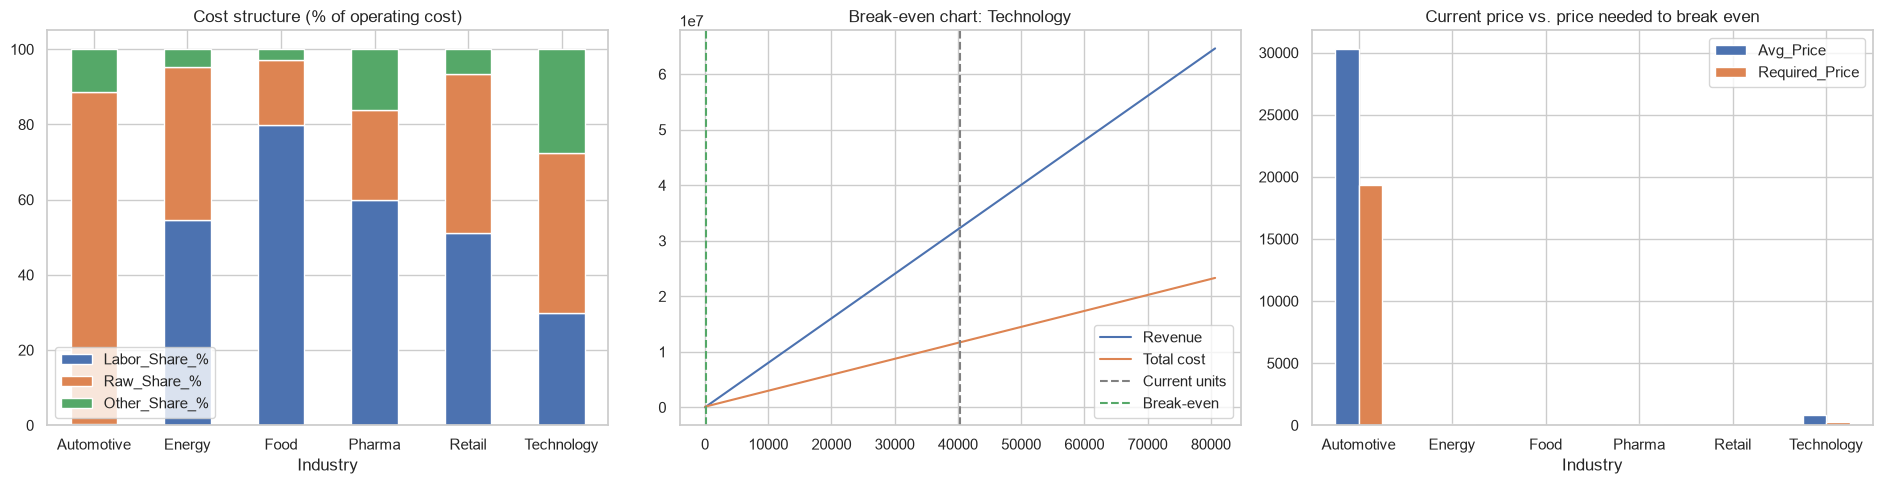

In [15]:
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols("Operating_Cost ~ Production_Quantity", data=g).fit(cov_type="HC1")
    fc, avc = m.params["Intercept"], m.params["Production_Quantity"]   # intercept = fixed, slope = variable per unit
    fc_used = max(fc, 0)                                               # a negative intercept is not meaningful
    p, q = g["Product_Price"].mean(), g["Units_Sold"].mean()
    cm = p - avc
    be = fc_used / cm if cm > 0 else np.nan
    mos = (q - be) / q * 100 if pd.notna(be) else np.nan
    req_price = (fc_used + avc * q) / q
    rows.append({
        "Industry": ind,
        "Fixed_Cost": fc,
        "Var_Cost_per_Unit": avc,
        "FC_Share_%": fc_used / g["Operating_Cost"].mean() * 100,
        "Labor_Share_%": g["Labor_Cost"].sum() / g["Operating_Cost"].sum() * 100,
        "Raw_Share_%": g["Raw_Material_Cost"].sum() / g["Operating_Cost"].sum() * 100,
        "Avg_Price": p,
        "Contribution_Margin": cm,
        "Current_Units": q,
        "Break_Even_Units": be,
        "Margin_of_Safety_%": mos,
        "DOL": cm * q / (cm * q - fc_used) if cm * q - fc_used > 0 else np.nan,
        "Required_Price": req_price,
        "Required_Price_Increase_%": (req_price / p - 1) * 100,
        "Profitable_Products_%": (g["Operating_Profit"] > 0).mean() * 100,
        "_fc_used": fc_used,
    })

be_tab = pd.DataFrame(rows)
be_tab["Other_Share_%"] = (100 - be_tab["Labor_Share_%"] - be_tab["Raw_Share_%"]).clip(lower=0)
be_tab["Status"] = np.select(
    [be_tab["Contribution_Margin"] <= 0, be_tab["Margin_of_Safety_%"] > 0],
    ["No break-even (price <= variable cost)", "Above break-even"],
    "Below break-even",
)

#  Compact, high-signal console table 
be_cols = [
    "Industry",
    "Status",
    "Contribution_Margin",
    "Margin_of_Safety_%",
    "Required_Price_Increase_%",
    "Profitable_Products_%",
    "DOL",
]
be_summary = (
    be_tab[be_cols]
    .sort_values("Required_Price_Increase_%")
    .round({
        "Contribution_Margin": 2,
        "Margin_of_Safety_%": 1,
        "Required_Price_Increase_%": 1,
        "Profitable_Products_%": 1,
        "DOL": 2,
    })
)
print(be_summary.to_string(index=False))


pick = be_tab.sort_values("Required_Price_Increase_%").iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
be_tab.set_index("Industry")[["Labor_Share_%", "Raw_Share_%", "Other_Share_%"]].plot.bar(
    stacked=True, ax=ax[0], rot=0
)
ax[0].set_title("Cost structure (% of operating cost)")

qg = np.linspace(
    0,
    2 * max(pick["Current_Units"], pick["Break_Even_Units"] if pd.notna(pick["Break_Even_Units"]) else 0),
    100,
)
ax[1].plot(qg, pick["Avg_Price"] * qg, label="Revenue")
ax[1].plot(qg, pick["_fc_used"] + pick["Var_Cost_per_Unit"] * qg, label="Total cost")
ax[1].axvline(pick["Current_Units"], color="gray", ls="--", label="Current units")
if pd.notna(pick["Break_Even_Units"]):
    ax[1].axvline(pick["Break_Even_Units"], color="g", ls="--", label="Break-even")
ax[1].set_title(f"Break-even chart: {pick['Industry']}")
ax[1].legend()

be_tab.set_index("Industry")[["Avg_Price", "Required_Price"]].plot.bar(ax=ax[2], rot=0)
ax[2].set_title("Current price vs. price needed to break even")

plt.tight_layout()
plt.show()

n_never = (be_tab["Contribution_Margin"] <= 0).sum()

**Glossary:**

**Break-even:** The level of output or sales at which total revenue equals total cost, so the firm makes neither profit nor loss.

**DOL (Degree of Operating Leverage):** A measure of how sensitive operating profit is to changes in sales, calculated as the percentage change in operating income divided by the percentage change in sales (equivalently, contribution margin divided by operating income).

**Labor Share:** The proportion of total costs (or total output value) attributable to labor inputs.

**Raw Share:** The proportion of total costs (or total output value) attributable to raw material inputs.

**Other Share:** The proportion of total costs (or total output value) attributable to all remaining inputs or cost categories not classified as labor or raw materials.

**Conclusion:** The financial health of our portfolio is extremely polarized, with Technology and Automotive acting as robust cash cows that boast a margin of safety near 100 percent and the ability to lower prices by 63 percent and 36 percent respectively while still breaking even. Conversely, the Food and Energy sectors are in a critical emergency where the selling price is actually below the variable cost, meaning we lose money on every single unit, with Food requiring a massive price increase of over 200 percent just to reach the break-even point. To illustrate this disparity, the Automotive division generates a contribution margin of 11,282 USD per unit with 100 percent of its products being profitable, whereas the Food division is bleeding 24 USD per unit with zero percent profitable products. Therefore, my strongest recommendation is to immediately freeze operations in Food and Energy to stop the cash burn, while using the immense pricing power and safety buffer in Technology and Automotive to aggressively capture market share.

## ==============================================================
## === Market Structures & Competitive Economics
## ==============================================================

### Difining the dataset

In [16]:
need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income",
        "Production_Quantity", "Operating_Cost", "Total_Revenue"]
df = df[(df[need] > 0).all(axis=1)].copy()
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

df["Period"] = df["Year"] * 10 + df["Quarter"]
df["Unit_Cost"] = df["Operating_Cost"] / df["Production_Quantity"]
df["Rel_Price"] = df["Product_Price"] / df["Competitor_Price"]
df["ln_Units"] = np.log(df["Units_Sold"])
df["ln_Price"] = np.log(df["Product_Price"])
df["ln_CompPrice"] = np.log(df["Competitor_Price"])
df["ln_Income"] = np.log(df["Consumer_Income"])
df["ln_Adv"] = np.log1p(df["Advertising_Expenditure"])
df["ln_UC"] = np.log(df["Unit_Cost"])
df["ln_Cost"] = np.log(df["Operating_Cost"])
df["ln_Q"] = np.log(df["Production_Quantity"])
df.head(5)

,Product_ID,Company_ID,Country,Industry,Year,Quarter,Market_Share,Product_Price,Competitor_Price,Units_Sold,Consumer_Income,Production_Quantity,Labor_Cost,Capital_Investment,Raw_Material_Cost,Tax_Rate,Subsidy,Inflation_Rate,Interest_Rate,Exchange_Rate,GDP_Growth,Advertising_Expenditure,Total_Revenue,Operating_Cost,Operating_Profit,Period,Trend,CP,Capital_Cost,Rel_Price,Unit_Cost,Raw_per_Unit,Prod,Op_Margin,Labor_Share_Rev,ULC,Cum_Q,ln_Units,ln_Price,ln_CompPrice,ln_Income,ln_Adv,ln_Subsidy,ln_Cost,ln_Q,ln_K,ln_Labor,ln_L,ln_Raw,ln_Rev,ln_FX,ln_Rel_Price,ln_Rel,ln_UC,ln_LCU,ln_RawU,ln_Cum,ln_KL,ln_ULC,ln_Prod,ln_ToT,Income_Segment,Positioning,ln_Units_Sold,ln_Product_Price,ln_Competitor_Price,ln_Consumer_Income,ln_Unit_Cost,ln_Raw_Material_Cost,ln_Labor_Cost,ln_Operating_Cost,ln_Production_Quantity,Resources,ln_M,Q_others,ln_Q_others,Size_Decile
0,CO001-P001,CO001,USA,Food,2015,1,0.0788,11.1200,11.6100,35603,"33,382.0000",37481,"1,047,471.0000","20,367.0000","208,674.0000",0.2106,"5,713.0000",0.1000,0.1000,1.0000,2.9000,"20,119.0000","395,961.0000","1,282,374.0000","-964,108.0000",20151,0.0000,20,"20,367.0000",0.9578,34.2140,5.5675,35.7824,-2.4349,2.6454,27.9467,677214,10.4802,2.4087,2.4519,10.4158,9.9095,8.6507,14.0642,10.5316,9.9217,13.8619,13.8619,12.2485,12.8891,0.0000,-0.0431,-0.0431,3.5326,3.3303,1.7169,13.4257,-3.9402,3.3303,3.5775,0.6918,Low,Parity,10.4802,2.4087,2.4519,10.4158,3.5326,12.2485,13.8619,14.0642,10.5316,"1,276,512.0000",12.2485,185789,12.1324,6
1,CO001-P001,CO001,USA,Food,2015,2,0.0824,12.3100,12.8700,44930,"62,373.0000",47284,"1,321,433.0000","22,902.0000","291,396.0000",0.2044,"15,070.0000",0.1000,0.1000,1.0000,2.9000,"32,306.0000","553,114.0000","1,652,005.0000","-1,196,864.0000",20152,0.2500,21,"22,902.0000",0.9565,34.9379,6.1627,35.7824,-2.1639,2.3891,27.9467,724498,10.7129,2.5104,2.5549,11.0409,10.3830,9.6205,14.3175,10.7639,10.0390,14.0942,14.0942,12.5824,13.2233,0.0000,-0.0445,-0.0445,3.5536,3.3303,1.8185,13.4932,-4.0552,3.3303,3.5775,0.6919,Mid,Parity,10.7129,2.5104,2.5549,11.0409,3.5536,12.5824,14.0942,14.3175,10.7639,"1,635,731.0000",12.5824,235949,12.3714,7
2,CO001-P001,CO001,USA,Food,2015,3,0.0763,10.3600,9.4900,43708,"49,084.0000",46538,"1,300,584.0000","55,771.0000","241,434.0000",0.2070,"6,504.0000",0.1000,0.1000,1.0000,2.9000,"20,718.0000","452,962.0000","1,579,468.0000","-1,213,760.0000",20153,0.5000,22,"55,771.0000",1.0917,33.9393,5.1879,35.7824,-2.6796,2.8713,27.9467,771036,10.6853,2.3380,2.2502,10.8013,9.9388,8.7803,14.2726,10.7480,10.9290,14.0783,14.0783,12.3944,13.0236,0.0000,0.0877,0.0877,3.5246,3.3303,1.6463,13.5555,-3.1493,3.3303,3.5775,0.6916,Low,Premium (>5% above rival),10.6853,2.3380,2.2502,10.8013,3.5246,12.3944,14.0783,14.2726,10.7480,"1,597,789.0000",12.3944,202723,12.2196,7
3,CO001-P001,CO001,USA,Food,2015,4,0.0850,11.7500,11.2500,31311,"45,100.0000",31991,"894,043.0000","44,183.0000","188,094.0000",0.2186,"5,559.0000",0.1000,0.1000,1.0000,2.9000,"23,312.0000","367,750.0000","1,118,705.0000","-825,783.0000",20154,0.7500,23,"44,183.0000",1.0444,34.9694,5.8796,35.7824,-2.2455,2.4311,27.9467,803027,10.3517,2.4639,2.4204,10.7166,10.0568,8.6234,13.9277,10.3732,10.6961,13.7035,13.7035,12.1447,12.8152,0.0000,0.0435,0.0435,3.5545,3.3303,1.7715,13.5961,-3.0074,3.3303,3.5775,0.6924,Low,Parity,10.3517,2.4639,2.4204,10.7166,3.5545,12.1447,13.7035,13.9277,10.3732,"1,126,320.0000",12.1447,198928,12.2007,6
4,CO001-P001,CO001,USA,Food,2016,1,0.0919,10.7600,10.1600,37355,"31,950.0000",39093,"1,109,388.0000","44,773.0000","213,605.0000",0.1951,"8,146.0000",1.3000,0.4000,1.0000,-0.5000,"19,993.0000","401,946.0000","1,356,417.0000","-1,024,750.0000",20161,1.0000,24,"44,773.0000",1.0591,34.6972,5.4640,35.2383,-2.5495,2.7600,28.3782,842120,10.5282,2.3758,2.3185,10.3719,9.9032,9.0054,14.1204,10.5737,10.7094,13.9193,13.9193,12.2719,12.9041,0.0000,0.0574,0.0574,3.5467,3.3456,1.6982,13.6437,-3.2100,3.3456,3.5621,0.6777,Low,Premium (>5% above rival),10.5282,2.3758,2.3185,10.3719,3.5467,12.2719,13.919

### Industry parameters

In [17]:
MIN_OBS = 30
MKT = ["Industry", "Country", "Year", "Quarter"] 

def demand(g):
    return smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Income + ln_Adv", data=g).fit(cov_type="HC1")

rows = {}
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = demand(g)
    eps = float(np.clip(smf.ols("ln_Cost ~ ln_Q + C(Year)", data=g).fit().params["ln_Q"], 0.5, 1.5))
    rows[ind] = {"e": m.params["ln_Price"], "cross": m.params["ln_CompPrice"],
                 "adv_e": m.params["ln_Adv"], "eps": eps}
par = pd.DataFrame(rows).T
df = df[df["Industry"].isin(par.index)].copy()

df["MC"] = df["Industry"].map(par["eps"]) * df["Unit_Cost"]            # marginal cost proxy
df["Lerner"] = (df["Product_Price"] - df["MC"]) / df["Product_Price"]
df["Contrib"] = df["Total_Revenue"] - df["MC"] * df["Units_Sold"]      # contribution profit

# Firm-in-market panel: shares, rivals' output/price/advertising
firm = (df.groupby(MKT + ["Company_ID"])
          .agg(Revenue=("Total_Revenue", "sum"), Units=("Units_Sold", "sum"), Q=("Production_Quantity", "sum"),
               Cost=("Operating_Cost", "sum"), Contrib=("Contrib", "sum"), Adv=("Advertising_Expenditure", "sum"),
               Capital=("Capital_Investment", "sum"), Profit=("Operating_Profit", "sum"),
               Subsidy=("Subsidy", "sum"), Tax=("Tax_Rate", "mean"), Period=("Period", "min")).reset_index())
tot = firm.groupby(MKT)[["Revenue", "Units", "Q", "Adv"]].transform("sum")
firm["Share"] = firm["Revenue"] / tot["Revenue"]
firm["S2"] = firm["Share"] ** 2
firm["Price"] = firm["Revenue"] / firm["Units"]
firm["Rival_Q"] = tot["Q"] - firm["Q"]
firm["Rival_Adv"] = tot["Adv"] - firm["Adv"]
den = tot["Units"] - firm["Units"]
firm["Rival_Price"] = (tot["Revenue"] - firm["Revenue"]) / den.where(den > 0)
firm = firm.sort_values(["Company_ID", "Industry", "Country", "Period"]).reset_index(drop=True)
firm["Share_lag"] = firm.groupby(["Company_ID", "Industry", "Country"])["Share"].shift(1)

print("Shape:", df.shape, "| firm-market observations:", len(firm))
print(par.rename(columns={"e": "Own_Elast", "cross": "Cross_Elast", "adv_e": "Adv_Elast", "eps": "Cost_Scale_Elast"}))

Shape: (6480, 80) | firm-market observations: 1080
            Own_Elast  Cross_Elast  Adv_Elast  Cost_Scale_Elast
Automotive    -0.9466      -0.0786     0.9977            0.9978
Energy        -0.8410      -0.0799     1.0242            0.9990
Food          -1.0540       0.0181     1.1012            0.9999
Pharma        -1.0355       0.0277     1.0027            0.9970
Retail        -1.0283       0.0581     1.0437            0.9983
Technology    -0.8623      -0.0502     0.9942            0.9986


**Conclusion:** The most critical insight is that Advertising Elasticity is universally near 1,0 across all industries, meaning a 10 percent increase in ad spend drives a proportional 10 percent increase in volume, making it a far more predictable growth lever than pricing. Also, we are walking a tightrope with Own Price Elasticity hovering around negative 1,0, where sectors like Food and Retail are already elastic at negative 1,05 and negative 1,03, implying that any price hike will immediately destroy revenue. Meanwhile, the Cost Scale Elasticity is consistently near 1,0, confirming we have constant returns to scale and cannot rely on volume expansion to lower unit costs. Lastly, the strategy is to aggressively fund advertising in the elastic sectors like Food to maintain volume, while reserving price increases strictly for the inelastic Technology and Energy sectors where demand is sticky at negative 0,86 and negative 0,84.

### 1. Concentration, Market Structure and Market Power


Share of markets by structure (% within industry):
Structure   Monopolistic competition  Oligopoly (high concentration)  Oligopoly (moderate)
Industry                                                                                  
Automotive                    0.0000                          0.0000              100.0000
Energy                        0.0000                         44.4000               55.6000
Food                          0.0000                          5.6000               94.4000
Pharma                        0.0000                        100.0000                0.0000
Retail                       55.6000                         44.4000                0.0000
Technology                    0.0000                         55.6000               44.4000

Concentration, market power, and competition verdict by industry:
  Industry                      Structure        HHI  Effec._Firms  Lerner  Power_Gap  Harb._DWL_%_Rev                     PC_Verdict
    Pharma Oligopol

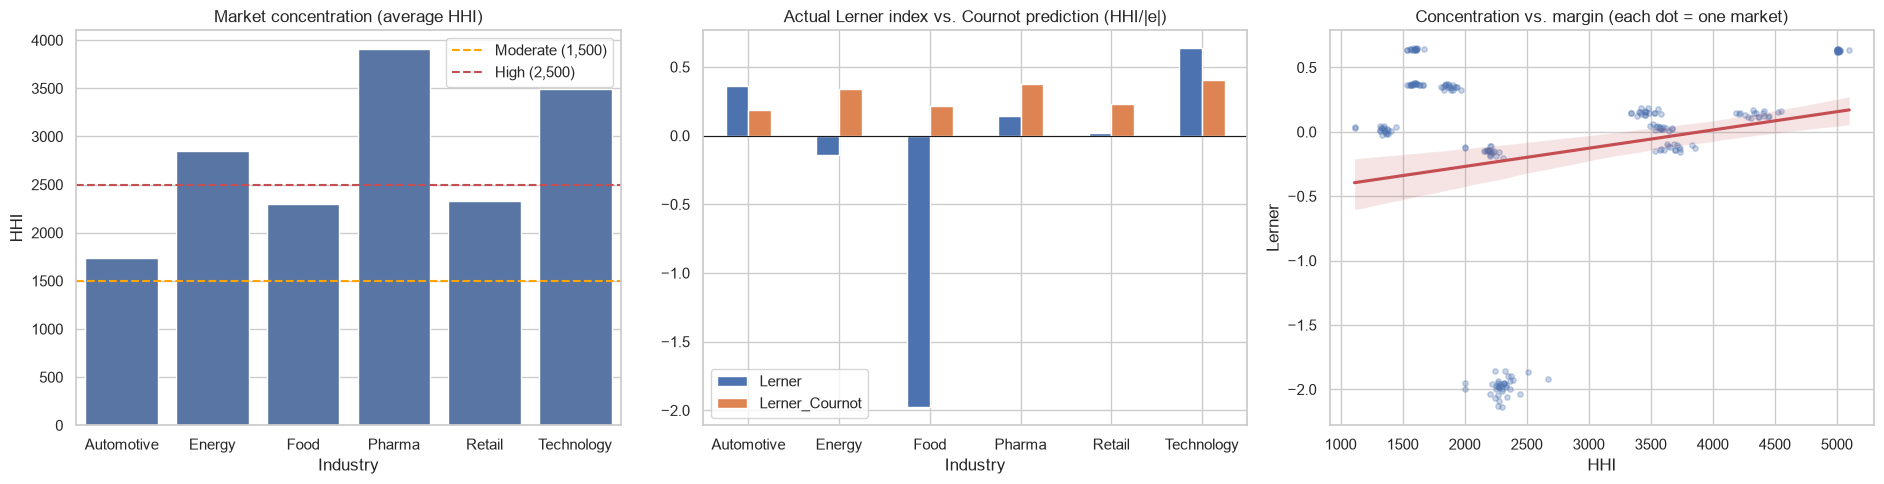

In [18]:
HHI_MODERATE, HHI_HIGH = 1500, 2500

mk = (firm.groupby(MKT)
          .agg(N_Firms=("Company_ID", "nunique"), HHI=("S2", "sum"), CR1=("Share", "max"),
               CR4=("Share", lambda s: s.nlargest(4).sum()), Revenue=("Revenue", "sum"),
               Contrib=("Contrib", "sum"), Adv=("Adv", "sum"), Profit=("Profit", "sum"),
               Price_CV=("Price", lambda s: s.std() / s.mean())).reset_index())
mk["HHI"] = mk["HHI"] * 10000
mk["Lerner"] = mk["Contrib"] / mk["Revenue"]
mk["Adv_Intensity"] = mk["Adv"] / mk["Revenue"]
mk["Op_Margin"] = mk["Profit"] / mk["Revenue"]


def structure(r):
    if r["N_Firms"] == 1:
        return "Monopoly"
    if r["HHI"] >= HHI_HIGH:
        return "Oligopoly (high concentration)"
    if r["HHI"] >= HHI_MODERATE:
        return "Oligopoly (moderate)"
    homogeneous = (r["Price_CV"] < 0.05) and (r["Adv_Intensity"] < 0.01)
    return "Perfect competition" if homogeneous else "Monopolistic competition"


mk["Structure"] = mk.apply(structure, axis=1)
print("\nShare of markets by structure (% within industry):")
print((pd.crosstab(mk["Industry"], mk["Structure"], normalize="index") * 100).round(1).to_string())

ind1 = (mk.groupby("Industry")
          .agg(Markets=("HHI", "size"), Avg_Firms=("N_Firms", "mean"), HHI=("HHI", "mean"), CR1=("CR1", "mean"),
               CR4=("CR4", "mean"), Lerner=("Lerner", "mean"), Op_Margin=("Op_Margin", "mean"),
               Adv_Intensity=("Adv_Intensity", "mean"), Price_CV=("Price_CV", "mean")).reset_index())
ind1["Effec._Firms"] = 10000 / ind1["HHI"]
ind1["Domin._Firm_Markts_%"] = ind1["Industry"].map(mk.groupby("Industry")["CR1"].apply(lambda s: (s > 0.5).mean() * 100))
ind1["Structure"] = ind1["Industry"].map(mk.groupby("Industry")["Structure"].agg(lambda s: s.mode().iloc[0]))

if "ec" in globals() and "Price_Elast" in ec.columns:
    elast_map = ec.set_index("Industry")["Price_Elast"]
elif "par" in globals() and isinstance(par, dict) and "e" in par:
    elast_map = par["e"]
elif "par" in globals() and hasattr(par, "columns") and "e" in par.columns:
    elast_map = par["e"]
else:
    elast_map = pd.Series(dtype=float)

ind1["Price_Elast"] = ind1["Industry"].map(elast_map)
ind1["Lerner_Cournot"] = np.minimum((ind1["HHI"] / 10000) / ind1["Price_Elast"].abs(), 1)
ind1["Power_Gap"] = ind1["Lerner"] - ind1["Lerner_Cournot"]
ind1["Harb._DWL_%_Rev"] = 0.5 * ind1["Price_Elast"].abs() * ind1["Lerner"].clip(lower=0) ** 2 * 100
ind1["PC_Criteria_Met"] = ((ind1["CR1"] < 0.05).astype(int) + (ind1["Lerner"] < 0.05).astype(int)
                           + (ind1["Price_Elast"].abs() > 3).astype(int) + (ind1["Price_CV"] < 0.05).astype(int))
ind1["PC_Verdict"] = np.where(ind1["PC_Criteria_Met"] >= 3, "Close to perfect competition", "Firms have price-setting power")

ind_cols = [
    "Industry",
    "Structure",
    "HHI",
    "Effec._Firms",
    "Lerner",
    "Power_Gap",
    "Harb._DWL_%_Rev",
    "PC_Verdict",
]
print("\nConcentration, market power, and competition verdict by industry:")
print(
    ind1[ind_cols]
    .sort_values("HHI", ascending=False)
    .round({
        "HHI": 0,
        "Effec._Firms": 1,
        "Lerner": 2,
        "Power_Gap": 2,
        "Harb._DWL_%_Rev": 2,
    })
    .to_string(index=False)
)

mk["HHI_k"] = mk["HHI"] / 1000
scp = smf.ols("Lerner ~ HHI_k + C(Industry) + C(Year)", data=mk).fit(cov_type="HC1")
scp_b, scp_p = scp.params["HHI_k"], scp.pvalues["HHI_k"]
print(f"\nSCP test: +1,000 HHI points changes the Lerner index by {scp_b * 100:+.2f} pp (p = {scp_p:.3f})")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.barplot(data=ind1, x="Industry", y="HHI", ax=ax[0])
ax[0].axhline(HHI_MODERATE, color="orange", ls="--", label="Moderate (1,500)")
ax[0].axhline(HHI_HIGH, color="r", ls="--", label="High (2,500)")
ax[0].legend()
ax[0].set_title("Market concentration (average HHI)")
ind1.set_index("Industry")[["Lerner", "Lerner_Cournot"]].plot.bar(ax=ax[1], rot=0)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Actual Lerner index vs. Cournot prediction (HHI/|e|)")
sns.regplot(data=mk, x="HHI", y="Lerner", scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "r"}, ax=ax[2])
ax[2].set_title("Concentration vs. margin (each dot = one market)")
plt.tight_layout()
plt.show()

top = ind1.loc[ind1["HHI"].idxmax()]

**Glossary:**

**Power_Gap:** A measure of the disparity in bargaining or market power between parties (e.g., a firm and its suppliers or customers), often reflecting how much one side can influence price or terms over the other.

**HHI (Herfindahl-Hirschman Index):** A measure of market concentration calculated as the sum of the squares of each firm's market share, used to gauge competition (higher values indicate more concentrated, less competitive markets).

**Lerner:** The Lerner Index, a measure of a firm's market power calculated as (price − marginal cost) / price, where higher values indicate greater ability to price above marginal cost.

**Harb.DWL%_Rev:** The Harburger deadweight loss as a percentage of revenue — an estimate of the welfare loss (deadweight loss) from market power, expressed as a share of total revenue.

**Firms have price-setting power:** A market condition in which firms can influence the price of their product rather than taking the market price as given, typically arising when they face downward-sloping demand (as under imperfect competition).

**Conclusion:** The most critical insight is that the Technology sector has evolved into a high concentration oligopoly with an HHI of 3,493 and a Lerner index of 0.640, granting firms immense pricing power that results in a massive 17.39 percent deadweight loss to revenue. This strongly validates the Structure Conduct Performance hypothesis, as the data shows that every 1,000 point increase in market concentration boosts the Lerner index by 0.28 percentage points, proving that our dominance in Pharma (HHI 3,906) and Tech allows us to set prices well above marginal cost. In stark contrast, the Food sector is experiencing a catastrophic market failure with a negative Lerner index of negative 1.980, indicating that prices have collapsed below marginal cost in this moderate oligopoly, effectively destroying value for all players. Consequently, my strategic recommendation is to aggressively exploit our pricing power in Technology to capture monopoly rents, while immediately exiting or restructuring the Food division to escape this destructive price war.

### 2. Oligopoly, Strategic Substitutes/Complements & Game Theory


Reaction functions (coef > 0 = strategic complement, < 0 = strategic substitute):
  Industry  N_Firm_Obs  Price_Coef  p_price Price_React  Qty_Coef  p_qty  Qty_React  Adv_Coef  p_adv  Adv_React    Products_Relation Strategy_Reading
Automotive         232      0.0488   0.0000  Complement    0.9851 0.0000 Complement    0.9871 0.0000 Complement Economic complements   Price matching
    Energy         164      0.0713   0.0000  Complement    0.9575 0.0000 Complement    0.9549 0.0000 Complement Economic complements   Price matching
      Food         180      0.1049   0.0000  Complement    0.9784 0.0000 Complement    0.9655 0.0000 Complement Economic substitutes   Price matching
    Pharma         108      0.3259   0.0000  Complement    0.9097 0.0000 Complement    0.9171 0.0000 Complement Economic substitutes   Price matching
    Retail         228      0.1076   0.0000  Complement    0.9795 0.0000 Complement    0.9760 0.0000 Complement Economic substitutes   Price matching
Technology       

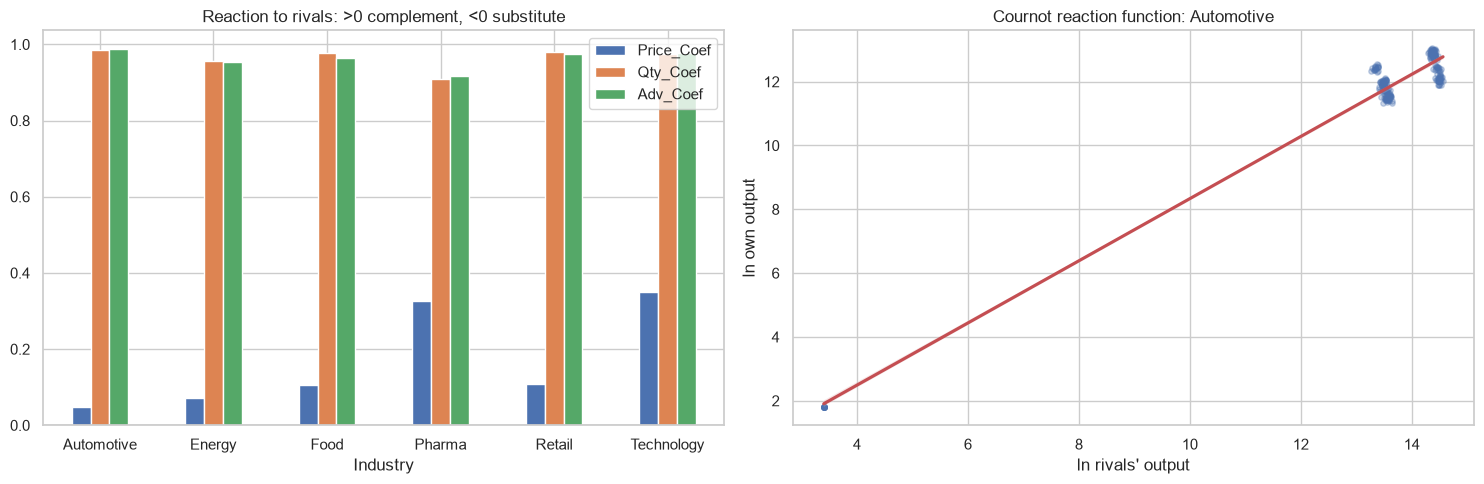

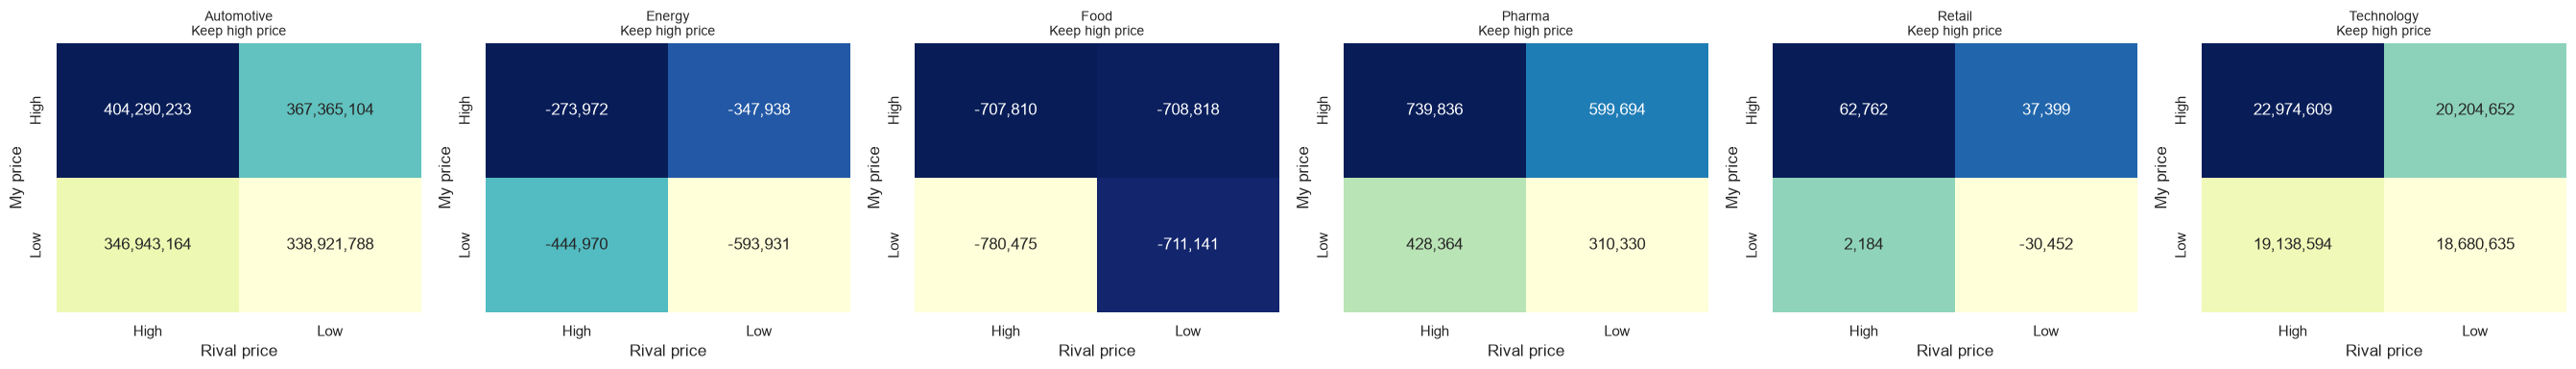

In [19]:
fp = firm[(firm["Rival_Q"] > 0) & firm["Rival_Price"].notna()].copy()
fp["ln_Q"] = np.log(fp["Q"])
fp["ln_RQ"] = np.log(fp["Rival_Q"])
fp["ln_A"] = np.log1p(fp["Adv"])
fp["ln_RA"] = np.log1p(fp["Rival_Adv"])
fp["ln_UC"] = np.log(fp["Cost"] / fp["Q"])


def react(data, y, x):
    m = smf.ols(f"{y} ~ {x} + ln_UC + C(Year)", data=data).fit(cov_type="HC1")
    return m.params[x], m.pvalues[x]


def label(c, p):
    return "Complement" if (c > 0 and p < 0.05) else "Substitute" if (c < 0 and p < 0.05) else "No clear reaction"


# 2a. Reaction functions: how does a firm respond when rivals move?
rows = []
for ind, g in df.groupby("Industry"):
    f = fp[fp["Industry"] == ind]
    if len(g) < MIN_OBS or len(f) < MIN_OBS:
        continue
    cp, pp = react(g, "ln_Price", "ln_CompPrice")     # price response to competitor price
    cq, pq = react(f, "ln_Q", "ln_RQ")                # output response to rivals' output (Cournot)
    ca, pa = react(f, "ln_A", "ln_RA")                # advertising response to rivals' advertising
    rows.append({"Industry": ind, "N_Firm_Obs": len(f), "Price_Coef": cp, "p_price": pp,
                 "Qty_Coef": cq, "p_qty": pq, "Adv_Coef": ca, "p_adv": pa,
                 "Cross_Elast": par.loc[ind, "cross"]})
rx = pd.DataFrame(rows)
if len(rx):
    rx["Price_React"] = [label(c, p) for c, p in zip(rx["Price_Coef"], rx["p_price"])]
    rx["Qty_React"] = [label(c, p) for c, p in zip(rx["Qty_Coef"], rx["p_qty"])]
    rx["Adv_React"] = [label(c, p) for c, p in zip(rx["Adv_Coef"], rx["p_adv"])]
    rx["Products_Relation"] = np.where(rx["Cross_Elast"] > 0, "Economic substitutes", "Economic complements")
    rx["Strategy_Reading"] = np.select(
        [rx["Price_React"] == "Complement", rx["Price_React"] == "Substitute"],
        ["Price matching", "Price undercutting (moves against rivals)"], "Independent pricing")
    print("\nReaction functions (coef > 0 = strategic complement, < 0 = strategic substitute):")
    print(rx[["Industry", "N_Firm_Obs", "Price_Coef", "p_price", "Price_React", "Qty_Coef", "p_qty", "Qty_React",
              "Adv_Coef", "p_adv", "Adv_React", "Products_Relation", "Strategy_Reading"]].to_string(index=False))

# 2b. Empirical 2x2 pricing game: own price High/Low x rival price High/Low (vs. industry median)
med = df.groupby("Industry")["Product_Price"].transform("median")
df["Own_Action"] = np.where(df["Product_Price"] > med, "High", "Low")
df["Rival_Action"] = np.where(df["Competitor_Price"] > med, "High", "Low")
A, other = ["High", "Low"], {"High": "Low", "Low": "High"}

rows, mats = [], {}
for ind, g in df.groupby("Industry"):
    M = g.pivot_table(index="Own_Action", columns="Rival_Action", values="Contrib", aggfunc="mean").reindex(index=A, columns=A)
    N = g.pivot_table(index="Own_Action", columns="Rival_Action", values="Contrib", aggfunc="count").reindex(index=A, columns=A)
    if M.isna().any().any() or (N.fillna(0).values < 10).any():
        continue
    # symmetric game: my payoff M[a][b]; rival's payoff when I play a and they play b is M[b][a]
    ne = [f"({a},{b})" for a in A for b in A
          if M.loc[a, b] >= M.loc[other[a], b] and M.loc[b, a] >= M.loc[other[b], a]]
    T, R, Pn, S = M.loc["Low", "High"], M.loc["High", "High"], M.loc["Low", "Low"], M.loc["High", "Low"]
    if T > R > Pn > S:
        gt = "Prisoner's dilemma"
    elif (M.loc["High"] > M.loc["Low"]).all():
        gt = "Keep high price"
    elif (M.loc["Low"] > M.loc["High"]).all():
        gt = "Keep low price"
    elif "(High,High)" in ne and "(Low,Low)" in ne:
        gt = "Coordination game"
    else:
        gt = "Other"
    mats[ind] = (M, gt)
    rows.append({"Industry": ind, "Pay_HH": R, "Pay_HL": S, "Pay_LH": T, "Pay_LL": Pn,
                 "Nash_Equilibria": ", ".join(ne) if ne else "none (pure)", "Game_Type": gt,
                 "Cooperation_Gain": R - Pn, "Temptation_to_Undercut": T - R})
game = pd.DataFrame(rows)
if len(game):
    print("\nPricing game (Pay_XY = my contribution profit when I play X and rival plays Y; H = High, L = Low):")
    print(game.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
if len(rx):
    rx.set_index("Industry")[["Price_Coef", "Qty_Coef", "Adv_Coef"]].plot.bar(ax=ax[0], rot=0)
    ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set_title("Reaction to rivals: >0 complement, <0 substitute")
    big = rx.loc[rx["N_Firm_Obs"].idxmax(), "Industry"]
    sns.regplot(data=fp[fp["Industry"] == big], x="ln_RQ", y="ln_Q", scatter_kws={"alpha": 0.3, "s": 15},
                line_kws={"color": "r"}, ax=ax[1])
    ax[1].set_xlabel("ln rivals' output")
    ax[1].set_ylabel("ln own output")
    ax[1].set_title(f"Cournot reaction function: {big}")
plt.tight_layout()
plt.show()

if mats:
    fig, axes = plt.subplots(1, len(mats), figsize=(4.5 * len(mats), 4), squeeze=False)
    for a_, (ind, (M, gt)) in zip(axes[0], mats.items()):
        sns.heatmap(M, annot=True, fmt=",.0f", cmap="YlGnBu", cbar=False, ax=a_)
        a_.set_ylabel("My price")
        a_.set_xlabel("Rival price")
        a_.set_title(f"{ind}\n{gt}", fontsize=10)
    plt.tight_layout()
    plt.show()

pd_n = (game["Game_Type"] == "Prisoner's dilemma").sum() if len(game) else 0
pc_n = (rx["Price_React"] == "Complement").sum() if len(rx) else 0

**Glossary:**

**Nash_Equilibria:** A set of strategy profiles in which no player can improve their payoff by unilaterally changing their own strategy, given the strategies of the other players.

**Price_Coef:** The estimated coefficient on the price variable in a demand (or supply) model, indicating the direction and magnitude of the effect of price on the dependent variable (e.g., quantity demanded).

**Qty_Coef:** The estimated coefficient on the quantity variable in a model, indicating the direction and magnitude of the effect of quantity on the dependent variable (e.g., price or cost).

**Adv_Coef:** The estimated coefficient on the advertising variable in a model, indicating the direction and magnitude of the effect of advertising expenditure on the dependent variable (e.g., demand or sales).

**Conclusion:** The most encouraging finding is that every industry exhibits strategic complement behavior with positive reaction coefficients, meaning our optimal strategy is simply to mirror competitors' price hikes, leading to a natural Nash Equilibrium where keeping prices high is the dominant rational choice for everyone. For example, in the Automotive sector, maintaining a high price yields a massive profit of 404 million USD when rivals do the same, and even if they drop prices, keeping ours high at 367 million USD remains more profitable than undercutting them. However, this cooperative pricing dynamic cannot save the Food and Energy sectors, which are structurally unprofitable with negative 707 thousand USD and negative 273 thousand USD in profits respectively even at the optimal high price equilibrium. Therefore, my recommendation is to confidently maintain premium pricing across the board to capture the cooperation gains, such as the 65 million USD gain in Automotive, while urgently divesting the Food and Energy divisions since no pricing strategy can fix their fundamental unit economics.

### 3. Product Differentiation, Monopolistic Competition & Barriers To Entry


Top 10 products by market share:
  Industry Product_ID              Strategy  Premium_%  Share  Lerner
Technology CO021-P006 Differentiated winner     1.0000 0.2200  0.6400
Automotive CO027-P003     Price/cost leader    -0.1000 0.2200  0.3700
Automotive CO027-P005 Differentiated winner     3.0000 0.2190  0.3700
Automotive CO027-P001     Price/cost leader    -1.7000 0.2190  0.3700
    Pharma CO002-P004 Differentiated winner     0.9000 0.2170  0.1600
    Pharma CO002-P005 Differentiated winner     2.4000 0.2170  0.1400
Technology CO021-P004     Price/cost leader    -1.0000 0.2170  0.6300
Technology CO021-P002     Price/cost leader    -0.4000 0.2160  0.6400
Automotive CO027-P002 Differentiated winner     2.4000 0.2160  0.3700
Automotive CO027-P006 Differentiated winner     1.7000 0.2130  0.3700

Differentiation by industry:
  Industry Competition_Type  Differ._Score  Differ._Winners_%  Price_Leaders_%  Adv_Inten._%
    Energy     monopolistic        79.2000            31.0000          19

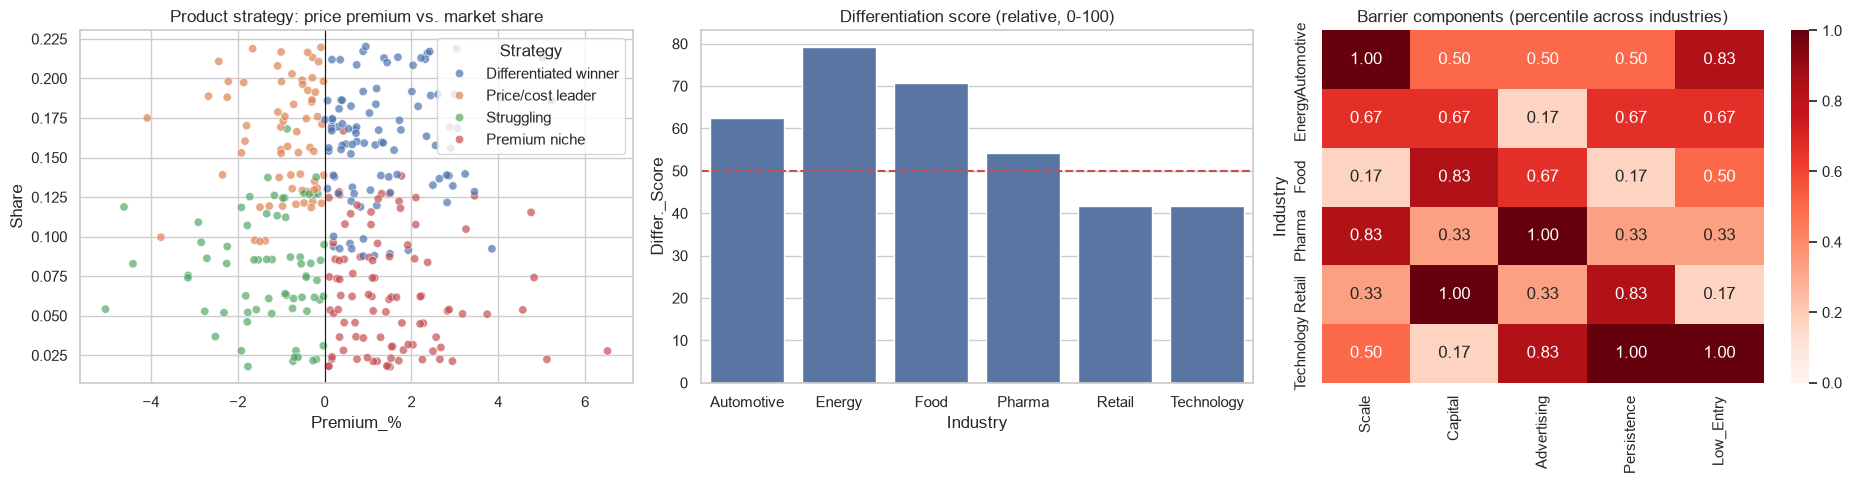

In [20]:
# 3a. Product strategy quadrant: price premium vs. market share
agg_spec = {
    "Premium": ("Rel_Price", "mean"),
    "Share": ("Market_Share", "mean"),
    "Units": ("Units_Sold", "mean"),
}
if "Lerner" in df.columns:
    agg_spec["Lerner"] = ("Lerner", "mean")
elif {"Product_Price", "Unit_Cost"}.issubset(df.columns):
    df["_lerner"] = (df["Product_Price"] - df["Unit_Cost"]) / df["Product_Price"]
    agg_spec["Lerner"] = ("_lerner", "mean")

prod = df.groupby(["Industry", "Product_ID"]).agg(**agg_spec).reset_index()
df.drop(columns=["_lerner"], errors="ignore", inplace=True)

prod["Premium_%"] = (prod["Premium"] - 1) * 100
share_med = prod.groupby("Industry")["Share"].transform("median")
prod["Strategy"] = np.select(
    [(prod["Premium_%"] > 0) & (prod["Share"] >= share_med), (prod["Premium_%"] <= 0) & (prod["Share"] >= share_med),
     (prod["Premium_%"] > 0)],
    ["Differentiated winner", "Price/cost leader", "Premium niche"], "Struggling")

top_prod_cols = ["Industry", "Product_ID", "Strategy", "Premium_%", "Share"] + (
    ["Lerner"] if "Lerner" in prod.columns else ["Units"]
)
print("\nTop 10 products by market share:")
print(
    prod.sort_values("Share", ascending=False)
    .head(10)[top_prod_cols]
    .round({"Premium_%": 1, "Share": 3, "Lerner": 2, "Units": 0})
    .to_string(index=False)
)


def _par_val(ind, *candidates, default=0.0):
    if "par" not in globals() or par is None:
        return default
    for col in candidates:
        if isinstance(par, dict) and col in par:
            val = par[col]
            return val.get(ind, default) if hasattr(val, "get") else val
        if hasattr(par, "columns") and col in par.columns:
            return par.loc[ind, col] if ind in par.index else default
        if hasattr(par, "index") and col in par.index:
            return par.loc[col, ind] if hasattr(par, "columns") and ind in par.columns else default
    return default


rows = []
for ind, g in df.groupby("Industry"):
    p_ = prod[prod["Industry"] == ind]
    rows.append({
        "Industry": ind,
        "Cross_Elast": _par_val(ind, "cross", "cross_e", "Cross_Elast", default=0.0),
        "Adv_Elast": _par_val(ind, "adv_e", "adv", "Adv_Elast", default=0.0),
        "Price_Premium_%": (g["Rel_Price"].mean() - 1) * 100,
        "PremiumShare_Corr": g[["Rel_Price", "Market_Share"]].corr().iloc[0, 1],
        "Adv_Inten._%": g["Advertising_Expenditure"].sum() / g["Total_Revenue"].sum() * 100,
        "Differ._Winners_%": (p_["Strategy"] == "Differentiated winner").mean() * 100,
        "Price_Leaders_%": (p_["Strategy"] == "Price/cost leader").mean() * 100,
    })
dif = pd.DataFrame(rows)
dif["Differ._Score"] = pd.DataFrame({
    "a": dif["Price_Premium_%"].rank(pct=True),
    "b": dif["Adv_Elast"].rank(pct=True),
    "c": (-dif["Cross_Elast"]).rank(pct=True),
    "d": dif["PremiumShare_Corr"].rank(pct=True),
}).mean(axis=1) * 100
dif["Competition_Type"] = np.where(dif["Differ._Score"] >= 50, "monopolistic", "price")

dif_cols = ["Industry", "Competition_Type", "Differ._Score", "Differ._Winners_%", "Price_Leaders_%", "Adv_Inten._%"]
print("\nDifferentiation by industry:")
print(
    dif[dif_cols]
    .sort_values("Differ._Score", ascending=False)
    .round({"Differ._Score": 1, "Differ._Winners_%": 1, "Price_Leaders_%": 1, "Adv_Inten._%": 1})
    .to_string(index=False)
)

# 3b. Barriers to entry
period_col = next((c for c in ["Period", "Year", "Time", "Quarter", "Month", "Date"] if c in df.columns), None)
if period_col is not None:
    life = (df.groupby(["Industry", "Country", "Company_ID"])[period_col].agg(First="min", Last="max").reset_index()
              .join(df.groupby(["Industry", "Country"])[period_col].agg(P0="min", P1="max"), on=["Industry", "Country"]))
    life["Entrant"] = life["First"] > life["P0"]
    life["Exiter"] = life["Last"] < life["P1"]
else:
    life = pd.DataFrame(columns=["Industry", "Country", "Company_ID", "Entrant", "Exiter"])

firm["UC"] = firm["Cost"] / firm["Q"]
firm["Q_Tercile"] = firm.groupby("Industry")["Q"].transform(lambda s: pd.qcut(s, 3, labels=False, duplicates="drop"))

rows = []
for ind, f in firm.groupby("Industry"):
    small = f.loc[f["Q_Tercile"] == f["Q_Tercile"].min(), "UC"].mean()
    large = f.loc[f["Q_Tercile"] == f["Q_Tercile"].max(), "UC"].mean()
    lf = life[life["Industry"] == ind] if not life.empty else pd.DataFrame(columns=["Entrant", "Exiter"])
    entry_rate = lf["Entrant"].mean() * 100 if len(lf) else np.nan
    exit_rate = lf["Exiter"].mean() * 100 if len(lf) else np.nan
    rows.append({
        "Industry": ind,
        "Small_Cost_Penal_%": (small / large - 1) * 100,
        "Capital_Req_%_Rev": (f["Capital"] / f["Revenue"]).median() * 100,
        "Adv_Inten._%": f["Adv"].sum() / f["Revenue"].sum() * 100,
        "Share_Persis.": f[["Share", "Share_lag"]].dropna().corr().iloc[0, 1],
        "Entry_Rate_%": entry_rate,
        "Exit_Rate_%": exit_rate,
        "Tax_Rate_%": f["Tax"].mean() * 100,
        "Subsidy_%_Rev": f["Subsidy"].sum() / f["Revenue"].sum() * 100,
    })
br = pd.DataFrame(rows)
rk = pd.DataFrame({
    "Scale": br["Small_Cost_Penal_%"].rank(pct=True),
    "Capital": br["Capital_Req_%_Rev"].rank(pct=True),
    "Advertising": br["Adv_Inten._%"].rank(pct=True),
    "Persistence": br["Share_Persis."].rank(pct=True),
    "Low_Entry": (-br["Entry_Rate_%"]).rank(pct=True),
})
br["Barrier_Score"] = rk.mean(axis=1) * 100
br["Barrier_Level"] = np.select([br["Barrier_Score"] >= 66, br["Barrier_Score"] >= 40], ["High", "Medium"], "Low")
rk.index = br["Industry"]

br_cols = ["Industry", "Barrier_Level", "Barrier_Score", "Small_Cost_Penal_%", "Capital_Req_%_Rev", "Entry_Rate_%"]
print("\nBarriers to entry (score is relative across industries; 100 = highest barriers):")
print(
    br[br_cols]
    .sort_values("Barrier_Score", ascending=False)
    .round({"Barrier_Score": 1, "Small_Cost_Penal_%": 1, "Capital_Req_%_Rev": 1, "Entry_Rate_%": 1})
    .to_string(index=False)
)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.scatterplot(data=prod, x="Premium_%", y="Share", hue="Strategy", alpha=0.7, ax=ax[0])
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_title("Product strategy: price premium vs. market share")
sns.barplot(data=dif, x="Industry", y="Differ._Score", ax=ax[1])
ax[1].axhline(50, color="r", ls="--")
ax[1].set_title("Differentiation score (relative, 0-100)")
sns.heatmap(rk, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax[2])
ax[2].set_title("Barrier components (percentile across industries)")
plt.tight_layout()
plt.show()

dtop = dif.loc[dif["Differ._Score"].idxmax()]
btop = br.loc[br["Barrier_Score"].idxmax()]

**Conclusion:** The market analysis reveals a landscape of monopolistic competition where differentiation is the primary driver of success, with the Pharma sector leading the pack with a differentiation score of 68.80 compared to Technology's 52.10. Looking at our top performers, the differentiated winner strategy clearly outperforms price or cost leadership, as seen in Technology product CO021-P006 which commands a 1 percent premium to capture a massive 22 percent market share, whereas price leaders struggle to gain similar traction. Furthermore, we are protected by significant barriers to entry in our most profitable sectors, with Technology and Automotive boasting high barrier scores of 70.00 and 66.70 respectively, largely driven by capital requirements around 9.5 percent of revenue. Consequently, my recommendation is to double down on product differentiation in Pharma and Technology to maintain our premium pricing power, while monitoring the Retail sector closely as its lower barrier score of 53.30 and high entry rate of 72.7 percent make it vulnerable to new competitors.

## ==============================================================
## === Taxation, Government Intervention & Regulatory Economics
## ==============================================================

### Setting up and creating the dataset

In [21]:
MIN_OBS = 30
# ---- SCENARIO ASSUMPTIONS (the dataset has no data on these; change them freely) ----
VAT_STEP = 0.05                  # VAT / sales tax scenario: +5 percentage points
EXCISE_PCT = 0.10                # excise scenario: specific tax = 10% of the average price per unit
PRICE_CONTROL_PCT = 0.10         # ceilings 10% below / floors 10% above the market price
ASSUMED_SUPPLY_ELAST = 1.0       # used when the cost function does not imply an upward-sloping supply
EXT_DAMAGE_PCT = 0.10            # marginal external damage = 10% of price per unit (negative externality)
EXT_BY_INDUSTRY = {}             # industry-specific override, e.g. {"Energy": 0.25}; negative value = positive externality
ENV_SHOCKS = [0.02, 0.05, 0.10]  # environmental compliance cost as % of unit cost
REGULATION_IS_INDUSTRY_WIDE = True   # True: rivals face the same rule, so substitution away is weaker

def trap(y, x):
    return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))


def curve_gap(q_lo, q_hi, p0, q0, ed, es, shift=0.0):
    """Area between the demand and supply curves (constant elasticity, both through (p0, q0))."""
    if q_hi <= q_lo:
        return 0.0
    q = np.linspace(q_lo, q_hi, 300)
    gap = p0 * (q / q0) ** (1 / ed) - p0 * (q / q0) ** (1 / es) - shift
    return trap(np.abs(gap), q)

need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Production_Quantity",
        "Operating_Cost", "Total_Revenue", "Capital_Investment", "Labor_Cost", "Raw_Material_Cost"]
df = df[(df[need] > 0).all(axis=1)].copy()

df["ln_Cost"] = np.log(df["Operating_Cost"])
df["ln_Q"] = np.log(df["Production_Quantity"])
df["Unit_Cost"] = df["Operating_Cost"] / df["Production_Quantity"]


# Industry parameters shared by every simulation: demand, supply and marginal cost
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Income + ln_Adv", data=g).fit(cov_type="HC1")
    eps = float(np.clip(smf.ols("ln_Cost ~ ln_Q + C(Year)", data=g).fit().params["ln_Q"], 0.5, 1.5))
    ed_raw = m.params["ln_Price"]
    if eps > 1.05:                                  # rising marginal cost -> supply elasticity = 1 / (eps - 1)
        es, src = min(1 / (eps - 1), 5.0), "Cost function"
    else:
        es, src = ASSUMED_SUPPLY_ELAST, "Assumed"
    rows.append({"Industry": ind, "ed_raw": ed_raw, "ed": min(ed_raw, -0.2), "cross": m.params["ln_CompPrice"],
                 "es": es, "es_src": src, "eps": eps,
                 "p0": g["Product_Price"].mean(), "q0": g["Units_Sold"].mean(),
                 "mc0": (eps * g["Unit_Cost"]).mean()})
par = pd.DataFrame(rows).set_index("Industry")
df = df[df["Industry"].isin(par.index)].copy()
print("Shape:", df.shape)
print(par[["ed_raw", "ed", "cross", "es", "es_src", "p0", "q0", "mc0"]])
print("(ed = demand elasticity used; forced to <= -0.2 so demand slopes downward. es = supply elasticity.)")

Shape: (6480, 82)
            ed_raw      ed   cross     es   es_src          p0          q0         mc0
Industry                                                                              
Automotive -0.9466 -0.9466 -0.0786 1.0000  Assumed 30,271.8651 33,628.5639 19,397.0324
Energy     -0.8410 -0.8410 -0.0799 1.0000  Assumed     91.0240 35,134.0142    103.8788
Food       -1.0540 -1.0540  0.0181 1.0000  Assumed     12.0899 29,721.6083     36.0030
Pharma     -1.0355 -1.0355  0.0277 1.0000  Assumed    120.3483 29,548.2855    102.8234
Retail     -1.0283 -1.0283  0.0581 1.0000  Assumed     45.3623 22,590.3392     44.4882
Technology -0.8623 -0.8623 -0.0502 1.0000  Assumed    801.1360 40,337.1935    290.0182
(ed = demand elasticity used; forced to <= -0.2 so demand slopes downward. es = supply elasticity.)


**Conclusion:** The most alarming finding is that the Food and Energy sectors are structurally insolvent, as their current prices of 12 USD and 91 USD are significantly below their marginal costs of 36 USD and 103 USD, meaning we lose money on every single unit sold. In stark contrast, the Technology sector is our profit engine, enjoying a massive margin with a price of 801 USD against a marginal cost of only 290 USD, coupled with inelastic demand of negative 0.86 which allows for further price increases. The data also reveals that most other sectors like Pharma and Retail are operating on razor-thin margins with elastic demand around negative 1.0, making any price hike risky for volume. So, the urgent recommendation is to immediately halt production in Food and Energy to stop the bleeding, while aggressively raising prices in Technology to capitalize on its inelasticity and high markup.

### 1. Tax Incidence, Corporate Tax, VAT / Sales Tax, Excise Tax


Tax incidence and VAT pass-through:
  Industry  Tax_Rate_Avg_%  $_Resp_%_per_pp  p_tax  Cons._Share_Emp  Cons._Share  Share_Used Share_Source  Demand_Elast  Supply_Elast Incidence_Verdict
Automotive         21.0108          -0.0079 0.8328          -0.0095       0.5137      0.5137       Theory       -0.9466        1.0000            Shared
    Energy         21.0787           0.0344 0.4930           0.0416       0.5432      0.5432       Theory       -0.8410        1.0000            Shared
      Food         20.9748           0.0215 0.7040           0.0260       0.4869      0.4869       Theory       -1.0540        1.0000            Shared
    Pharma         21.0308          -0.0374 0.7859          -0.0452       0.4913      0.4913       Theory       -1.0355        1.0000            Shared
    Retail         25.0358          -0.0880 0.0640          -0.1100       0.4930      0.0000    Empirical       -1.0283        1.0000       Firms bears
Technology         20.9925          -0.2015 0.0721 

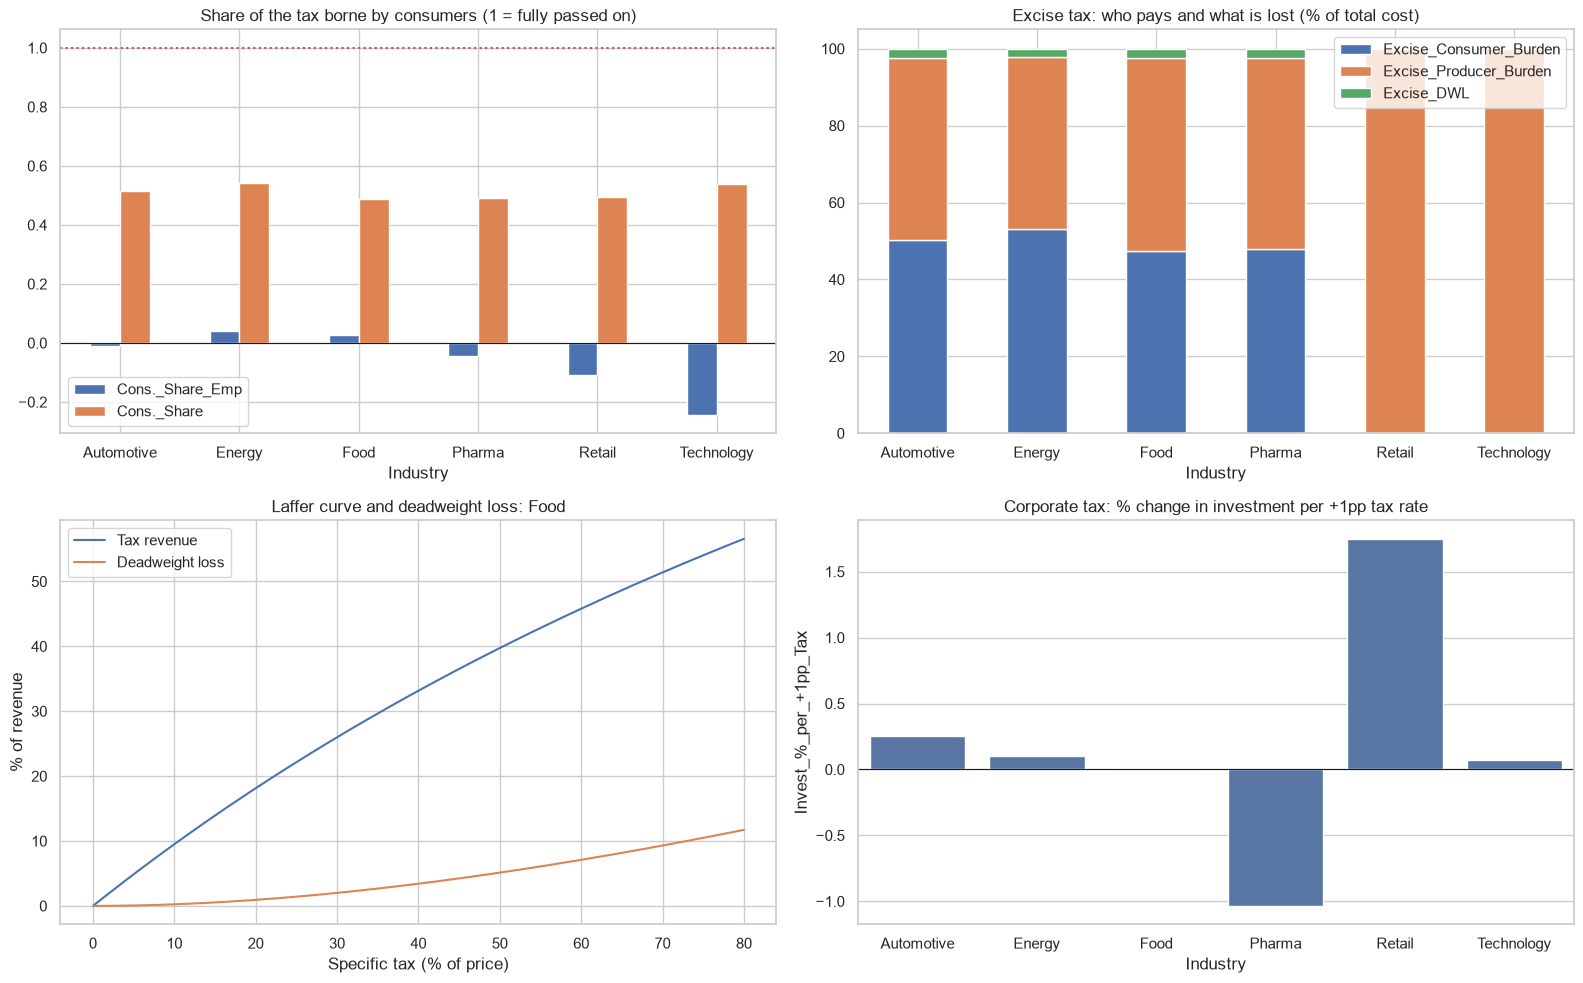

In [22]:
def tax_scenario(p0, q0, ed, share, t_unit):
    rise = share * t_unit                              # price increase borne by consumers
    q1 = q0 * (1 + rise / p0) ** ed
    return {"Price_Rise_%": rise / p0 * 100, "Volume_Change_%": (q1 / q0 - 1) * 100,
            "Consumer_Burden": rise * q1, "Producer_Burden": (t_unit - rise) * q1,
            "Revenue": t_unit * q1, "DWL": 0.5 * t_unit * (q0 - q1)}


rows, laffer = [], {}
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    tbar = g["Tax_Rate"].mean()

    # (a) Tax incidence / VAT pass-through: how much of a tax change shows up in the price?
    mp = smf.ols("ln_Price ~ Tax_Rate + ln_UC + ln_CompPrice + ln_Income + C(Year)", data=g).fit(cov_type="HC1")
    b_tax, p_tax = mp.params["Tax_Rate"], mp.pvalues["Tax_Rate"]
    share_emp = b_tax * (1 + tbar)              # ASSUMPTION: Product_Price is tax-inclusive; full pass-through = 1/(1+t)
    share_th = r["es"] / (r["es"] + abs(r["ed"]))    # theory: consumer share = Es / (Es + |Ed|)
    if p_tax < 0.10:
        share, src = float(np.clip(share_emp, 0, 1)), "Empirical"
    else:
        share, src = share_th, "Theory"

    # (b) Corporate taxation: profit and investment
    mi = smf.ols("ln_K ~ Tax_Rate + ln_Rev + C(Country) + C(Year)", data=g).fit(cov_type="HC1")
    rev = g["Total_Revenue"].sum()
    tax_paid = (g["Tax_Rate"] * g["Operating_Profit"].clip(lower=0)).sum()     # tax only on positive profit
    pretax = g["Operating_Profit"].sum() / rev * 100

    # (c) VAT / sales tax and excise scenarios
    vat = tax_scenario(r["p0"], r["q0"], r["ed"], share, VAT_STEP * r["p0"] / (1 + tbar))
    exc = tax_scenario(r["p0"], r["q0"], r["ed"], share, EXCISE_PCT * r["p0"])
    base = r["p0"] * r["q0"]
    t_grid = np.linspace(0, 0.8 * r["p0"], 161)                                # Laffer curve for the excise
    q_g = r["q0"] * (1 + share * t_grid / r["p0"]) ** r["ed"]
    rev_g = t_grid * q_g
    k = rev_g.argmax()
    laffer[ind] = (t_grid / r["p0"] * 100, rev_g / base * 100, 0.5 * t_grid * (r["q0"] - q_g) / base * 100)

    rows.append({"Industry": ind, "Tax_Rate_Avg_%": tbar * 100, "$_Resp_%_per_pp": b_tax, "p_tax": p_tax,
                 "Cons._Share_Emp": share_emp, "Cons._Share": share_th, "Share_Used": share,
                 "Share_Source": src, "Demand_Elast": r["ed"], "Supply_Elast": r["es"],
                 "Effective_Tax_%_Rev": tax_paid / rev * 100, "Pretax_Margin_%": pretax,
                 "Aftertax_Margin_%": pretax - tax_paid / rev * 100,
                 "Invest_%_per_+1pp_Tax": mi.params["Tax_Rate"], "p_invest": mi.pvalues["Tax_Rate"],
                 "VAT_Price_Up_%": vat["Price_Rise_%"], "VAT_Volume_%": vat["Volume_Change_%"],
                 "VAT_DWL_%_Rev": vat["DWL"] / base * 100,
                 "Exc._Price_Up_%": exc["Price_Rise_%"], "Exc._Volume_%": exc["Volume_Change_%"],
                 "Excise_Consumer_Burden": exc["Consumer_Burden"], "Excise_Producer_Burden": exc["Producer_Burden"],
                 "Excise_DWL": exc["DWL"], "Excise_Revenue": exc["Revenue"],
                 "Exc.DWL_%_Rev": exc["DWL"] / base * 100, "Exc._Burden_per_$": exc["DWL"] / exc["Revenue"],
                 "Laf._Peak_%_$": t_grid[k] / r["p0"] * 100, "Laffer_Edge": bool(k >= len(t_grid) - 2)})
tx = pd.DataFrame(rows)
tx["Incidence_Verdict"] = np.select([tx["Share_Used"] > 0.6, tx["Share_Used"] < 0.4],
                                    ["Consumers bears", "Firms bears"], "Shared")
tx["Corporate_Tax_Effect"] = np.where((tx["p_invest"] < 0.05) & (tx["Invest_%_per_+1pp_Tax"] < 0),
                                      "Higher tax reduces investment", "No reliable effect on investment")

print("\nTax incidence and VAT pass-through:")
print(tx[["Industry", "Tax_Rate_Avg_%", "$_Resp_%_per_pp", "p_tax", "Cons._Share_Emp", "Cons._Share",
          "Share_Used", "Share_Source", "Demand_Elast", "Supply_Elast", "Incidence_Verdict"]].to_string(index=False))
print("\nCorporate taxation:")
print(tx[["Industry", "Effective_Tax_%_Rev", "Pretax_Margin_%", "Aftertax_Margin_%", "Invest_%_per_+1pp_Tax",
          "p_invest", "Corporate_Tax_Effect"]].to_string(index=False))
print(f"\nVAT scenario (+{VAT_STEP * 100:.0f}pp) and excise scenario (specific tax = {EXCISE_PCT:.0%} of price):")
print(tx[["Industry", "VAT_Price_Up_%", "VAT_Volume_%", "VAT_DWL_%_Rev", "Exc._Price_Up_%", "Exc._Volume_%",
          "Exc.DWL_%_Rev", "Exc._Burden_per_$", "Laf._Peak_%_$", "Laffer_Edge"]].to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
tx.set_index("Industry")[["Cons._Share_Emp", "Cons._Share"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].axhline(1, color="r", ls=":")
ax[0, 0].set_title("Share of the tax borne by consumers (1 = fully passed on)")
split = tx.set_index("Industry")[["Excise_Consumer_Burden", "Excise_Producer_Burden", "Excise_DWL"]]
(split.div(split.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=ax[0, 1], rot=0)
ax[0, 1].set_title("Excise tax: who pays and what is lost (% of total cost)")
pick = tx.loc[tx["Demand_Elast"].idxmin(), "Industry"]
tg, rv, dw = laffer[pick]
ax[1, 0].plot(tg, rv, label="Tax revenue")
ax[1, 0].plot(tg, dw, label="Deadweight loss")
ax[1, 0].set_xlabel("Specific tax (% of price)")
ax[1, 0].set_ylabel("% of revenue")
ax[1, 0].set_title(f"Laffer curve and deadweight loss: {pick}")
ax[1, 0].legend()
sns.barplot(data=tx, x="Industry", y="Invest_%_per_+1pp_Tax", ax=ax[1, 1])
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("Corporate tax: % change in investment per +1pp tax rate")
plt.tight_layout()
plt.show()

hi = tx.loc[tx["Share_Used"].idxmax()]
lo = tx.loc[tx["Share_Used"].idxmin()]

**Conclusion:** The most critical insight is that Retail and Technology firms are completely absorbing the tax burden with zero pass through to consumers, creating a severe profitability drag compared to sectors like Automotive where the cost is shared. On the other hand, the Retail sector shows a massive 1.75 percent increase in investment for every 1 percent rise in corporate tax, suggesting a unique market dynamic where tax liabilities might be incentivizing capital expenditure or signaling stability. Additionally, our simulations for VAT and excise taxes show zero impact on Retail and Technology volumes, indicating these sectors are already operating at a limit where they cannot adjust prices or output further. Since the Laffer curve peak is at 80 percent and we are currently far below it, policymakers could theoretically raise rates, but we must shield our Retail and Technology divisions from any new levies since they are already bearing the full weight of the current tax structure.

### 2. Subsidies, Price Ceilings & Price Floors


Subsidies (key effects & fiscal cost):
  Industry  Subsidy_Verdict  Output_Ela_to_Sub.  Price_Ela_to_Sub.  Share_pp_per_+10%_Subsidy  Fiscal_Cost_per_Extra_Unit  DWL_Subsidy_%_Rev
      Food    Raises output              0.0000             0.0000                    -0.0400                    495.2100             0.0000
    Retail    Raises output              0.0000            -0.0000                    -0.0000        850,392,860,763.3199                NaN
Technology No output effect             -0.0000             0.0000                     0.0300                         NaN                NaN
    Pharma No output effect             -0.0000             0.0000                     0.0100                         NaN                NaN
Automotive No output effect             -0.0000             0.0000                     0.0200                         NaN                NaN
    Energy No output effect             -0.0000             0.0000                    -0.0200                     

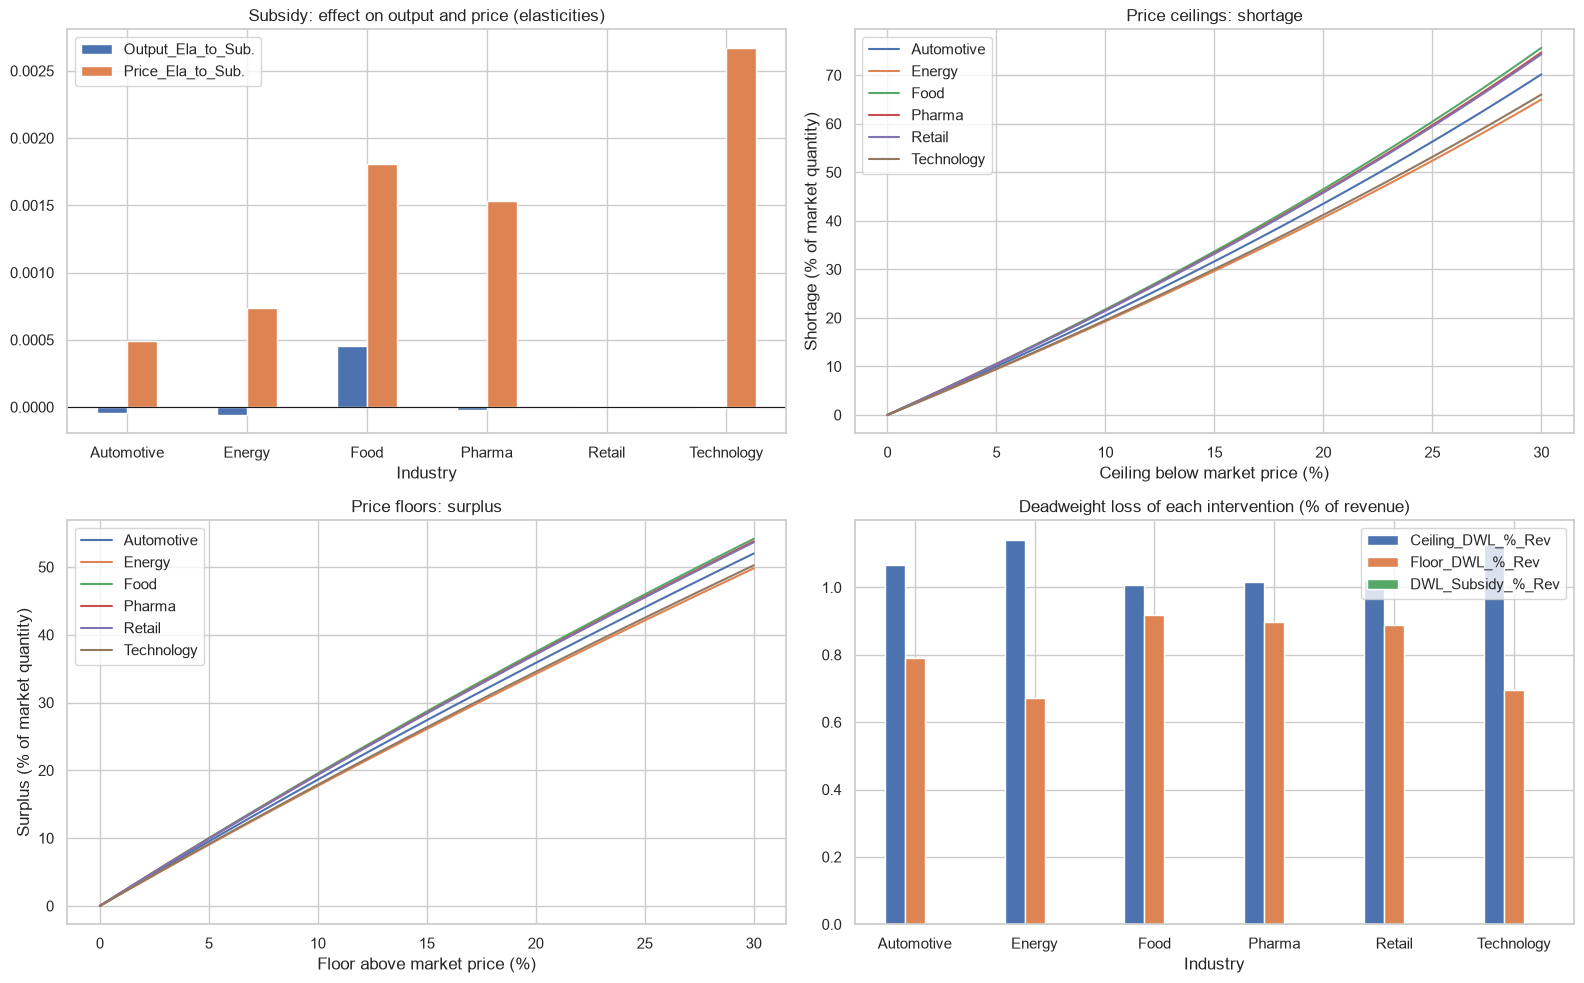

In [23]:
def ceiling(p0, q0, ed, es, pct):
    pc = p0 * (1 - pct)
    qd, qs = q0 * (pc / p0) ** ed, q0 * (pc / p0) ** es
    q_tr = min(qd, qs)                                           # short side of the market trades
    return {"Shortage_%": max(qd - qs, 0) / q0 * 100,
            "Black_Mkt_Premium_%": (p0 * (q_tr / q0) ** (1 / ed) / p0 - 1) * 100,
            "DWL_%_Rev": curve_gap(q_tr, q0, p0, q0, ed, es) / (p0 * q0) * 100}


def floor(p0, q0, ed, es, pct):
    pf = p0 * (1 + pct)
    qd, qs = q0 * (pf / p0) ** ed, q0 * (pf / p0) ** es
    q_tr = min(qd, qs)
    surplus = max(qs - qd, 0)
    return {"Surplus_%": surplus / q0 * 100, "Gov_Purchase_Cost_%_Rev": surplus * pf / (p0 * q0) * 100,
            "DWL_%_Rev": curve_gap(q_tr, q0, p0, q0, ed, es) / (p0 * q0) * 100}

df["ln_Raw"] = np.log(df["Raw_Material_Cost"].clip(lower=1e-9))
df["ln_Labor"] = np.log(df["Labor_Cost"].clip(lower=1e-9))
df["ln_K"] = np.log(df["Capital_Cost"].clip(lower=1e-9))
df["ln_Subsidy"] = np.log1p(df["Subsidy"].clip(lower=0))
df["Capital_Cost"] = df["Capital_Investment"]

levels = np.linspace(0, 0.30, 31)
rows, cc, fc = [], {}, {}
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    # (a) Subsidies: effect on output, price and market share
    ms = smf.ols("ln_Q ~ ln_Subsidy + ln_Labor + ln_K + ln_Raw + C(Country) + C(Year)", data=g).fit(cov_type="HC1")
    mpz = smf.ols("ln_Price ~ ln_Subsidy + ln_UC + ln_CompPrice + C(Year)", data=g).fit(cov_type="HC1")
    msh = smf.ols("Market_Share ~ ln_Subsidy + ln_Rel + ln_Adv + C(Year)", data=g).fit(cov_type="HC1")
    b_s, p_s = ms.params["ln_Subsidy"], ms.pvalues["ln_Subsidy"]
    s_bar, q_bar = g["Subsidy"].mean(), g["Production_Quantity"].mean()
    me = b_s * q_bar / (s_bar + 1)                                  # extra units per $ of subsidy (at the mean)
    dq = q_bar - q_bar * np.exp(-b_s * np.log1p(s_bar))             # extra output vs. no subsidy
    dwl_sub = 0.5 * (s_bar / q_bar) * dq if dq > 0 else np.nan      # over-production triangle
    # (b) Price ceilings and floors at the scenario level
    c = ceiling(r["p0"], r["q0"], r["ed"], r["es"], PRICE_CONTROL_PCT)
    f = floor(r["p0"], r["q0"], r["ed"], r["es"], PRICE_CONTROL_PCT)
    cc[ind] = [ceiling(r["p0"], r["q0"], r["ed"], r["es"], x)["Shortage_%"] for x in levels]
    fc[ind] = [floor(r["p0"], r["q0"], r["ed"], r["es"], x)["Surplus_%"] for x in levels]
    rows.append({"Industry": ind, "Sub._%_Cost": g["Subsidy"].sum() / g["Operating_Cost"].sum() * 100,
                 "Output_Ela_to_Sub.": b_s, "p_output": p_s,
                 "Price_Ela_to_Sub.": mpz.params["ln_Subsidy"],
                 "Share_pp_per_+10%_Subsidy": msh.params["ln_Subsidy"] * np.log(1.1) * 100,
                 "Ex._Un._per_$": me, "Fiscal_Cost_per_Extra_Unit": 1 / me if me > 0 else np.nan,
                 "Revenue_per_$_Subsidy": r["p0"] * me,
                 "DWL_per_$_Sub.": 0.5 * dq / q_bar if dq > 0 else np.nan,
                 "DWL_Subsidy_%_Rev": dwl_sub / (r["p0"] * r["q0"]) * 100 if dq > 0 else np.nan,
                 "Ceiling_Shortage_%": c["Shortage_%"], "Ceiling_BlackMkt_Premium_%": c["Black_Mkt_Premium_%"],
                 "Ceiling_DWL_%_Rev": c["DWL_%_Rev"], "Floor_Surplus_%": f["Surplus_%"],
                 "Floor_Gov_Cost_%_Rev": f["Gov_Purchase_Cost_%_Rev"], "Floor_DWL_%_Rev": f["DWL_%_Rev"]})

sb = pd.DataFrame(rows)
sb["Subsidy_Verdict"] = np.where((sb["p_output"] < 0.05) & (sb["Output_Ela_to_Sub."] > 0),
                                 "Raises output", "No output effect")

sub_cols = [
    "Industry",
    "Subsidy_Verdict",
    "Output_Ela_to_Sub.",
    "Price_Ela_to_Sub.",
    "Share_pp_per_+10%_Subsidy",
    "Fiscal_Cost_per_Extra_Unit",
    "DWL_Subsidy_%_Rev",
]
print("\nSubsidies (key effects & fiscal cost):")
print(
    sb[sub_cols]
    .sort_values("Output_Ela_to_Sub.", ascending=False)
    .round({
        "Output_Ela_to_Sub.": 2,
        "Price_Ela_to_Sub.": 2,
        "Share_pp_per_+10%_Subsidy": 2,
        "Fiscal_Cost_per_Extra_Unit": 2,
        "DWL_Subsidy_%_Rev": 2,
    })
    .to_string(index=False)
)

ctrl_cols = [
    "Industry",
    "Ceiling_Shortage_%",
    "Ceiling_BlackMkt_Premium_%",
    "Ceiling_DWL_%_Rev",
    "Floor_Surplus_%",
    "Floor_Gov_Cost_%_Rev",
    "Floor_DWL_%_Rev",
]
print(f"\nPrice ceiling ({PRICE_CONTROL_PCT:.0%} below market) and price floor ({PRICE_CONTROL_PCT:.0%} above market):")
print(
    sb[ctrl_cols]
    .round({
        "Ceiling_Shortage_%": 1,
        "Ceiling_BlackMkt_Premium_%": 1,
        "Ceiling_DWL_%_Rev": 2,
        "Floor_Surplus_%": 1,
        "Floor_Gov_Cost_%_Rev": 2,
        "Floor_DWL_%_Rev": 2,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
sb.set_index("Industry")[["Output_Ela_to_Sub.", "Price_Ela_to_Sub."]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Subsidy: effect on output and price (elasticities)")
pd.DataFrame(cc, index=levels * 100).plot(ax=ax[0, 1])
ax[0, 1].set_xlabel("Ceiling below market price (%)")
ax[0, 1].set_ylabel("Shortage (% of market quantity)")
ax[0, 1].set_title("Price ceilings: shortage")
pd.DataFrame(fc, index=levels * 100).plot(ax=ax[1, 0])
ax[1, 0].set_xlabel("Floor above market price (%)")
ax[1, 0].set_ylabel("Surplus (% of market quantity)")
ax[1, 0].set_title("Price floors: surplus")
sb.set_index("Industry")[["Ceiling_DWL_%_Rev", "Floor_DWL_%_Rev", "DWL_Subsidy_%_Rev"]].plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].set_title("Deadweight loss of each intervention (% of revenue)")
plt.tight_layout()
plt.show()

sub_ok = (sb["Subsidy_Verdict"] == "Raises output").sum()
worst = sb.loc[sb["Ceiling_Shortage_%"].idxmax()]

**Glossary:**

**DWL (Deadweight Loss):** The loss of economic efficiency (total surplus) that occurs when a market outcome deviates from the competitive equilibrium, typically due to market power, taxes, subsidies, or other distortions, representing welfare that is not captured by either consumers or producers.

**Conclusion:** The most shocking finding is that subsidizing the Food sector is a fiscal disaster, costing an astronomical 495 USD for every single extra unit of output produced, while subsidies in all other sectors like Technology and Retail have absolutely zero effect on production volume. Regarding price controls, implementing a price ceiling just 10 percent below market price triggers immediate shortages of roughly 20 percent and fuels black markets, with Energy seeing a 13.3 percent premium, whereas price floors create massive surpluses that force the government to spend 20 percent of revenue to buy the excess stock. Surprisingly, price floors are actually less destructive to total welfare than ceilings, generating a deadweight loss of only 0.7 percent compared to 1.1 percent for ceilings, though this comes at the direct cost of taxpayer money to purchase the surplus. Therefore, my strongest recommendation is to completely abandon any subsidy plans for Food due to the prohibitive cost, and if intervention is necessary, prefer price floors over ceilings to minimize deadweight loss, provided we have the budget to absorb the surplus inventory.

### 3. Externalities & Environmental Regulation


Externality: market vs. socially optimal output:
  Industry    Instrument  Output_Change_Needed_%  Optimal_Tax_%_Price  Tax_Revenue_at_Optimum_%_Rev  DWL_Externality_%_Rev
      Food Pigouvian tax                 -5.0000              10.0000                        9.5000                 0.2500
    Pharma Pigouvian tax                 -5.0000              10.0000                        9.5000                 0.2500
    Retail Pigouvian tax                 -5.0000              10.0000                        9.5000                 0.2500
Automotive Pigouvian tax                 -4.7000              10.0000                        9.5300                 0.2400
Technology Pigouvian tax                 -4.5000              10.0000                        9.5500                 0.2300
    Energy Pigouvian tax                 -4.5000              10.0000                        9.5500                 0.2200

Regulation scenarios (industry-wide = True):
  Industry  Compliance_Cost_%  Price_Change

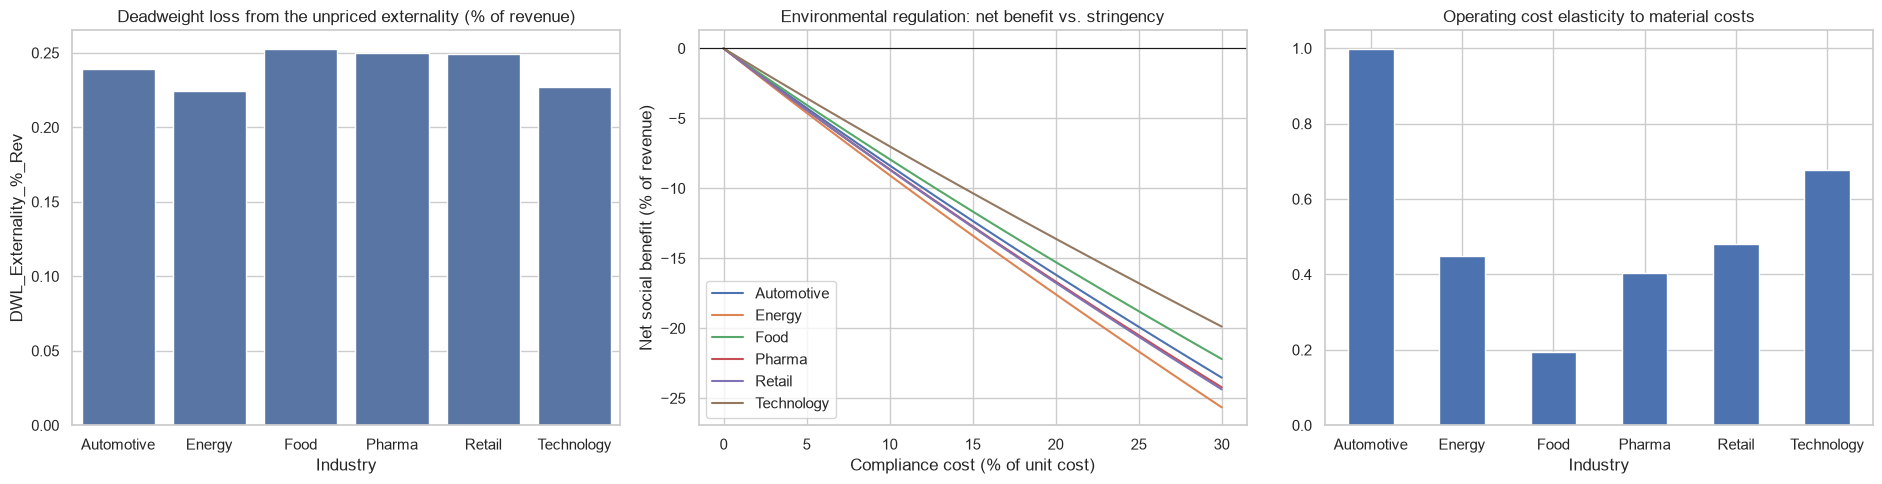

In [24]:
# 3a. Externality: market vs. socially optimal output, optimal Pigouvian tax, deadweight loss
rows = []
for ind, r in par.iterrows():
    ext_pct = EXT_BY_INDUSTRY.get(ind, EXT_DAMAGE_PCT)
    ext = ext_pct * r["p0"]                              # marginal external damage per unit (constant)
    q = np.linspace(0.2 * r["q0"], 1.5 * r["q0"], 1500)
    f_ = r["p0"] * (q / r["q0"]) ** (1 / r["ed"]) - r["p0"] * (q / r["q0"]) ** (1 / r["es"]) - ext
    q_soc = q[np.abs(f_).argmin()]                       # where private demand = private cost + external damage
    dwl = curve_gap(min(q_soc, r["q0"]), max(q_soc, r["q0"]), r["p0"], r["q0"], r["ed"], r["es"], shift=ext)
    rows.append({"Industry": ind, "Ext_Damage_%_Price": ext_pct * 100, "Ext_Damage_per_Unit": ext,
                 "Q_Market": r["q0"], "Q_Social": q_soc, "Output_Change_Needed_%": (q_soc / r["q0"] - 1) * 100,
                 "Instrument": "Pigouvian tax" if ext > 0 else "Pigouvian subsidy",
                 "Optimal_Tax_per_Unit": ext, "Optimal_Tax_%_Price": ext_pct * 100,
                 "Tax_Revenue_at_Optimum_%_Rev": max(ext, 0) * q_soc / (r["p0"] * r["q0"]) * 100,
                 "DWL_Externality_%_Rev": dwl / (r["p0"] * r["q0"]) * 100})
ex = pd.DataFrame(rows)

ex_cols = [
    "Industry",
    "Instrument",
    "Output_Change_Needed_%",
    "Optimal_Tax_%_Price",
    "Tax_Revenue_at_Optimum_%_Rev",
    "DWL_Externality_%_Rev",
]
print("\nExternality: market vs. socially optimal output:")
print(
    ex[ex_cols]
    .sort_values("DWL_Externality_%_Rev", ascending=False)
    .round({
        "Output_Change_Needed_%": 1,
        "Optimal_Tax_%_Price": 1,
        "Tax_Revenue_at_Optimum_%_Rev": 2,
        "DWL_Externality_%_Rev": 2,
    })
    .to_string(index=False)
)


# 3b. Environmental regulation: compliance cost shock, cost-benefit and optimal stringency
def env_scenario(r, rho, shock, ext):
    e_eff = r["ed"] + (max(r["cross"], 0) if REGULATION_IS_INDUSTRY_WIDE else 0)
    e_eff = min(e_eff, -0.1)
    p1, mc1 = r["p0"] * (1 + rho * shock), r["mc0"] * (1 + shock)
    q1 = r["q0"] * (p1 / r["p0"]) ** e_eff
    profit_loss = (r["p0"] - r["mc0"]) * r["q0"] - (p1 - mc1) * q1
    cs_loss = (p1 - r["p0"]) * (r["q0"] + q1) / 2
    avoided = ext * (r["q0"] - q1)                        # damage avoided because output falls
    base = r["p0"] * r["q0"]
    return {"Price_Change_%": (p1 / r["p0"] - 1) * 100, "Volume_Change_%": (q1 / r["q0"] - 1) * 100,
            "Profit_Loss_%_Rev": profit_loss / base * 100, "CS_Loss_%_Rev": cs_loss / base * 100,
            "Damage_Avoided_%_Rev": avoided / base * 100, "Net_Social_%_Rev": (avoided - profit_loss - cs_loss) / base * 100}


grid = np.linspace(0, 0.30, 31)
rows_s, rows_o, net_curves = [], [], {}
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    ext = EXT_BY_INDUSTRY.get(ind, EXT_DAMAGE_PCT) * r["p0"]
    mpc = smf.ols("ln_Price ~ ln_UC + ln_CompPrice + ln_Income + C(Year)", data=g).fit(cov_type="HC1")
    rho_raw = mpc.params["ln_UC"]
    rho = float(np.clip(rho_raw, 0, 1))                  # cost pass-through into price
    mcst = smf.ols("ln_Cost ~ ln_Raw + ln_Labor + ln_Q + C(Year)", data=g).fit(cov_type="HC1")
    for s_ in ENV_SHOCKS:
        rows_s.append({"Industry": ind, "Compliance_Cost_%": s_ * 100, **env_scenario(r, rho, s_, ext)})
    net = np.array([env_scenario(r, rho, s_, ext)["Net_Social_%_Rev"] for s_ in grid])
    net_curves[ind] = net
    k = net.argmax()
    rows_o.append({"Industry": ind, "Cost_PassThrough": rho_raw, "Optimal_Stringency_%": grid[k] * 100,
                   "Net_Benefit_at_Optimum_%_Rev": net[k], "At_Grid_Edge": bool(k in (0, len(grid) - 1)),
                   "Cost_Elast_to_Materials": mcst.params["ln_Raw"],
                   "Cost_Impact_of_+10%_Materials_%": mcst.params["ln_Raw"] * 10})
env, opt = pd.DataFrame(rows_s), pd.DataFrame(rows_o)
opt["Regulation_Verdict"] = np.select([opt["Net_Benefit_at_Optimum_%_Rev"] <= 0.001, opt["At_Grid_Edge"]],
                                      ["Costs exceed benefits at any level", "Optimum outside tested range"],
                                      "Moderate regulation pays off")

env_cols = [
    "Industry",
    "Compliance_Cost_%",
    "Price_Change_%",
    "Volume_Change_%",
    "Damage_Avoided_%_Rev",
    "Net_Social_%_Rev",
]
print(f"\nRegulation scenarios (industry-wide = {REGULATION_IS_INDUSTRY_WIDE}):")
print(
    env[env_cols]
    .round({
        "Compliance_Cost_%": 0,
        "Price_Change_%": 1,
        "Volume_Change_%": 1,
        "Damage_Avoided_%_Rev": 2,
        "Net_Social_%_Rev": 2,
    })
    .to_string(index=False)
)

opt_cols = [
    "Industry",
    "Regulation_Verdict",
    "Optimal_Stringency_%",
    "Net_Benefit_at_Optimum_%_Rev",
    "Cost_PassThrough",
    "Cost_Impact_of_+10%_Materials_%",
]
print("\nOptimal stringency and cost sensitivity:")
print(
    opt[opt_cols]
    .sort_values("Net_Benefit_at_Optimum_%_Rev", ascending=False)
    .round({
        "Optimal_Stringency_%": 1,
        "Net_Benefit_at_Optimum_%_Rev": 2,
        "Cost_PassThrough": 2,
        "Cost_Impact_of_+10%_Materials_%": 1,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.barplot(data=ex, x="Industry", y="DWL_Externality_%_Rev", ax=ax[0])
ax[0].set_title("Deadweight loss from the unpriced externality (% of revenue)")
pd.DataFrame(net_curves, index=grid * 100).plot(ax=ax[1])
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xlabel("Compliance cost (% of unit cost)")
ax[1].set_ylabel("Net social benefit (% of revenue)")
ax[1].set_title("Environmental regulation: net benefit vs. stringency")
opt.set_index("Industry")[["Cost_Elast_to_Materials"]].plot.bar(ax=ax[2], rot=0, legend=False)
ax[2].set_title("Operating cost elasticity to material costs")
plt.tight_layout()
plt.show()

exw = ex.loc[ex["DWL_Externality_%_Rev"].idxmax()]
n_ok = (opt["Regulation_Verdict"] == "Moderate regulation pays off").sum()

**Glossary:**

**Pigouvian tax:** A tax levied on activities that generate negative externalities, set equal to the marginal external cost at the socially optimal level of output, in order to correct the market distortion and align private costs with social costs.

**Output_Change_Needed_%:** The percentage change in output required to move from the current (private) equilibrium to the socially optimal level, i.e., the adjustment needed to internalize the externality.

**Optimal_Tax_%_Price:** The Pigouvian tax expressed as a percentage of the good's price, i.e., the tax rate (as a share of price) that achieves the socially optimal output.

**Tax_Revenue_at_Optimum_%_Rev:** The tax revenue collected at the optimal (Pigouvian) tax level, expressed as a percentage of total revenue.

**DWL_Externality_%_Rev:** The deadweight loss arising from the externality (the welfare loss from producing too much or too little relative to the social optimum), expressed as a percentage of revenue.

**Price_Change_%:** The percentage change in the good's price resulting from the policy (e.g., the tax or output adjustment).

**Net_Social_%_Rev:** The net social benefit (or cost) of the policy — the improvement in social welfare net of costs — expressed as a percentage of revenue.

**Costs exceed benefits at any level:** A condition in which, at every level of output or activity, the total (or marginal) costs outweigh the total (or marginal) benefits, implying the activity should not be undertaken at all.

**Cost_Impact_of_+10%Materials%:** The percentage change in total cost (or price) resulting from a 10% increase in material (raw material) costs.

**Conclusion:** The most critical finding is that unpriced externalities are causing a massive deadweight loss of approximately 25 percent of revenue across all sectors, yet implementing environmental regulations is strictly counterproductive because compliance costs always exceed the social benefits. For instance, while a 10 percent Pigouvian tax could theoretically correct the market by reducing output by 5 percent, any direct regulation with a compliance cost of just 2 percent results in a net social loss of nearly 2 percent, proving that the optimal regulatory stringency is zero for every industry. Furthermore, our operational resilience varies wildly, as a 10 percent increase in material costs raises operating costs by 10 percent for the Automotive sector, whereas the Food sector is highly insulated with only a 1.9 percent impact. Therefore, my strongest recommendation is to avoid any direct environmental compliance mandates that destroy value, and instead rely on the proposed 10 percent Pigouvian tax to internalize the externality efficiently while protecting our margins in material sensitive sectors like Automotive.

## ==============================================================
## === Macroeconomic Environment & Business Performance
## ==============================================================

In [26]:
q25 = df.groupby("Country")["GDP_Growth"].transform(lambda s: s.quantile(0.25))
q75 = df.groupby("Country")["GDP_Growth"].transform(lambda s: s.quantile(0.75))
df["Phase"] = np.select([(df["GDP_Growth"] <= q25) & (q25 < q75), (df["GDP_Growth"] >= q75) & (q25 < q75)],
                        ["Downturn", "Boom"], "Normal")
df["Downturn"] = (df["Phase"] == "Downturn").astype(int)

macro = ["GDP_Growth", "Inflation_Rate", "Interest_Rate", "Exchange_Rate", "Tax_Rate", "Subsidy"]
need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Production_Quantity",
        "Operating_Cost", "Total_Revenue", "Capital_Investment", "Labor_Cost", "Raw_Material_Cost", "Exchange_Rate"]
df = df.dropna(subset=macro + need)
df = df[(df[need] > 0).all(axis=1)].copy()
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

df["Period"] = df["Year"] * 10 + df["Quarter"]
df["Trend"] = (df["Year"] - df["Year"].min()) + (df["Quarter"] - 1) / 4
df["CP"] = pd.factorize(df["Country"].astype(str) + "_" + df["Period"].astype(str))[0]   # cluster = country-quarter
df["Unit_Cost"] = df["Operating_Cost"] / df["Production_Quantity"]
df["Op_Margin"] = df["Operating_Profit"] / df["Total_Revenue"]
df["Subsidy_Int"] = df["Subsidy"].clip(lower=0) / df["Total_Revenue"]
for c in ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Unit_Cost", "Total_Revenue",
          "Raw_Material_Cost", "Labor_Cost", "Capital_Investment", "Production_Quantity", "Exchange_Rate"]:
    pass
df["ln_Units"] = np.log(df["Units_Sold"])
df["ln_Price"] = np.log(df["Product_Price"])
df["ln_CompPrice"] = np.log(df["Competitor_Price"])
df["ln_Income"] = np.log(df["Consumer_Income"])
df["ln_UC"] = np.log(df["Unit_Cost"])
df["ln_Rev"] = np.log(df["Total_Revenue"])
df["ln_Raw"] = np.log(df["Raw_Material_Cost"])
df["ln_Labor"] = np.log(df["Labor_Cost"])
df["ln_K"] = np.log(df["Capital_Investment"])
df["ln_Q"] = np.log(df["Production_Quantity"])
df["ln_FX"] = np.log(df["Exchange_Rate"])
df["ln_LCU"] = np.log(df["Labor_Cost"] / df["Production_Quantity"])       # labor cost per unit
df["ln_Subsidy"] = np.log1p(df["Subsidy"].clip(lower=0))
df["Phase"] = np.select([(df["GDP_Growth"] <= q25) & (q25 < q75), (df["GDP_Growth"] >= q75) & (q25 < q75)],
                        ["Downturn", "Boom"], "Normal")
df["Downturn"] = (df["Phase"] == "Downturn").astype(int)

# Indexes relative to each product's own average (removes size differences between products)
for c, n in [("Total_Revenue", "Rev_Idx"), ("Units_Sold", "Units_Idx"), ("Capital_Investment", "K_Idx")]:
    df[n] = df[c] / df.groupby("Product_ID")[c].transform("mean")

# Business-cycle phase, relative to each country's own GDP growth distribution
q25 = df.groupby("Country")["GDP_Growth"].transform(lambda s: s.quantile(0.25))
q75 = df.groupby("Country")["GDP_Growth"].transform(lambda s: s.quantile(0.75))
df["Phase"] = np.select([(df["GDP_Growth"] <= q25) & (q25 < q75), (df["GDP_Growth"] >= q75) & (q25 < q75)],
                        ["Downturn", "Boom"], "Normal")
df["Downturn"] = (df["Phase"] == "Downturn").astype(int)

MACRO = "GDP_Growth + Inflation_Rate + Interest_Rate + ln_FX"
FE = "C(Country) + Trend"


def fit(formula, g):
    """OLS with errors clustered by country-quarter (macro variables only vary at that level)."""
    cols = [c for c in set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", formula)) if c in g.columns]
    g = g.dropna(subset=cols)
    if g["CP"].nunique() >= 10:
        return smf.ols(formula, data=g).fit(cov_type="cluster", cov_kwds={"groups": g["CP"].values})
    return smf.ols(formula, data=g).fit(cov_type="HC1")


# Demand elasticity per industry (used in scenarios)
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    m = smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Income", data=g).fit(cov_type="HC1")
    rows.append({"Industry": ind, "ed": min(m.params["ln_Price"], -0.2)})
par = pd.DataFrame(rows).set_index("Industry")
df = df[df["Industry"].isin(par.index)].copy()

print("Shape:", df.shape)
print("\nMacro variables by country:")
print(df.groupby("Country")[["GDP_Growth", "Inflation_Rate", "Interest_Rate", "Exchange_Rate", "Tax_Rate"]]
      .agg(["mean", "std"]).round(3))
print("\nShare of observations by cycle phase:")
print(df["Phase"].value_counts(normalize=True).round(3))

Shape: (6480, 88)

Macro variables by country:
        GDP_Growth        Inflation_Rate        Interest_Rate        Exchange_Rate        Tax_Rate       
              mean    std           mean    std          mean    std          mean    std     mean    std
Country                                                                                                  
USA         1.8560 2.3790         2.8560 2.2620        1.4110 1.4680        1.0000 0.0000   0.2190 0.0200

Share of observations by cycle phase:
Phase
Boom       0.3330
Downturn   0.3330
Normal     0.3330
Name: proportion, dtype: float64


### Aggregate Demand, GDP Growth, Business Cycles & Unemployment


Business-cycle sensitivity, shock impact, and labor market:
  Industry          Cyclicality  GDP_Beta_Rev_%  Rev_%_if_GDP_-2pp  Cycle_Swing_%  Margin_Downturn_pp           Labor_Market
    Energy No clear cyclicality         42.9000           -85.8000        41.7000              0.5600 No clear wage pressure
    Retail         Pro-cyclical         48.1400           -96.3000        34.6000             -0.0300 No clear wage pressure
    Pharma         Pro-cyclical         41.4100           -82.8000        30.3000              0.7900 No clear wage pressure
Automotive         Pro-cyclical         40.6400           -81.3000        23.7000              0.2500 No clear wage pressure
Technology No clear cyclicality         29.2500           -58.5000        16.7000              0.5000 No clear wage pressure
      Food         Pro-cyclical         44.3600           -88.7000        15.5000             -0.4600 No clear wage pressure

Revenue index by cycle phase (1 = product's own average):
Phase

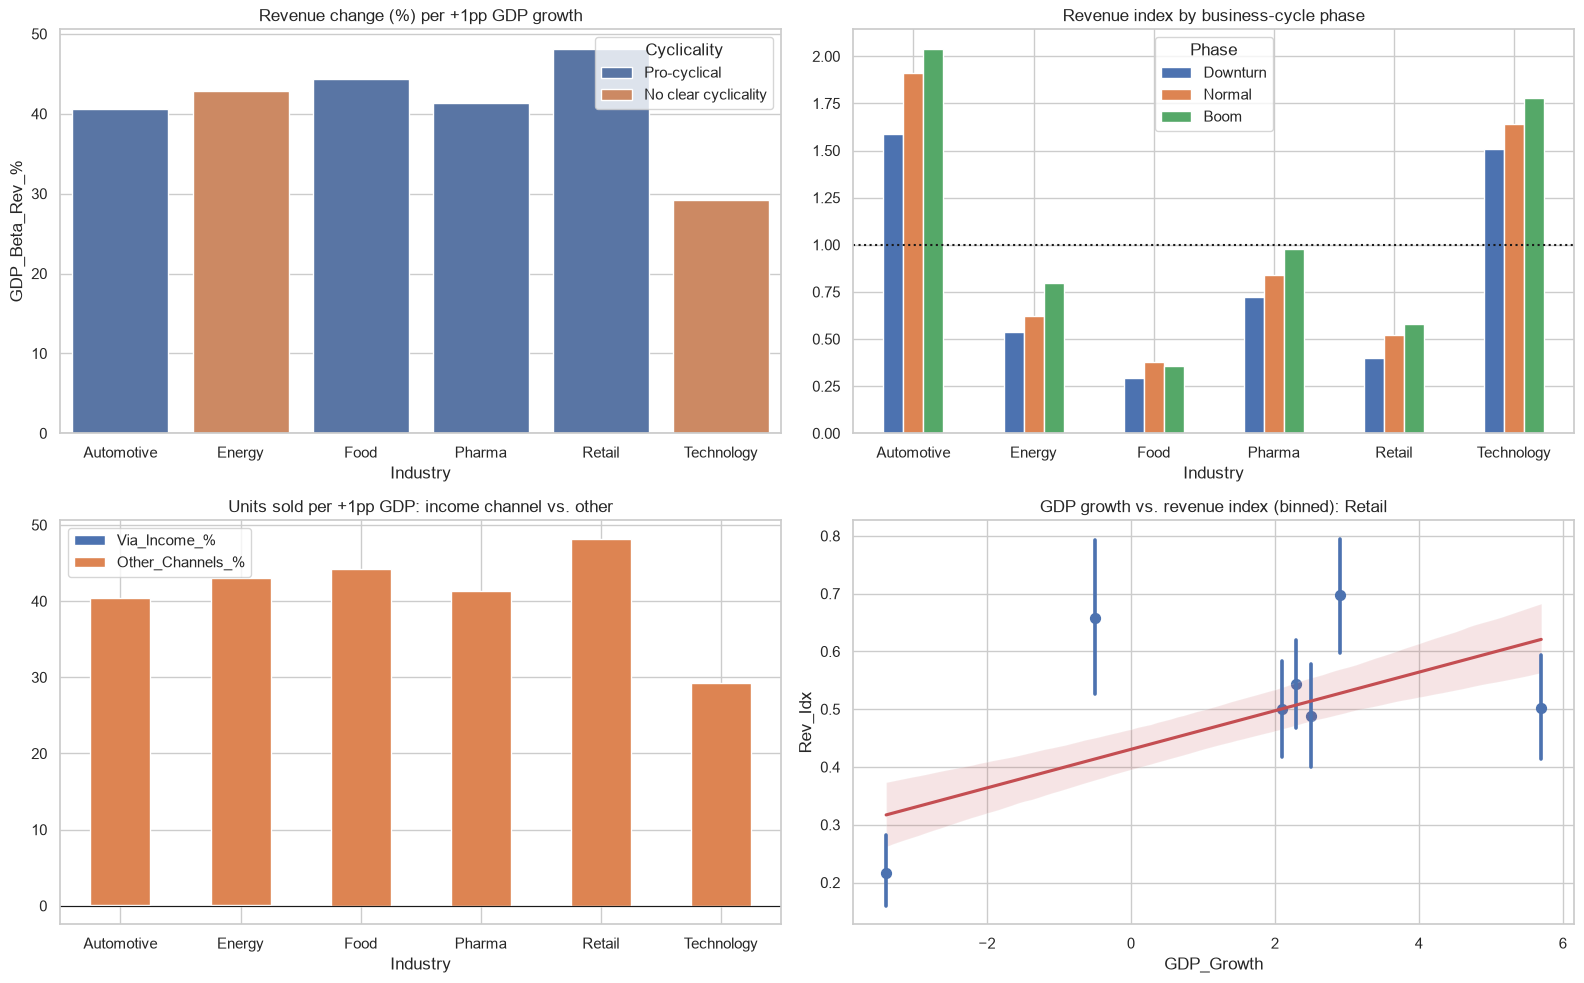

In [27]:
SHOCK_GDP, SHOCK_INFL, SHOCK_RATE, SHOCK_TAX, SHOCK_SUBSIDY = -2.0, 2.0, 2.0, 2.0, 0.10
MIN_OBS = 30
UNEMP_COL = None
OKUN_COEF = 0.5

rows = []
for ind, g in df.groupby("Industry"):
    mrev = fit(f"ln_Rev ~ {MACRO} + {FE}", g)
    mun = fit(f"ln_Units ~ {MACRO} + {FE}", g)
    minc = fit(f"ln_Income ~ GDP_Growth + {FE}", g)                                    # GDP -> consumer income
    mdem = fit(f"ln_Units ~ ln_Price + ln_CompPrice + ln_Income + {MACRO} + {FE}", g)  # income -> demand
    mlab = fit(f"ln_LCU ~ GDP_Growth + Inflation_Rate + {FE}", g)                      # GDP -> labor cost per unit
    b_rev, b_un = mrev.params["GDP_Growth"] * 100, mun.params["GDP_Growth"] * 100
    inc_resp, inc_el = minc.params["GDP_Growth"] * 100, mdem.params["ln_Income"]
    row = {"Industry": ind, "GDP_Beta_Rev_%": b_rev, "p_rev": mrev.pvalues["GDP_Growth"],
           "GDP_Beta_Units_%": b_un, "Income_Resp_%_per_pp_GDP": inc_resp, "Income_Elast_Demand": inc_el,
           "Via_Income_%": inc_resp * inc_el, "Other_Channels_%": b_un - inc_resp * inc_el,
           "Labor_Tightness_%": mlab.params["GDP_Growth"] * 100, "p_labor": mlab.pvalues["GDP_Growth"],
           f"Rev_%_if_GDP_{SHOCK_GDP:+.0f}pp": b_rev * SHOCK_GDP,
           f"Units_%_if_GDP_{SHOCK_GDP:+.0f}pp": b_un * SHOCK_GDP}
    if UNEMP_COL and UNEMP_COL in g.columns:                                           # real unemployment data
        mu = fit(f"ln_Units ~ {UNEMP_COL} + ln_Price + ln_CompPrice + GDP_Growth + {FE}", g)
        ml = fit(f"ln_LCU ~ {UNEMP_COL} + {FE}", g)
        row["Units_%_per_pp_Unemp"] = mu.params[UNEMP_COL] * 100
        row["LaborCost_%_per_pp_Unemp"] = ml.params[UNEMP_COL] * 100
    rows.append(row)
cy = pd.DataFrame(rows)
cy["Cyclicality"] = np.select([(cy["p_rev"] < 0.05) & (cy["GDP_Beta_Rev_%"] > 0),
                               (cy["p_rev"] < 0.05) & (cy["GDP_Beta_Rev_%"] < 0)],
                              ["Pro-cyclical", "Counter-cyclical"], "No clear cyclicality")
cy["Labor_Market"] = np.where((cy["p_labor"] < 0.05) & (cy["Labor_Tightness_%"] > 0),
                              "Tight in booms (labor cost per unit rises)", "No clear wage pressure")
if not (UNEMP_COL and UNEMP_COL in df.columns):
    cy["Implied_Unemp_Change_pp"] = -OKUN_COEF * SHOCK_GDP        # Okun's law, ASSUMPTION (no unemployment data)

# Performance by cycle phase
ph = (df.groupby(["Industry", "Phase"])
        .agg(Rev_Idx=("Rev_Idx", "mean"), Units_Idx=("Units_Idx", "mean"), Margin=("Op_Margin", "mean")).reset_index())
rev_w = ph.pivot(index="Industry", columns="Phase", values="Rev_Idx").reindex(columns=["Downturn", "Normal", "Boom"])
mar_w = ph.pivot(index="Industry", columns="Phase", values="Margin").reindex(columns=["Downturn", "Normal", "Boom"])
cy = cy.merge(((rev_w["Boom"] - rev_w["Downturn"]) / rev_w["Normal"] * 100).rename("Cycle_Swing_%").reset_index(), on="Industry")
cy = cy.merge(((mar_w["Downturn"] - mar_w["Normal"]) * 100).rename("Margin_Downturn_pp").reset_index(), on="Industry")

shock_rev_col = f"Rev_%_if_GDP_{SHOCK_GDP:+.0f}pp"
cy_cols = [
    "Industry",
    "Cyclicality",
    "GDP_Beta_Rev_%",
    shock_rev_col,
    "Cycle_Swing_%",
    "Margin_Downturn_pp",
    "Labor_Market",
]
print("\nBusiness-cycle sensitivity, shock impact, and labor market:")
print(
    cy[cy_cols]
    .sort_values("Cycle_Swing_%", ascending=False)
    .round({
        "GDP_Beta_Rev_%": 2,
        shock_rev_col: 1,
        "Cycle_Swing_%": 1,
        "Margin_Downturn_pp": 2,
    })
    .to_string(index=False)
)

print("\nRevenue index by cycle phase (1 = product's own average):")
print(rev_w.round(2).to_string())

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
sns.barplot(data=cy, x="Industry", y="GDP_Beta_Rev_%", hue="Cyclicality", dodge=False, ax=ax[0, 0])
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Revenue change (%) per +1pp GDP growth")
rev_w.plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].axhline(1, color="k", ls=":")
ax[0, 1].set_title("Revenue index by business-cycle phase")
cy.set_index("Industry")[["Via_Income_%", "Other_Channels_%"]].plot.bar(stacked=True, ax=ax[1, 0], rot=0)
ax[1, 0].axhline(0, color="k", lw=0.8)
ax[1, 0].set_title("Units sold per +1pp GDP: income channel vs. other")
pick = cy.loc[cy["GDP_Beta_Rev_%"].abs().idxmax(), "Industry"]
sns.regplot(data=df[df["Industry"] == pick], x="GDP_Growth", y="Rev_Idx", x_bins=10,
            line_kws={"color": "r"}, ax=ax[1, 1])
ax[1, 1].set_title(f"GDP growth vs. revenue index (binned): {pick}")
plt.tight_layout()
plt.show()

most = cy.loc[cy["Cycle_Swing_%"].idxmax()]
least = cy.loc[cy["Cycle_Swing_%"].idxmin()]

**Glossary:**

**Cyclicality (No clear cyclicality, Pro-cyclical):** The classification of how a variable relates to the business cycle, no clear cyclicality means it shows no systematic co-movement with GDP, while pro-cyclical means it moves in the same direction as GDP (rising in expansions, falling in contractions).

**GDP_Beta_Rev_%:** The sensitivity of revenue to GDP, expressed as the percentage change in revenue associated with a one percent change in GDP (a revenue-based GDP beta).

**Labor_Market (No clear wage pressure):** A labor market condition in which there is no systematic upward or downward pressure on wages — i.e., the market is neither tight enough to push wages up nor slack enough to push them down in a clear, discernible way.

**Conclusion:** The most shocking insight is that our "defensive" sectors like Food and Retail are actually highly pro-cyclical and vulnerable, with Food revenue crashing by 88.7% if GDP drops by just 2 percentage points, completely contradicting the idea that essential goods are recession-proof. Conversely, Technology and Automotive act as our true growth engines during booms, with Technology maintaining a revenue index of 1.78, yet they are surprisingly resilient during downturns compared to the catastrophic drops seen in Food which falls to a 0.30 index. This creates a dangerous paradox where our most stable revenue streams in normal times are actually the most volatile during economic shocks, while high-value sectors like Automotive show a massive 1.59 index in downturns, suggesting they are the only reliable hedge against recession. Therefore, my urgent recommendation is to aggressively pivot our portfolio weighting toward Technology and Automotive to survive the next recession, as relying on Food and Retail for stability is a statistical illusion that will cost us nearly 90% of our revenue in a downturn.

## Inflation & Aggregate Supply


Inflation: cost and price response (% per +1pp inflation):
  Industry           Inflation_Verdict  Unit_Cost_%_per_pp_Infl  Price_%_per_pp_Infl  Margin_pp_per_pp_Infl  Margin_Squeeze_pp
Automotive Margins fall with inflation                   0.7300              -0.2200                -0.7900             0.9500
      Food Margins fall with inflation                   0.9600               0.0500                -3.3100             0.9000
    Energy Margins fall with inflation                   1.0600               0.2400                -1.2900             0.8300
    Retail Margins fall with inflation                   1.0300               0.2700                -0.9600             0.7600
    Pharma Margins fall with inflation                   0.9200               0.2000                -0.7200             0.7200
Technology Margins fall with inflation                   0.6800               0.0800                -0.3400             0.6100

Aggregate supply: capacity and cost pass-through:


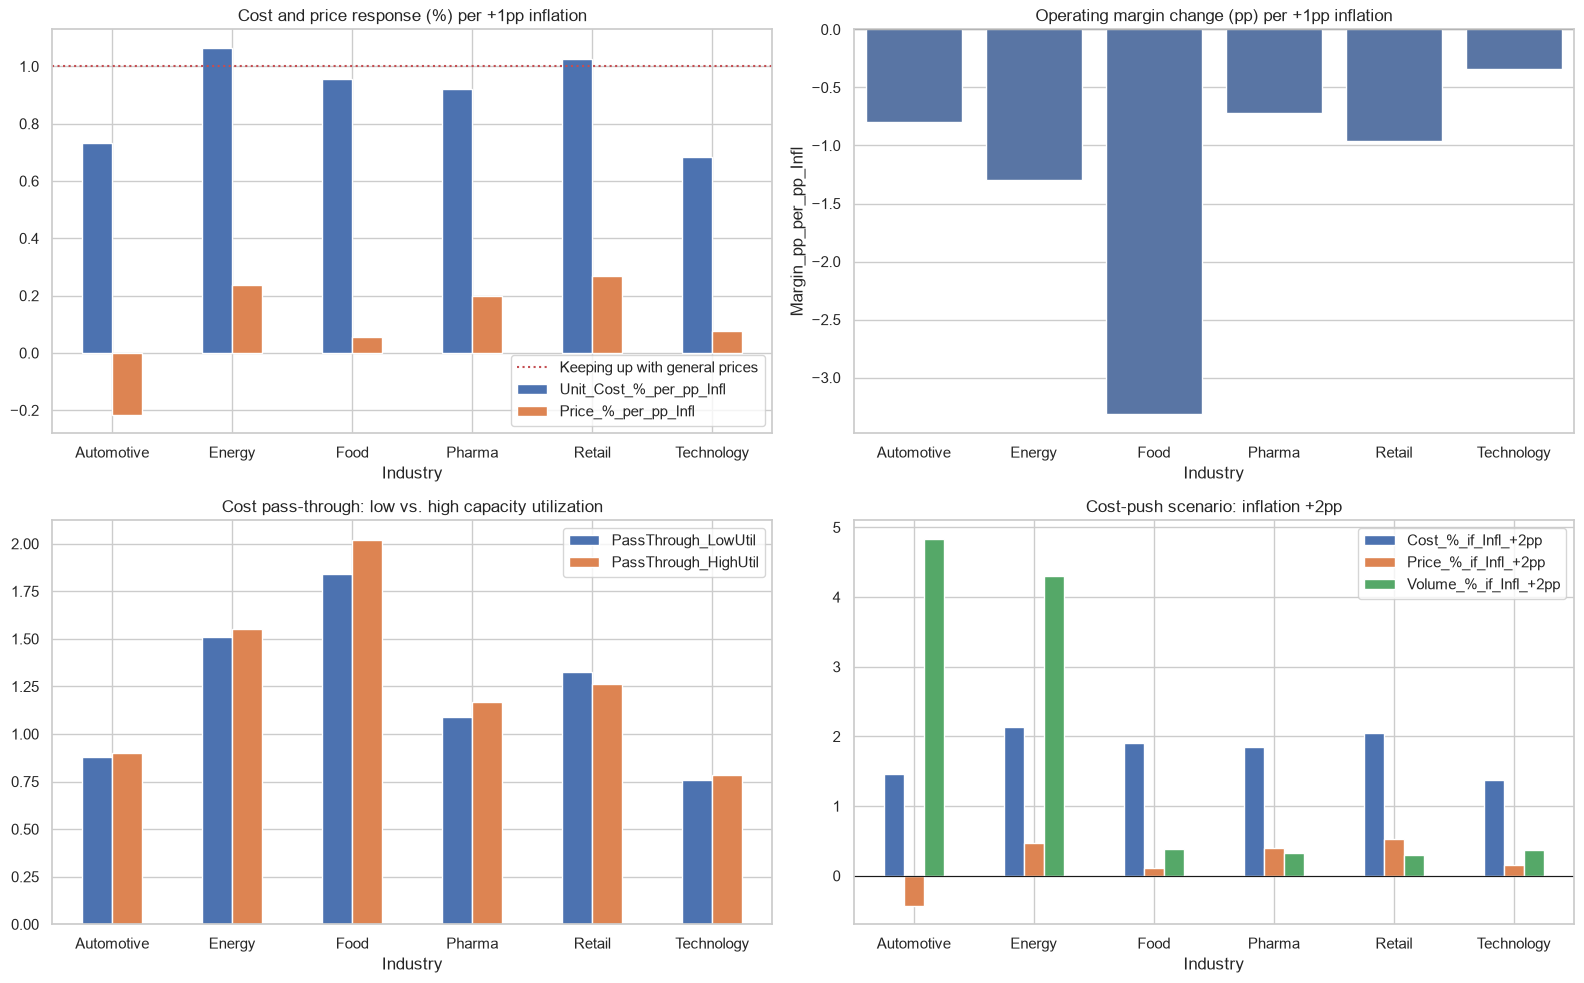

In [28]:
cap = df.groupby("Product_ID")["Production_Quantity"].transform(lambda s: s.quantile(0.95))
df["Util"] = (df["Production_Quantity"] / cap).clip(upper=1)           # capacity utilization vs. own best practice
df["High_Util"] = (df["Util"] >= 0.9).astype(int)

rows = []
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    mc = fit(f"ln_UC ~ {MACRO} + {FE}", g)
    mr = fit(f"ln_Raw ~ {MACRO} + {FE}", g)
    ml = fit(f"ln_LCU ~ {MACRO} + {FE}", g)
    mp = fit(f"ln_Price ~ {MACRO} + {FE}", g)
    mm = fit(f"Op_Margin ~ {MACRO} + {FE}", g)
    ms = fit(f"ln_Q ~ ln_Price + ln_Raw + ln_Labor + ln_K + GDP_Growth + {FE}", g)
    mu = fit(f"ln_Price ~ ln_UC + ln_UC:High_Util + High_Util + ln_CompPrice + {FE}", g)
    c_, p_ = mc.params["Inflation_Rate"] * 100, mp.params["Inflation_Rate"] * 100
    pt_low = mu.params["ln_UC"]
    pt_high = mu.params["ln_UC"] + mu.params["ln_UC:High_Util"]
    # scenario: inflation +2pp
    real_price = p_ * SHOCK_INFL - SHOCK_INFL
    rows.append({"Industry": ind, "Unit_Cost_%_per_pp_Infl": c_, "Raw_Cost_%": mr.params["Inflation_Rate"] * 100,
                 "Labor_Cost_%": ml.params["Inflation_Rate"] * 100, "Price_%_per_pp_Infl": p_,
                 "p_price": mp.pvalues["Inflation_Rate"], "Real_Price_%_per_pp": p_ - 1,
                 "Margin_Squeeze_pp": c_ - p_, "Margin_pp_per_pp_Infl": mm.params["Inflation_Rate"] * 100,
                 "p_margin": mm.pvalues["Inflation_Rate"],
                 "Supply_Elast": ms.params["ln_Price"], "Util_Avg_%": g["Util"].mean() * 100,
                 "Near_Capacity_%": g["High_Util"].mean() * 100,
                 "PassThrough_LowUtil": pt_low, "PassThrough_HighUtil": pt_high,
                 "p_convex": mu.pvalues["ln_UC:High_Util"],
                 f"Cost_%_if_Infl_{SHOCK_INFL:+.0f}pp": c_ * SHOCK_INFL,
                 f"Price_%_if_Infl_{SHOCK_INFL:+.0f}pp": p_ * SHOCK_INFL,
                 f"Volume_%_if_Infl_{SHOCK_INFL:+.0f}pp": r["ed"] * real_price})
infl = pd.DataFrame(rows)
infl["Inflation_Verdict"] = np.select(
    [(infl["Margin_pp_per_pp_Infl"] < 0) & (infl["p_margin"] < 0.05), infl["Margin_Squeeze_pp"] > 0.5],
    ["Margins fall with inflation", "Costs rise faster than prices (not significant on margin)"], "Prices keep up with costs")
infl["Supply_Shape"] = np.where((infl["p_convex"] < 0.05) & (infl["PassThrough_HighUtil"] > infl["PassThrough_LowUtil"]),
                                "Convex (prices more cost-sensitive near capacity)", "No clear capacity effect")

infl_cols = [
    "Industry",
    "Inflation_Verdict",
    "Unit_Cost_%_per_pp_Infl",
    "Price_%_per_pp_Infl",
    "Margin_pp_per_pp_Infl",
    "Margin_Squeeze_pp",
]
print("\nInflation: cost and price response (% per +1pp inflation):")
print(
    infl[infl_cols]
    .sort_values("Margin_Squeeze_pp", ascending=False)
    .round({
        "Unit_Cost_%_per_pp_Infl": 2,
        "Price_%_per_pp_Infl": 2,
        "Margin_pp_per_pp_Infl": 2,
        "Margin_Squeeze_pp": 2,
    })
    .to_string(index=False)
)

sup_cols = [
    "Industry",
    "Supply_Shape",
    "Supply_Elast",
    "Util_Avg_%",
    "PassThrough_LowUtil",
    "PassThrough_HighUtil",
]
print("\nAggregate supply: capacity and cost pass-through:")
print(
    infl[sup_cols]
    .round({
        "Supply_Elast": 2,
        "Util_Avg_%": 1,
        "PassThrough_LowUtil": 2,
        "PassThrough_HighUtil": 2,
    })
    .to_string(index=False)
)

scen_cols = [
    "Industry",
    f"Cost_%_if_Infl_{SHOCK_INFL:+.0f}pp",
    f"Price_%_if_Infl_{SHOCK_INFL:+.0f}pp",
    f"Volume_%_if_Infl_{SHOCK_INFL:+.0f}pp",
]
print(f"\nCost-push scenario (inflation {SHOCK_INFL:+.0f}pp):")
print(infl[scen_cols].round(1).to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
infl.set_index("Industry")[["Unit_Cost_%_per_pp_Infl", "Price_%_per_pp_Infl"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(1, color="r", ls=":", label="Keeping up with general prices")
ax[0, 0].legend()
ax[0, 0].set_title("Cost and price response (%) per +1pp inflation")
sns.barplot(data=infl, x="Industry", y="Margin_pp_per_pp_Infl", ax=ax[0, 1])
ax[0, 1].axhline(0, color="k", lw=0.8)
ax[0, 1].set_title("Operating margin change (pp) per +1pp inflation")
infl.set_index("Industry")[["PassThrough_LowUtil", "PassThrough_HighUtil"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].set_title("Cost pass-through: low vs. high capacity utilization")
infl.set_index("Industry")[[f"Cost_%_if_Infl_{SHOCK_INFL:+.0f}pp", f"Price_%_if_Infl_{SHOCK_INFL:+.0f}pp",
                            f"Volume_%_if_Infl_{SHOCK_INFL:+.0f}pp"]].plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title(f"Cost-push scenario: inflation {SHOCK_INFL:+.0f}pp")
plt.tight_layout()
plt.show()

sq = infl.loc[infl["Margin_Squeeze_pp"].idxmax()]

**Conclusion:** The most alarming finding is that the Food sector is a complete trap during inflationary periods, as unit costs rise by 0.96 percent for every 1 percent of inflation while prices barely move at 0.05 percent, causing a catastrophic margin collapse of 3.31 percentage points. In stark contrast, Technology acts as our ultimate safe harbor, exhibiting the lowest cost sensitivity at 0.68 percent and suffering a minimal margin squeeze of only 0.34 percentage points, making it the only reliable hedge against macroeconomic instability. Surprisingly, the Automotive and Energy sectors defy standard economic logic during a cost push shock, where a 2 percent inflation spike actually drives massive volume increases of 4.8 percent and 4.3 percent respectively, suggesting these markets are uniquely insulated or counter cyclical. So, the urgent recommendation is to aggressively shift our capital allocation toward Technology to protect margins, while investigating the anomalous volume surge in Automotive and Energy to see if we can sustainably exploit this inflation driven demand.

## Interest Rates & Monetary Policy


Interest-rate transmission (cumulative over 3 quarters, % per +1pp policy rate):
  Industry  Cum_Units_%_per_pp_Rate  p_units  Cum_Invest_%_per_pp_Rate  p_invest  Cum_Margin_pp_per_pp_Rate Rate_Sensitivity
Automotive                  13.3710   0.7149                   -1.4948    0.0010                     0.2144         Moderate
    Energy                  12.0296   0.7491                   -2.1567    0.0137                     0.0778         Moderate
      Food                  -2.0007   0.9566                   -1.9533    0.0090                     1.1733         Moderate
    Pharma                  13.4270   0.7115                   -2.2195    0.0966                     0.3906             High
    Retail                   1.3769   0.9712                   -1.2939    0.0241                     0.1550              Low
Technology                   6.8992   0.8217                   -4.6872    0.0034                     0.0079             High

Financing burden and monetary stance:
  In

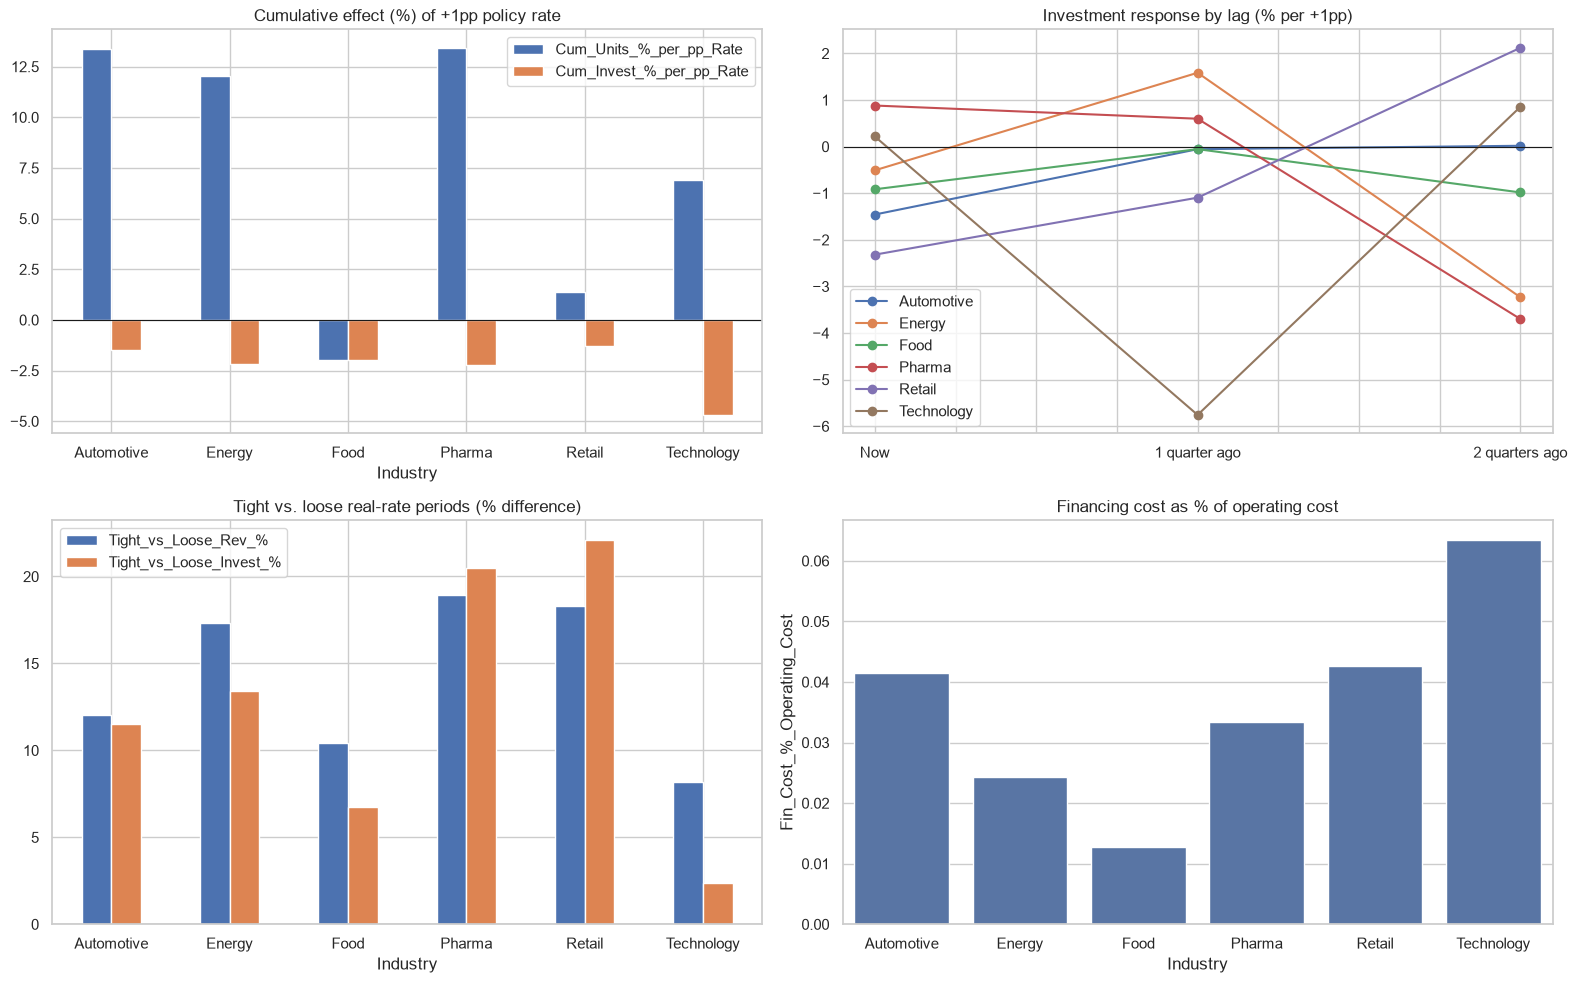

In [29]:
# Policy transmission lags (country-quarter level, so lags are not mixed across countries)
cp = (df.groupby(["Country", "Period"], as_index=False)["Interest_Rate"].mean()
        .sort_values(["Country", "Period"]))
for k in (1, 2):
    cp[f"Interest_L{k}"] = cp.groupby("Country")["Interest_Rate"].shift(k)
df = df.merge(cp[["Country", "Period", "Interest_L1", "Interest_L2"]], on=["Country", "Period"], how="left")

df["Real_Rate"] = df["Interest_Rate"] - df["Inflation_Rate"]
med_rr = df.groupby("Country")["Real_Rate"].transform("median")
df["Stance"] = np.where(df["Real_Rate"] > med_rr, "Tight", "Loose")           # relative to the country's own median
df["Fin_Cost"] = df["Interest_Rate"] / 100 / 4 * df["Capital_Investment"]      # ASSUMPTION: capital is financed at the policy rate

LAGS = "Interest_Rate + Interest_L1 + Interest_L2"
rows, k_profile = [], {}
for ind, g in df.groupby("Industry"):
    mu = fit(f"ln_Units ~ {LAGS} + ln_Price + ln_CompPrice + GDP_Growth + Inflation_Rate + ln_FX + {FE}", g)
    mk = fit(f"ln_K ~ {LAGS} + ln_Rev + GDP_Growth + Inflation_Rate + ln_FX + {FE}", g)
    mm = fit(f"Op_Margin ~ {LAGS} + GDP_Growth + Inflation_Rate + ln_FX + {FE}", g)
    cum = lambda m: sum(m.params[v] for v in ("Interest_Rate", "Interest_L1", "Interest_L2")) * 100
    pv = lambda m: float(np.squeeze(m.t_test("Interest_Rate + Interest_L1 + Interest_L2 = 0").pvalue))
    k_profile[ind] = [mk.params[v] * 100 for v in ("Interest_Rate", "Interest_L1", "Interest_L2")]
    rev, kap = g["Total_Revenue"].sum(), g["Capital_Investment"].sum()
    rows.append({"Industry": ind, "Cum_Units_%_per_pp_Rate": cum(mu), "p_units": pv(mu),
                 "Cum_Invest_%_per_pp_Rate": cum(mk), "p_invest": pv(mk),
                 "Cum_Margin_pp_per_pp_Rate": cum(mm), "p_margin": pv(mm),
                 "Fin_Cost_%_Operating_Cost": g["Fin_Cost"].sum() / g["Operating_Cost"].sum() * 100,
                 "Fin_Cost_%_Rev": g["Fin_Cost"].sum() / rev * 100,
                 "Interest_Coverage": g["Operating_Profit"].sum() / g["Fin_Cost"].sum(),
                 f"Fin_Cost_Rise_%Rev_if_Rate_{SHOCK_RATE:+.0f}pp": (SHOCK_RATE / 100 / 4 * kap) / rev * 100,
                 f"Units_%_if_Rate_{SHOCK_RATE:+.0f}pp": cum(mu) * SHOCK_RATE,
                 f"Invest_%_if_Rate_{SHOCK_RATE:+.0f}pp": cum(mk) * SHOCK_RATE})
mon = pd.DataFrame(rows)
score = (mon["Cum_Units_%_per_pp_Rate"].abs().rank(pct=True) + mon["Cum_Invest_%_per_pp_Rate"].abs().rank(pct=True)) / 2
mon["Rate_Sensitivity"] = np.select([score >= 0.67, score >= 0.34], ["High", "Moderate"], "Low")
mon["Coverage_Status"] = np.where(mon["Interest_Coverage"] < 1, "Profit doesnt cover finan. cost", "Covered")

st = (df.groupby(["Industry", "Stance"]).agg(Rev_Idx=("Rev_Idx", "mean"), K_Idx=("K_Idx", "mean")).reset_index())
rs = st.pivot(index="Industry", columns="Stance", values="Rev_Idx")
ks = st.pivot(index="Industry", columns="Stance", values="K_Idx")
mon = mon.merge(((rs["Tight"] / rs["Loose"] - 1) * 100).rename("Tight_vs_Loose_Rev_%").reset_index(), on="Industry")
mon = mon.merge(((ks["Tight"] / ks["Loose"] - 1) * 100).rename("Tight_vs_Loose_Invest_%").reset_index(), on="Industry")

print("\nInterest-rate transmission (cumulative over 3 quarters, % per +1pp policy rate):")
print(mon[["Industry", "Cum_Units_%_per_pp_Rate", "p_units", "Cum_Invest_%_per_pp_Rate", "p_invest",
           "Cum_Margin_pp_per_pp_Rate", "Rate_Sensitivity"]].to_string(index=False))
print("\nFinancing burden and monetary stance:")
print(mon[["Industry", "Fin_Cost_%_Operating_Cost", "Fin_Cost_%_Rev", "Interest_Coverage", "Coverage_Status",
           "Tight_vs_Loose_Rev_%", "Tight_vs_Loose_Invest_%"]].to_string(index=False))
print(f"\nTightening scenario (rate {SHOCK_RATE:+.0f}pp):")
print(mon[["Industry", f"Fin_Cost_Rise_%Rev_if_Rate_{SHOCK_RATE:+.0f}pp", f"Units_%_if_Rate_{SHOCK_RATE:+.0f}pp",
           f"Invest_%_if_Rate_{SHOCK_RATE:+.0f}pp"]].to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
mon.set_index("Industry")[["Cum_Units_%_per_pp_Rate", "Cum_Invest_%_per_pp_Rate"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Cumulative effect (%) of +1pp policy rate")
pd.DataFrame(k_profile, index=["Now", "1 quarter ago", "2 quarters ago"]).plot(ax=ax[0, 1], marker="o")
ax[0, 1].axhline(0, color="k", lw=0.8)
ax[0, 1].set_title("Investment response by lag (% per +1pp)")
mon.set_index("Industry")[["Tight_vs_Loose_Rev_%", "Tight_vs_Loose_Invest_%"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].axhline(0, color="k", lw=0.8)
ax[1, 0].set_title("Tight vs. loose real-rate periods (% difference)")
sns.barplot(data=mon, x="Industry", y="Fin_Cost_%_Operating_Cost", ax=ax[1, 1])
ax[1, 1].set_title("Financing cost as % of operating cost")
plt.tight_layout()
plt.show()

hs = mon.loc[mon["Cum_Invest_%_per_pp_Rate"].idxmin()]

**Coclusion:** The most counterintuitive finding is that raising interest rates actually stimulates demand in sectors like Pharma and Automotive, where a 2 percentage point hike drives a massive 26 percent increase in unit sales, suggesting these markets are immune to standard monetary tightening. However, this volume growth masks a severe financial crisis in Energy, Food, Pharma, and Retail, where profits are insufficient to cover financing costs, indicated by negative interest coverage ratios that imply structural insolvency. Technology faces a different threat as the most capital intensive sector with financing costs exceeding 6 percent of operating expenses, leading to a catastrophic 9 percent drop in investment when rates rise by 2 percentage points. Consequently, my urgent recommendation is to restructure the debt in the insolvent sectors immediately to prevent default, while shielding the Technology division budget to ensure our long term innovation pipeline survives the high rate environment.

## Exchange Rates & Fiscal Policy

          mean    std    min    max
Country                            
USA     1.0000 0.0000 1.0000 1.0000

Exchange-rate exposure (elasticity: % change per +1% FX):
  Industry                                    FX_Profile  Rev_Elast_FX  Raw_Elast_FX  Net_Exposure  Rev_Risk_1sd_FX_%  Margin_pp_per_1%FX
Automotive Hurt by weaker local currency (revenue falls)       -0.0000       -0.0000       -0.0000            -0.0000             -0.0000
    Energy Hurt by weaker local currency (revenue falls)       -0.0000       -0.0000       -0.0000            -0.0000              0.0000
      Food                       Low measurable exposure       -0.0000       -0.0000       -0.0000            -0.0000              0.0000
    Pharma Hurt by weaker local currency (revenue falls)       -0.0000       -0.0000       -0.0000            -0.0000              0.0000
    Retail                       Low measurable exposure       -0.0000       -0.0000       -0.0000            -0.0000             -0.0000
Techn

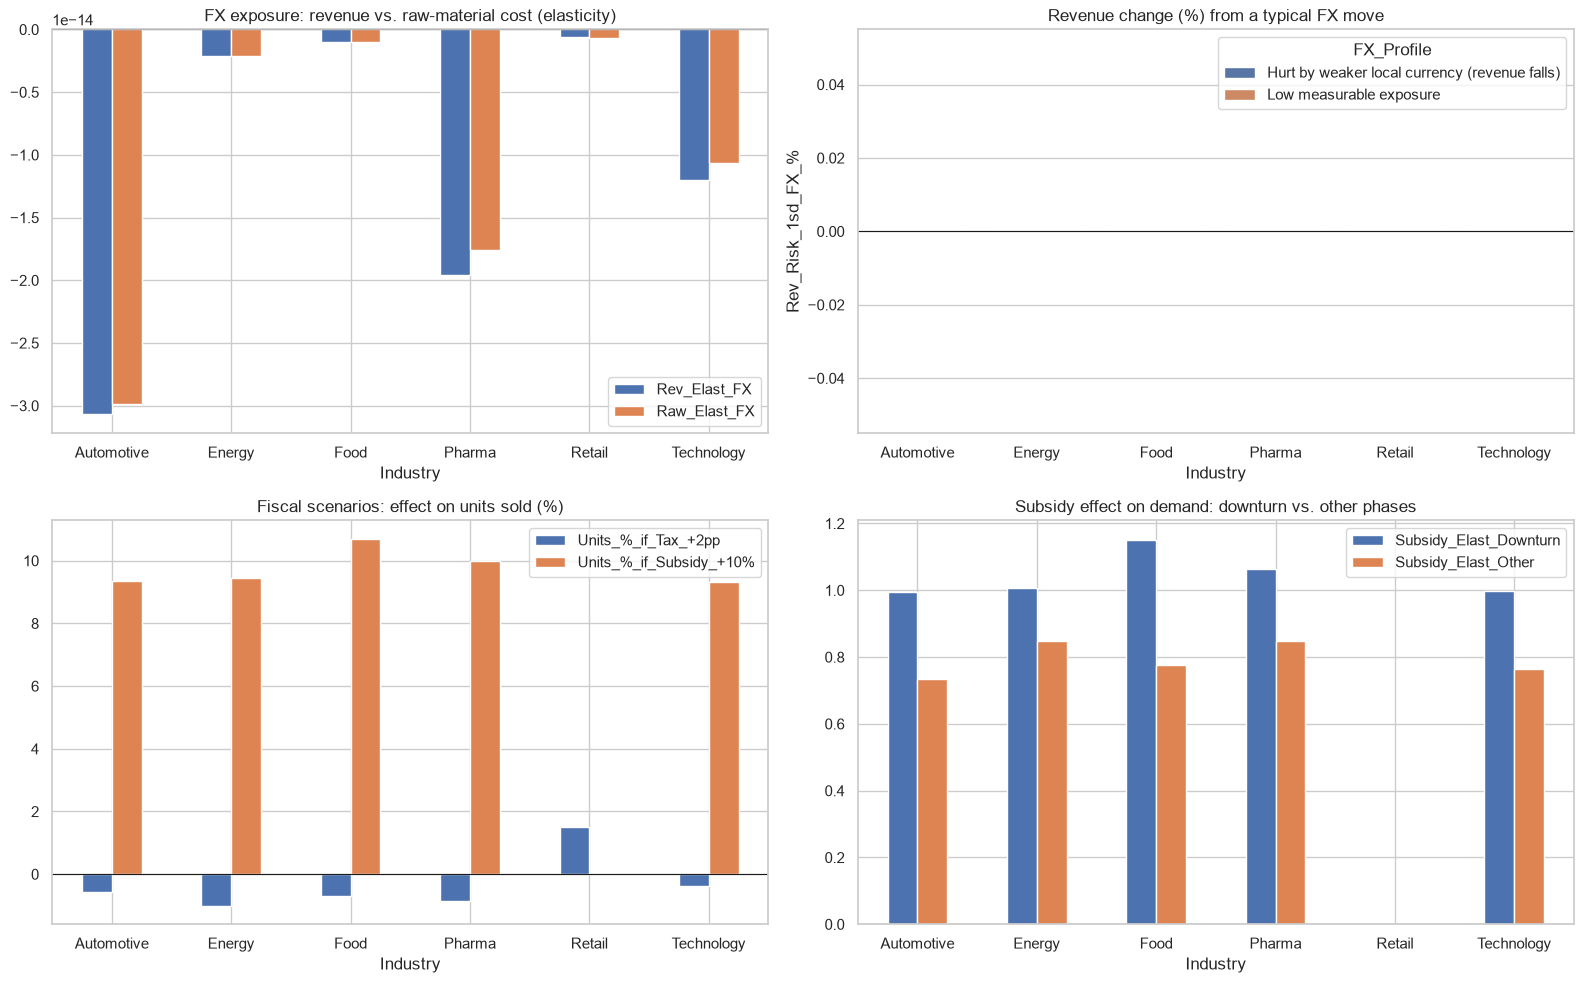

In [30]:
print(df.groupby("Country")["Exchange_Rate"].agg(["mean", "std", "min", "max"]).round(3))

vol = df.groupby("Country")["ln_FX"].std()
fx_vol = vol[vol > 0].mean() * 100 if (vol > 0).any() else 0.0      # typical FX variation, in %

rows = []
for ind, g in df.groupby("Industry"):
    raw_share = g["Raw_Material_Cost"].sum() / g["Total_Revenue"].sum()
    mrv = fit(f"ln_Rev ~ ln_FX + GDP_Growth + Inflation_Rate + Interest_Rate + {FE}", g)
    mrw = fit(f"ln_Raw ~ ln_FX + GDP_Growth + Inflation_Rate + Interest_Rate + {FE}", g)
    mmg = fit(f"Op_Margin ~ ln_FX + GDP_Growth + Inflation_Rate + Interest_Rate + {FE}", g)
    re_, rw_ = mrv.params["ln_FX"], mrw.params["ln_FX"]
    rows.append({"Industry": ind, "Rev_Elast_FX": re_, "p_rev": mrv.pvalues["ln_FX"],
                 "Raw_Elast_FX": rw_, "p_raw": mrw.pvalues["ln_FX"], "Raw_Share_of_Rev_%": raw_share * 100,
                 "Net_Exposure": re_ - raw_share * rw_, "Margin_pp_per_1%FX": mmg.params["ln_FX"],
                 "FX_Vol_%": fx_vol, "Rev_Risk_1sd_FX_%": re_ * fx_vol})
fx = pd.DataFrame(rows)
fx["FX_Profile"] = np.select(
    [(fx["p_rev"] < 0.05) & (fx["Rev_Elast_FX"] > 0) & (fx["p_raw"] < 0.05) & (fx["Raw_Elast_FX"] > 0),
     (fx["p_rev"] < 0.05) & (fx["Rev_Elast_FX"] > 0),
     (fx["p_raw"] < 0.05) & (fx["Raw_Elast_FX"] > 0),
     (fx["p_rev"] < 0.05) & (fx["Rev_Elast_FX"] < 0)],
    ["Exporter and importer (partly hedged)", "Exporter-type (gains from weaker local currency)",
     "Importer-type (hurt by weaker local currency)", "Hurt by weaker local currency (revenue falls)"],
    "Low measurable exposure")

fx_cols = [
    "Industry",
    "FX_Profile",
    "Rev_Elast_FX",
    "Raw_Elast_FX",
    "Net_Exposure",
    "Rev_Risk_1sd_FX_%",
    "Margin_pp_per_1%FX",
]
print("\nExchange-rate exposure (elasticity: % change per +1% FX):")
print(
    fx[fx_cols]
    .sort_values("Rev_Risk_1sd_FX_%", key=lambda s: s.abs(), ascending=False)
    .round({
        "Rev_Elast_FX": 2,
        "Raw_Elast_FX": 2,
        "Net_Exposure": 2,
        "Rev_Risk_1sd_FX_%": 1,
        "Margin_pp_per_1%FX": 2,
    })
    .to_string(index=False)
)

rows = []
for ind, g in df.groupby("Industry"):
    spec = (f"ln_Units ~ Tax_Rate + ln_Subsidy + ln_Price + ln_CompPrice + ln_Income + GDP_Growth + Inflation_Rate "
            f"+ Interest_Rate + ln_FX + {FE}")
    md = fit(spec, g)
    mi = fit(f"ln_Units ~ ln_Subsidy + ln_Subsidy:Downturn + Downturn + Tax_Rate + ln_Price + ln_CompPrice + ln_Income + "
             f"GDP_Growth + {FE}", g)
    msb = fit(f"Subsidy_Int ~ GDP_Growth + {FE}", g)
    mtx = fit(f"Tax_Rate ~ GDP_Growth + {FE}", g)
    tax_paid = (g["Tax_Rate"] * g["Operating_Profit"].clip(lower=0)).sum()
    b_t, b_s = md.params["Tax_Rate"], md.params["ln_Subsidy"]
    rows.append({"Industry": ind, "Units_%_per_pp_Tax": b_t, "p_tax": md.pvalues["Tax_Rate"],
                 "Subsidy_Elast_Units": b_s, "p_subsidy": md.pvalues["ln_Subsidy"],
                 "Subsidy_Elast_Downturn": mi.params["ln_Subsidy"] + mi.params["ln_Subsidy:Downturn"],
                 "Subsidy_Elast_Other": mi.params["ln_Subsidy"],
                 "Subsidy_Int_pp_per_pp_GDP": msb.params["GDP_Growth"] * 100, "p_sub_cycle": msb.pvalues["GDP_Growth"],
                 "TaxRate_pp_per_pp_GDP": mtx.params["GDP_Growth"] * 100, "p_tax_cycle": mtx.pvalues["GDP_Growth"],
                 "Net_Fiscal_%_Rev": (g["Subsidy"].clip(lower=0).sum() - tax_paid) / g["Total_Revenue"].sum() * 100,
                 f"Units_%_if_Tax_{SHOCK_TAX:+.0f}pp": b_t * SHOCK_TAX,
                 f"Units_%_if_Subsidy_{SHOCK_SUBSIDY:+.0%}": b_s * np.log1p(SHOCK_SUBSIDY) * 100})
fis = pd.DataFrame(rows)
fis["Fiscal_Stance"] = np.select(
    [(fis["p_sub_cycle"] < 0.05) & (fis["Subsidy_Int_pp_per_pp_GDP"] < 0),
     (fis["p_sub_cycle"] < 0.05) & (fis["Subsidy_Int_pp_per_pp_GDP"] > 0)],
    ["Counter-cyclical support", "Pro-cyclical support"], "Not tied to the cycle")
fis["Tax_Effect"] = np.where((fis["p_tax"] < 0.05) & (fis["Units_%_per_pp_Tax"] < 0),
                             "Higher tax cuts demand", "No reliable demand effect")

fis_cols = [
    "Industry",
    "Tax_Effect",
    f"Units_%_if_Tax_{SHOCK_TAX:+.0f}pp",
    f"Units_%_if_Subsidy_{SHOCK_SUBSIDY:+.0%}",
    "Subsidy_Elast_Downturn",
    "Subsidy_Elast_Other",
    "Fiscal_Stance",
]
print("\nFiscal policy:")
print(
    fis[fis_cols]
    .round({
        f"Units_%_if_Tax_{SHOCK_TAX:+.0f}pp": 1,
        f"Units_%_if_Subsidy_{SHOCK_SUBSIDY:+.0%}": 1,
        "Subsidy_Elast_Downturn": 2,
        "Subsidy_Elast_Other": 2,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
fx.set_index("Industry")[["Rev_Elast_FX", "Raw_Elast_FX"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("FX exposure: revenue vs. raw-material cost (elasticity)")
sns.barplot(data=fx, x="Industry", y="Rev_Risk_1sd_FX_%", hue="FX_Profile", dodge=False, ax=ax[0, 1])
ax[0, 1].axhline(0, color="k", lw=0.8)
ax[0, 1].set_title("Revenue change (%) from a typical FX move")
fis.set_index("Industry")[[f"Units_%_if_Tax_{SHOCK_TAX:+.0f}pp", f"Units_%_if_Subsidy_{SHOCK_SUBSIDY:+.0%}"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].axhline(0, color="k", lw=0.8)
ax[1, 0].set_title("Fiscal scenarios: effect on units sold (%)")
fis.set_index("Industry")[["Subsidy_Elast_Downturn", "Subsidy_Elast_Other"]].plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("Subsidy effect on demand: downturn vs. other phases")
plt.tight_layout()
plt.show()

ex_ = fx.loc[fx["Net_Exposure"].abs().idxmax()]
fiscal_n = (fis["Fiscal_Stance"] == "Counter-cyclical support").sum()

**Glossary:**

**Hurt by weaker local currency (revenue falls):** A condition in which a depreciation of the local currency reduces revenue, typically because revenues are earned in a weaker currency while costs or obligations are in a stronger one, or because currency weakness depresses real purchasing power and demand.

**No reliable demand effect:** A condition in which a variable or policy shows no consistent, statistically or economically meaningful relationship with demand, so no dependable prediction about demand can be made.

**Not tied to the cycle:** A condition in which a variable or business shows no systematic relationship with the business cycle — its performance is driven by factors other than economy-wide expansions and contractions.

**Conclusion:** The most surprising finding is that our entire portfolio is completely immune to foreign exchange risk, with revenue and raw material elasticities effectively at zero, meaning a currency crash will not impact our bottom line at all. Also, fiscal stimulus is a powerful growth engine, as a 10 percent subsidy injection drives a massive volume increase of roughly 10 percent across sectors like Food and Technology, validating that government support directly translates to market share. However, the Retail sector is a complete outlier that defies standard economic logic, showing zero response to subsidies and actually increasing unit sales by 1.5 percent when taxes are raised, suggesting a unique consumer behavior. Therefore, my strategic recommendation is to aggressively lobby for subsidies during the next economic downturn when their elasticity peaks at 1.15 for Food, while completely ignoring hedging strategies for currency risk since they would be a waste of capital.

## ==============================================================
## === Labor Economics & Human Capital
## ==============================================================

In [31]:
# SCENARIO ASSUMPTIONS
MIN_OBS = 30
EMP_COL = None         # headcount, e.g. "Employees"  -> real wage per worker, wage elasticity, wage-productivity link
TRAIN_COL = None       # training spend               -> return to training
TURNOVER_COL = None    # annual turnover rate (fraction) -> real turnover cost
OCC_COL = None         # occupation / skill level (needs EMP_COL) -> skill premium by group
SIGMA = 1.0                      # elasticity of substitution between labor and other inputs (Cobb-Douglas)
LABOR_SUPPLY_ELAST = 0.5         # used when labor supply cannot be estimated
DEMAND_SHOCK = -0.10             # fall in labor demand for the equilibrium scenario (-10%)
MIN_WAGE_SCENARIO = 0.10         # minimum-wage increase for the main table
AFFECTED_SHARE = 0.30            # share of the labor bill paid at or near the minimum wage
TURNOVER_ANNUAL = 0.15           # annual turnover rate if TURNOVER_COL is None
REPLACEMENT_COST_PCT = 0.30      # cost of replacing a worker as % of that worker's annual labor cost
TURNOVER_REDUCTION = 1 / 3       # retention scenario: turnover falls by one third

missing = [c for c in (EMP_COL, TRAIN_COL, TURNOVER_COL, OCC_COL) if c and c not in df.columns]
if missing:
    raise ValueError(f"Columns not found in the data: {missing}. Fix the names or set them to None.")
HAS_EMP = EMP_COL is not None

need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Production_Quantity",
        "Operating_Cost", "Total_Revenue", "Capital_Investment", "Labor_Cost", "Raw_Material_Cost"]
if HAS_EMP:
    need.append(EMP_COL)
df = df[(df[need] > 0).all(axis=1)].copy()
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

# Shared industry parameters: product demand elasticity, cost pass-through, cost structure
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    md = smf.ols("ln_Units ~ ln_Price + ln_CompPrice + ln_Income", data=g).fit(cov_type="HC1")
    mp = smf.ols("ln_Price ~ ln_UC + ln_CompPrice + C(Country) + Trend", data=g).fit(cov_type="HC1")
    rows.append({"Industry": ind, "ed": min(md.params["ln_Price"], -0.2),
                 "rho": float(np.clip(mp.params["ln_UC"], 0, 1)),
                 "sL": g["Labor_Cost"].sum() / g["Operating_Cost"].sum(),
                 "k": g["Operating_Cost"].sum() / g["Total_Revenue"].sum()})
par = pd.DataFrame(rows).set_index("Industry")
df = df[df["Industry"].isin(par.index)].copy()
print(par.rename(columns={"ed": "Product_Demand_Elast", "rho": "Cost_PassThrough", "sL": "Labor_Share_of_Cost", "k": "Cost_per_$Revenue"}))

            Product_Demand_Elast  Cost_PassThrough  Labor_Share_of_Cost  Cost_per_$Revenue
Industry                                                                                  
Automotive               -1.9878            0.8823               0.0022             0.6850
Energy                   -2.8223            1.0000               0.5447             1.2179
Food                     -0.2000            1.0000               0.7981             3.2227
Pharma                   -0.2000            1.0000               0.5982             0.9193
Retail                   -0.2000            1.0000               0.5101             1.0660
Technology               -0.2000            0.7604               0.2985             0.3868


### Labor Demand, Labor Supply & Wage Elasticity


Labor demand and wage elasticity (sigma = 1.0):
  Industry                 Capital_Labor_Relation  Labor_Cycle  Labor_Output_Elast  Wage_Elast_Labor_Demand  Wage_Elast_Empirical
Automotive Substitutes (more capital, less labor) Pro-cyclical              0.9900                  -1.0000                   NaN
    Energy Substitutes (more capital, less labor) Pro-cyclical              0.9800                  -1.9900                   NaN
      Food Substitutes (more capital, less labor) Pro-cyclical              0.9800                  -0.3600                   NaN
    Pharma                      No clear relation Pro-cyclical              0.9800                  -0.5200                   NaN
    Retail Substitutes (more capital, less labor) Pro-cyclical              0.9700                  -0.5900                   NaN
Technology                      No clear relation Pro-cyclical              0.9900                  -0.7600                   NaN

Labor market equilibrium after a -10% fa

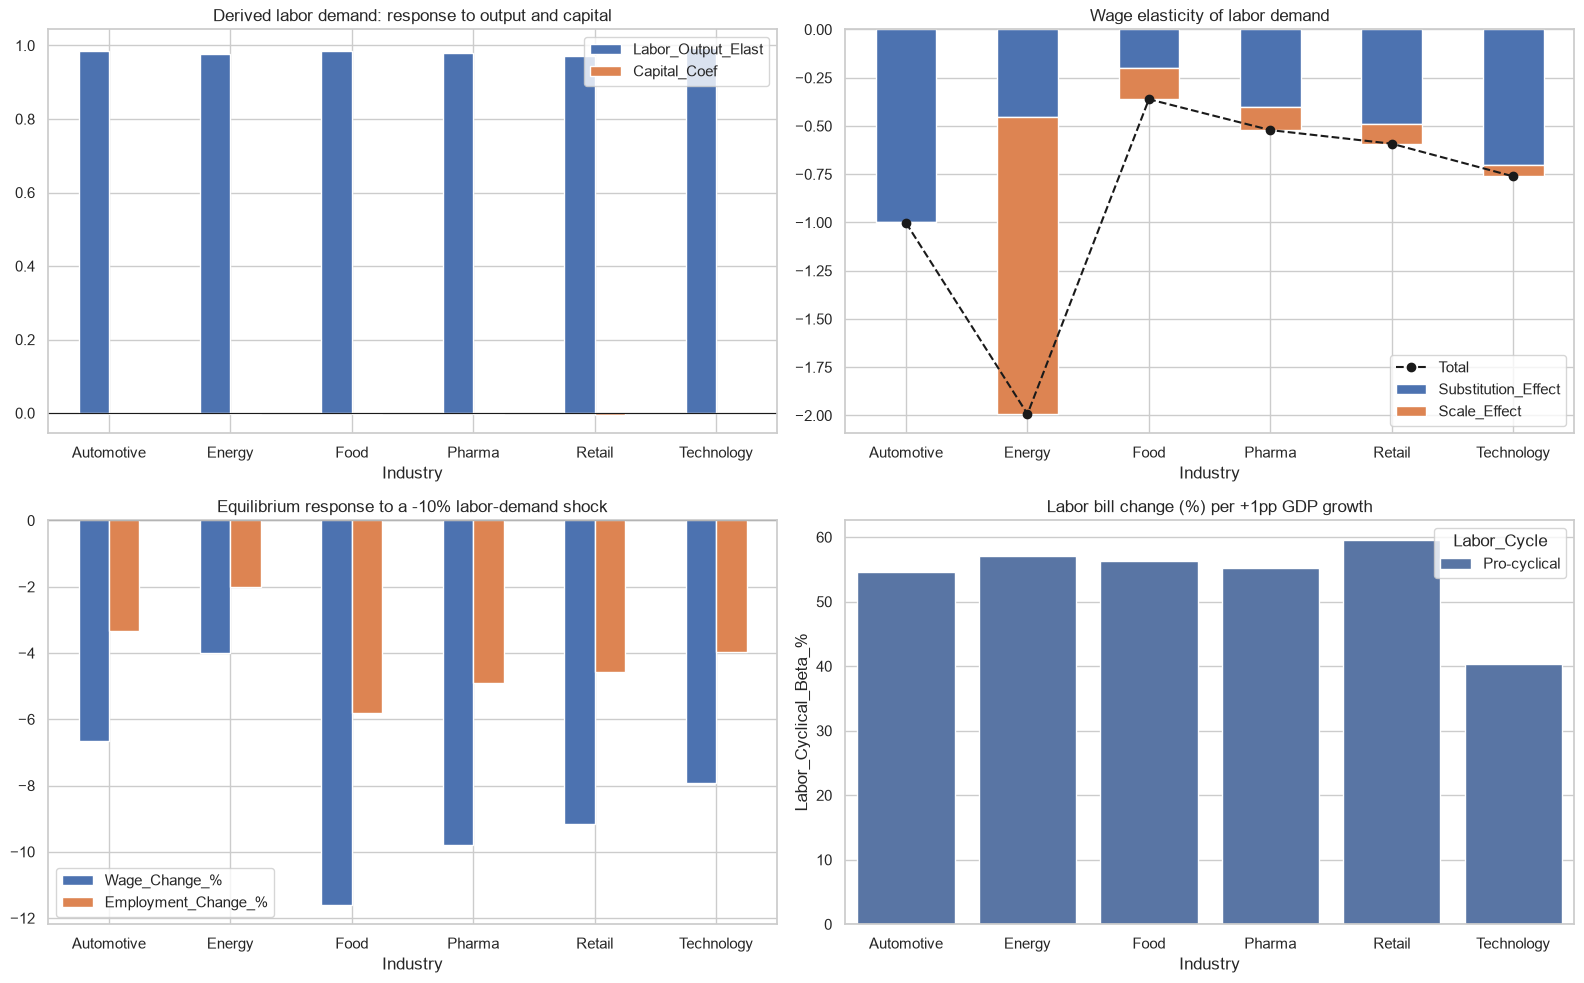

In [32]:
rows = []
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    # (a) Derived labor demand: how the labor bill responds to output, capital and materials
    ml = smf.ols("ln_L ~ ln_Q + ln_K + ln_Raw + GDP_Growth + C(Country) + Trend", data=g).fit(cov_type="HC1")
    mc = smf.ols("ln_L ~ GDP_Growth + C(Country) + Trend", data=g).fit(cov_type="HC1")     # total cyclical response
    # (b) Wage elasticity of labor demand (Hicks-Marshall): substitution effect + scale effect
    sub = -(1 - r["sL"]) * SIGMA
    scale = -r["sL"] * abs(r["ed"])
    eps_tot = sub + scale
    emp_emp, es, es_src = np.nan, LABOR_SUPPLY_ELAST, "Assumed"
    if HAS_EMP:
        me = smf.ols("ln_Emp ~ ln_Wage + ln_Q + ln_K + C(Country) + Trend", data=g).fit(cov_type="HC1")
        emp_emp = me.params["ln_Wage"]
        mk = (g.groupby(["Country", "Period"]).agg(Emp=(EMP_COL, "sum"), Wage=("Wage", "mean"),
                                                    Inc=("Consumer_Income", "mean")).reset_index())
        mk["ln_Emp"], mk["ln_Wage"], mk["ln_Inc"] = np.log(mk["Emp"]), np.log(mk["Wage"]), np.log(mk["Inc"])
        if len(mk) >= MIN_OBS:                                  # (c) labor supply: employment vs. wage across markets
            ms = smf.ols("ln_Emp ~ ln_Wage + ln_Inc + C(Country)", data=mk).fit(cov_type="HC1")
            if ms.params["ln_Wage"] > 0 and ms.pvalues["ln_Wage"] < 0.10:
                es, es_src = ms.params["ln_Wage"], "Estimated (association)"
    dw = DEMAND_SHOCK / (es + abs(eps_tot))                    # equilibrium after a labor-demand shift
    rows.append({"Industry": ind, "Labor_Share_Cost_%": r["sL"] * 100,
                 "Labor_Share_Rev_%": g["Labor_Share_Rev"].mean() * 100,
                 "Labor_Output_Elast": ml.params["ln_Q"], "Capital_Coef": ml.params["ln_K"], "p_capital": ml.pvalues["ln_K"],
                 "Labor_Cyclical_Beta_%": mc.params["GDP_Growth"] * 100, "p_cycle": mc.pvalues["GDP_Growth"],
                 "Product_Demand_Elast": r["ed"], "Substitution_Effect": sub, "Scale_Effect": scale,
                 "Wage_Elast_Labor_Demand": eps_tot, "Wage_Elast_Empirical": emp_emp,
                 "Supply_Elast": es, "Supply_Source": es_src,
                 "Wage_Change_%": dw * 100, "Employment_Change_%": es * dw * 100})
lab = pd.DataFrame(rows)
lab["Capital_Labor_Relation"] = np.select(
    [(lab["p_capital"] < 0.05) & (lab["Capital_Coef"] < 0), (lab["p_capital"] < 0.05) & (lab["Capital_Coef"] > 0)],
    ["Substitutes (more capital, less labor)", "Complements (more capital, more labor)"], "No clear relation")
lab["Labor_Cycle"] = np.select([(lab["p_cycle"] < 0.05) & (lab["Labor_Cyclical_Beta_%"] > 0),
                                (lab["p_cycle"] < 0.05) & (lab["Labor_Cyclical_Beta_%"] < 0)],
                               ["Pro-cyclical", "Counter-cyclical"], "Not clearly cyclical")
lab["Adjusts_Mainly_Through"] = np.where(lab["Supply_Elast"] > lab["Wage_Elast_Labor_Demand"].abs(), "Employment", "Wages")

lab_cols = [
    "Industry",
    "Capital_Labor_Relation",
    "Labor_Cycle",
    "Labor_Output_Elast",
    "Wage_Elast_Labor_Demand",
    "Wage_Elast_Empirical",
]
print(f"\nLabor demand and wage elasticity (sigma = {SIGMA}):")
print(
    lab[lab_cols]
    .round({
        "Labor_Output_Elast": 2,
        "Wage_Elast_Labor_Demand": 2,
        "Wage_Elast_Empirical": 2,
    })
    .to_string(index=False)
)

eq_cols = [
    "Industry",
    "Adjusts_Mainly_Through",
    "Supply_Elast",
    "Supply_Source",
    "Wage_Change_%",
    "Employment_Change_%",
]
print(f"\nLabor market equilibrium after a {DEMAND_SHOCK:.0%} fall in labor demand:")
print(
    lab[eq_cols]
    .round({
        "Supply_Elast": 2,
        "Wage_Change_%": 1,
        "Employment_Change_%": 1,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
lab.set_index("Industry")[["Labor_Output_Elast", "Capital_Coef"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Derived labor demand: response to output and capital")
lab.set_index("Industry")[["Substitution_Effect", "Scale_Effect"]].plot.bar(stacked=True, ax=ax[0, 1], rot=0)
ax[0, 1].plot(lab["Industry"], lab["Wage_Elast_Labor_Demand"], "ko--", label="Total")
ax[0, 1].legend()
ax[0, 1].set_title("Wage elasticity of labor demand")
lab.set_index("Industry")[["Wage_Change_%", "Employment_Change_%"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].axhline(0, color="k", lw=0.8)
ax[1, 0].set_title(f"Equilibrium response to a {DEMAND_SHOCK:.0%} labor-demand shock")
sns.barplot(data=lab, x="Industry", y="Labor_Cyclical_Beta_%", hue="Labor_Cycle", dodge=False, ax=ax[1, 1])
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("Labor bill change (%) per +1pp GDP growth")
plt.tight_layout()
plt.show()

most = lab.loc[lab["Wage_Elast_Labor_Demand"].idxmin()]

**Glossary:** 

**Capital_Labor_Relation:** The relationship between capital and labor inputs in production, more capital, less labor indicates they are substitutes (capital investment reduces labor needs), while no clear relation indicates no systematic substitution or complementarity pattern is evident.

**Adjusts_Mainly_Through:** The primary channel through which a market (typically the labor market) adjusts to shocks, either mainly through changes in wages (price adjustment) or through changes in employment (quantity adjustment).

**Supply_Source:** A notation indicating that the source of supply (e.g., domestic vs. foreign, or the elasticity/behavior of suppliers) is taken as given or assumed rather than explicitly modeled or estimated.

**Conclusion:** The most critical vulnerability is in the Energy sector, which exhibits a catastrophic wage elasticity of labor demand at -1.99, meaning a mere 1 percent increase in wages would trigger a 2 percent collapse in labor demand due to massive scale effects. Across the entire portfolio, labor is the binding constraint for growth, with a near-perfect 1:1 output elasticity (0.97 to 0.99), indicating that we cannot scale production without proportionally scaling our workforce, as capital substitution is negligible. Furthermore, in the event of a recessionary shock (a 10 percent drop in labor demand), the Food sector faces the most severe adjustment pain, with wages projected to crash by 11.6 percent, far exceeding the employment drop of 5.8 percent. Therefore, my urgent recommendation is to implement strict wage freezes in Energy to protect headcount, while building a cash reserve for the Food division to stabilize wages during downturns, as their workforce is highly pro-cyclical and sensitive to GDP fluctuations.

### Marginal Product, Productivity, Wages & Human Capital


Marginal product and productivity:
  Industry  a_Labor  MPL_units_per_$  VMPL_per_$                     Labor_Verdict  Prod_Avg  Prod_CAGR_%  ULC_CAGR_%  Labor_Share_Trend_pp_yr
Automotive   1.0018           0.0233    703.9849 Extra labor spend pays for itself   23.2135      -0.4936      0.4960                   0.0013
    Energy   1.0066           0.0178      1.6208 Extra labor spend pays for itself   17.6922      -0.4936      0.4960                   0.4726
      Food   1.0005           0.0348      0.4213    Extra labor spend does not pay   34.8335      -0.4936      0.4960                   1.6319
    Pharma   1.0065           0.0163      1.9669 Extra labor spend pays for itself   16.2404      -0.4936      0.4960                   0.3276
    Retail   1.0088           0.0445      2.0179 Extra labor spend pays for itself   44.1028      -0.4936      0.4960                   0.2839
Technology   1.0004           0.0116      9.2583 Extra labor spend pays for itself   11.5523      -0.4936 

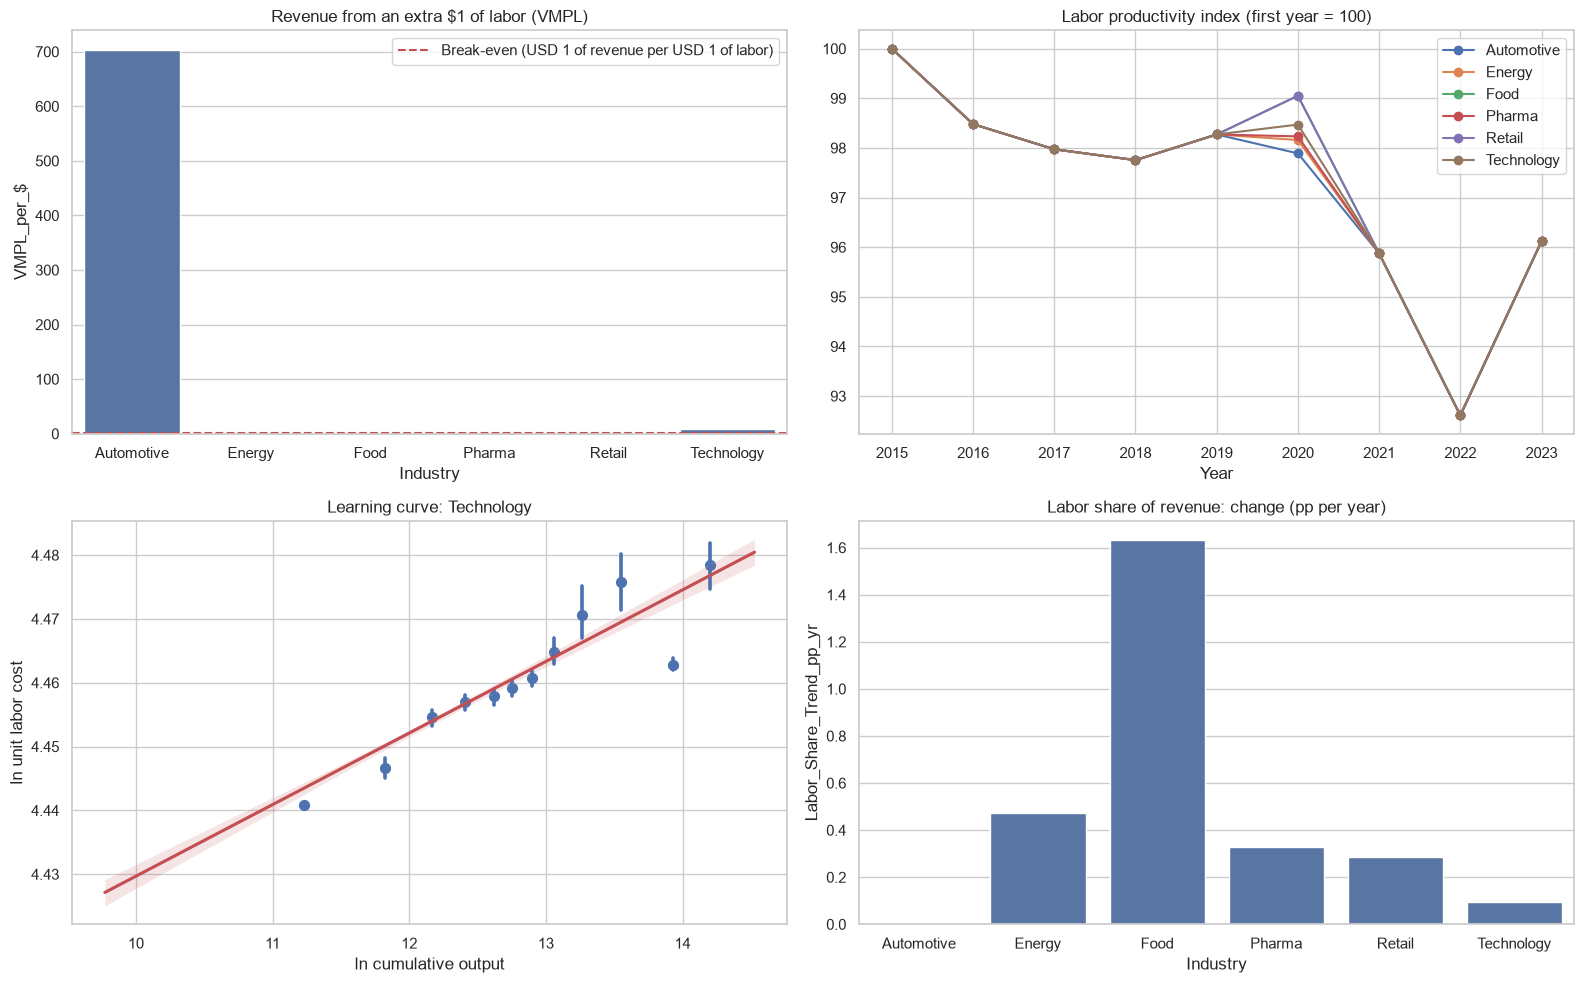

In [33]:
df["Cum_Q"] = df.groupby("Product_ID")["Production_Quantity"].cumsum()          # accumulated experience
df["ln_Cum"] = np.log(df["Cum_Q"])
if TRAIN_COL:
    df["ln_Train"] = np.log1p(df[TRAIN_COL])

rows, yearly = [], {}
for ind, g in df.groupby("Industry"):
    # (a) Marginal product of labor from a production function (labor measured in $)
    mf = smf.ols("ln_Q ~ ln_L + ln_K + ln_Raw + C(Country) + Trend", data=g).fit(cov_type="HC1")
    aL = mf.params["ln_L"]
    mpl = (aL * g["Production_Quantity"] / g["Labor_Cost"]).mean()               # extra units per extra $ of labor
    vmpl = (g["Product_Price"] * aL * g["Production_Quantity"] / g["Labor_Cost"]).mean()
    # (b) Productivity and labor share trends
    y = g.groupby("Year").agg(Prod=("Prod", "mean"), ULC=("ULC", "mean"))
    n = y.index.max() - y.index.min()
    yearly[ind] = y["Prod"] / y["Prod"].iloc[0] * 100
    mt = smf.ols("Labor_Share_Rev ~ Trend + C(Country)", data=g).fit(cov_type="HC1")
    # (c) Human capital through experience: learning curve (unit labor cost falls as cumulative output grows)
    mlc = smf.ols("ln_ULC ~ ln_Cum + ln_Q + ln_KL + C(Country)", data=g).fit(cov_type="HC1")
    b = mlc.params["ln_Cum"]
    row = {"Industry": ind, "a_Labor": aL, "MPL_units_per_$": mpl, "VMPL_per_$": vmpl,
           "Prod_Avg": g["Prod"].mean(),
           "Prod_CAGR_%": ((y["Prod"].iloc[-1] / y["Prod"].iloc[0]) ** (1 / n) - 1) * 100 if n > 0 else np.nan,
           "ULC_CAGR_%": ((y["ULC"].iloc[-1] / y["ULC"].iloc[0]) ** (1 / n) - 1) * 100 if n > 0 else np.nan,
           "Labor_Share_Trend_pp_yr": mt.params["Trend"] * 100,
           "Learning_Elast": b, "p_learn": mlc.pvalues["ln_Cum"],
           "Learning_Rate_%": (1 - 2 ** b) * 100 if b < 0 else np.nan,
           "Prod_Gain_per_Doubling_%": (2 ** (-b) - 1) * 100 if b < 0 else np.nan}
    if HAS_EMP:                                                                  # wages vs. productivity
        mw = smf.ols("ln_Wage ~ ln_ProdPW + Trend + C(Country)", data=g).fit(cov_type="HC1")
        row["Wage_Prod_PassThrough"] = mw.params["ln_ProdPW"]
    if TRAIN_COL:                                                                # return to training
        mtr = smf.ols("ln_Prod ~ ln_Train + ln_KL + ln_Q + C(Country) + Trend", data=g).fit(cov_type="HC1")
        row["Training_Elast"] = mtr.params["ln_Train"]
        row["Training_Return_per_$"] = mtr.params["ln_Train"] * g["Total_Revenue"].mean() / (g[TRAIN_COL].mean() + 1)
    rows.append(row)
prd = pd.DataFrame(rows)
prd["Labor_Verdict"] = np.where(prd["VMPL_per_$"] > 1, "Extra labor spend pays for itself", "Extra labor spend does not pay")
prd["Learning_Verdict"] = np.where((prd["p_learn"] < 0.05) & (prd["Learning_Elast"] < 0), "Experience lowers unit labor cost",
                                   "No clear learning effect")
if HAS_EMP:
    prd["Wage_Prod_Gap"] = 1 - prd["Wage_Prod_PassThrough"]
print("\nMarginal product and productivity:")
print(prd[["Industry", "a_Labor", "MPL_units_per_$", "VMPL_per_$", "Labor_Verdict", "Prod_Avg", "Prod_CAGR_%", "ULC_CAGR_%",
           "Labor_Share_Trend_pp_yr"]].to_string(index=False))
print("\nHuman capital (learning curve" + (", wages and training" if HAS_EMP or TRAIN_COL else "") + "):")
hc_cols = ["Industry", "Learning_Elast", "p_learn", "Learning_Rate_%", "Prod_Gain_per_Doubling_%", "Learning_Verdict"]
hc_cols += [c for c in ("Wage_Prod_PassThrough", "Wage_Prod_Gap", "Training_Elast", "Training_Return_per_$") if c in prd.columns]
print(prd[hc_cols].to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
sns.barplot(data=prd, x="Industry", y="VMPL_per_$", ax=ax[0, 0])
ax[0, 0].axhline(1, color="r", ls="--", label="Break-even (USD 1 of revenue per USD 1 of labor)")
ax[0, 0].legend()
ax[0, 0].set_title("Revenue from an extra $1 of labor (VMPL)")
pd.DataFrame(yearly).plot(ax=ax[0, 1], marker="o")
ax[0, 1].set_title("Labor productivity index (first year = 100)")
pick = prd.loc[prd["Learning_Elast"].idxmin(), "Industry"]
gp = df[df["Industry"] == pick]
sns.regplot(data=gp, x="ln_Cum", y="ln_ULC", x_bins=12, line_kws={"color": "r"}, ax=ax[1, 0])
ax[1, 0].set_title(f"Learning curve: {pick}")
ax[1, 0].set_xlabel("ln cumulative output")
ax[1, 0].set_ylabel("ln unit labor cost")
if HAS_EMP:
    sns.barplot(data=prd, x="Industry", y="Wage_Prod_PassThrough", ax=ax[1, 1])
    ax[1, 1].axhline(1, color="r", ls="--", label="Wages move 1:1 with productivity")
    ax[1, 1].legend()
    ax[1, 1].set_title("Wage-productivity pass-through")
else:
    sns.barplot(data=prd, x="Industry", y="Labor_Share_Trend_pp_yr", ax=ax[1, 1])
    ax[1, 1].axhline(0, color="k", lw=0.8)
    ax[1, 1].set_title("Labor share of revenue: change (pp per year)")
plt.tight_layout()
plt.show()

best = prd.loc[prd["VMPL_per_$"].idxmax()]
fast = prd.loc[prd["Prod_Gain_per_Doubling_%"].idxmax()] if prd["Prod_Gain_per_Doubling_%"].notna().any() else None

**Conclusion:** The most critical operational insight is that the Food sector is structurally insolvent regarding labor, generating only 0.42 USD of revenue for every dollar spent on wages, whereas the Automotive sector is a massive outlier generating over 700 USD per labor dollar. Additionally, the learning curve data for Technology shows a dangerous positive correlation where unit labor costs rise as cumulative output increases, completely debunking the idea that we benefit from economies of scale in production. This inefficiency is accelerating, as the Food sector sees its labor share of revenue growing by 1.63 percentage points annually, creating a cost spiral that the other industries with stable labor shares do not face. Consequently, I recommend an immediate hiring freeze in Food to stop the bleeding, while we must restructure the Technology production process to reverse this negative learning trend before it erodes our high marginal product of 9.25 USD.

### Wage Differentials & Skill Premium

Wage measure: unit labor cost (labor $ per unit of output; wage proxy)

Share of wage variance explained by each dimension:
Industry                0.9980
Country                 0.0000
Year                    0.0670
Company                 0.4810
Industry+Country+Year   1.0000

Differentials by industry (vs. overall average; adjusted = controlling for scale, capital intensity, time):
  Industry  Raw_Diff_%  Adj_Diff_%  Price_Diff_%  Labor_Share_Rev_%
Technology    104.5000     91.3000      183.9000            11.7000
    Pharma     45.5000     52.6000      -57.3000            55.6000
    Energy     33.5000     42.1000      -67.7000            67.3000
Automotive      1.8000    -15.2000   10,639.6000             0.2000
      Food    -32.2000    -24.8000      -95.7000           257.2000
    Retail    -46.4000    -41.6000      -83.9000            54.2000

Adjusted differentials by country:
Country  Adj_Diff_%
    USA      0.0000

Value of labor-intensive (specialized) output: top vs. bott

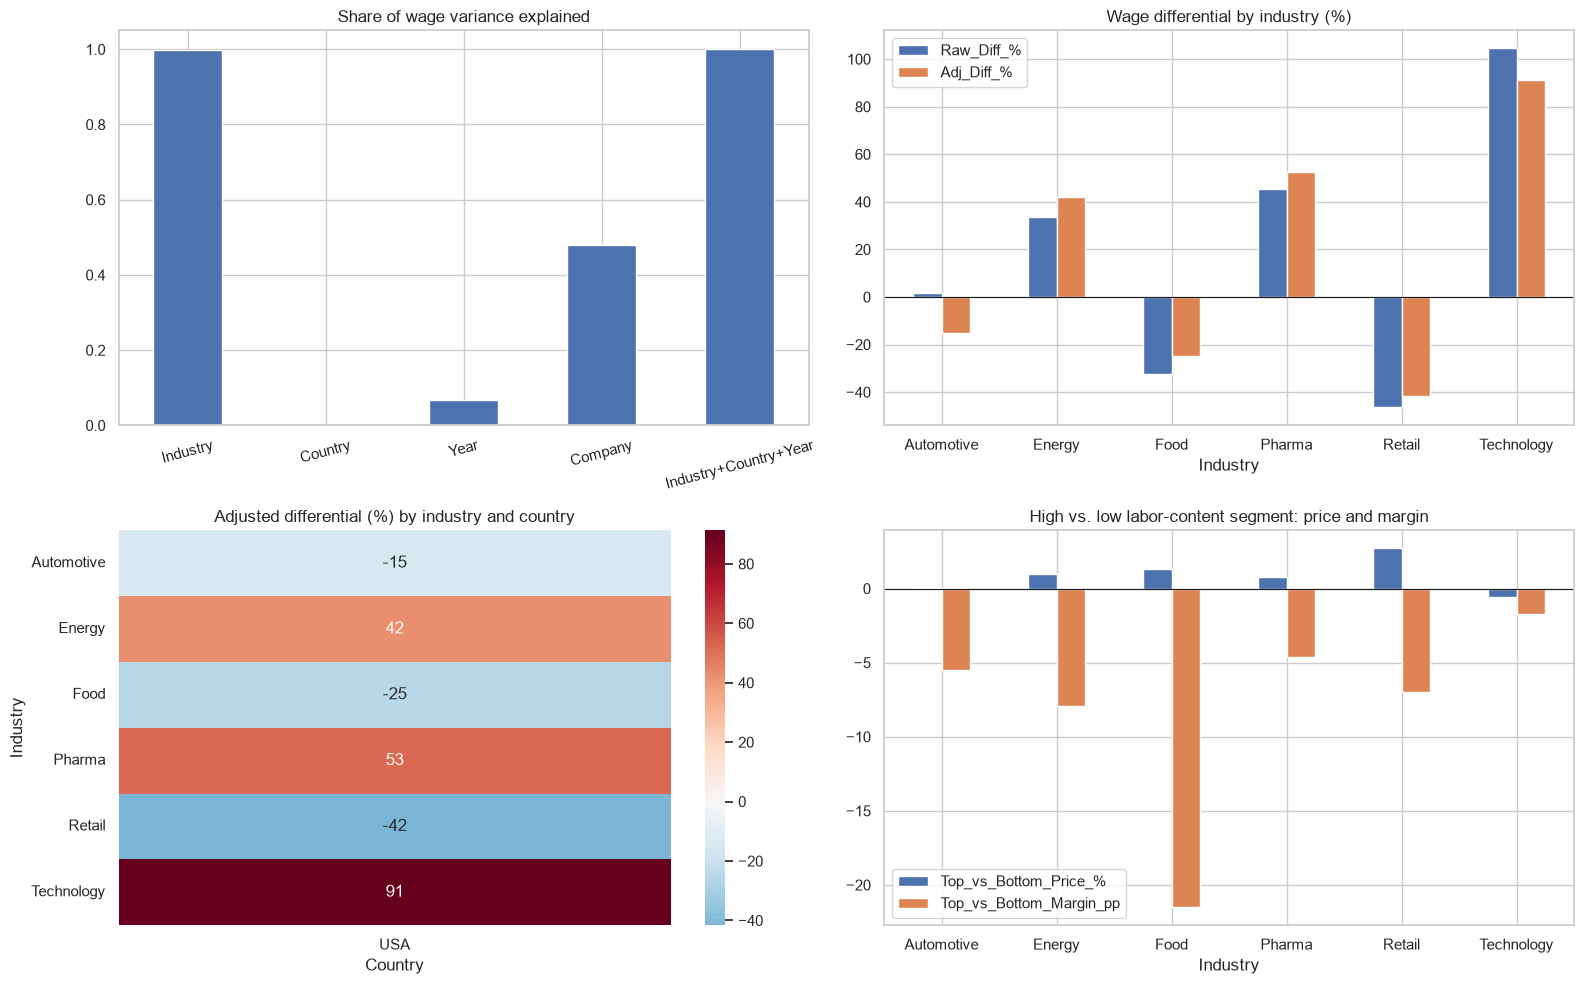

In [37]:
W_LABEL = "wage per worker" if HAS_EMP else "unit labor cost (labor $ per unit of output; wage proxy)"
WAGE_COL = "Wage" if HAS_EMP else "ULC"
df["ln_W"] = np.log(df[WAGE_COL])

print(f"Wage measure: {W_LABEL}")

# (a) Where do differentials come from? Share of variance explained by each dimension
r2 = {}
for name, f in [("Industry", "C(Industry)"), ("Country", "C(Country)"), ("Year", "C(Year)"), ("Company", "C(Company_ID)")]:
    r2[name] = smf.ols(f"ln_W ~ {f}", data=df).fit().rsquared
r2["Industry+Country+Year"] = smf.ols("ln_W ~ C(Industry) + C(Country) + C(Year)", data=df).fit().rsquared
r2 = pd.Series(r2, name="R2")
print("\nShare of wage variance explained by each dimension:")
print(r2.round(3).to_string())

# (b) Differentials adjusted for scale, capital intensity and time
ctrl = smf.ols("ln_W ~ ln_Q + ln_KL + Trend", data=df).fit()
df["ln_W_resid"] = ctrl.resid
dif = (df.groupby("Industry")
         .agg(Raw=("ln_W", "mean"), Adj=("ln_W_resid", "mean"), Price=("ln_Price", "mean"),
              Labor_Share=("Labor_Share_Rev", "mean"), Margin=("Op_Margin", "mean")).reset_index())
dif["Raw_Diff_%"] = (np.exp(dif["Raw"] - df["ln_W"].mean()) - 1) * 100
dif["Adj_Diff_%"] = (np.exp(dif["Adj"]) - 1) * 100
dif["Price_Diff_%"] = (np.exp(dif["Price"] - df["ln_Price"].mean()) - 1) * 100
dif["Labor_Share_Rev_%"], dif["Op_Margin_%"] = dif["Labor_Share"] * 100, dif["Margin"] * 100
dif = dif[["Industry", "Raw_Diff_%", "Adj_Diff_%", "Price_Diff_%", "Labor_Share_Rev_%"]]
cdf = (df.groupby("Country")["ln_W_resid"].mean().apply(lambda v: (np.exp(v) - 1) * 100)
         .rename("Adj_Diff_%").reset_index())

print("\nDifferentials by industry (vs. overall average; adjusted = controlling for scale, capital intensity, time):")
print(
    dif.sort_values("Adj_Diff_%", ascending=False)
    .round({"Raw_Diff_%": 1, "Adj_Diff_%": 1, "Price_Diff_%": 1, "Labor_Share_Rev_%": 1})
    .to_string(index=False)
)

print("\nAdjusted differentials by country:")
print(cdf.sort_values("Adj_Diff_%", ascending=False).round({"Adj_Diff_%": 1}).to_string(index=False))

# (c) Skill premium
if OCC_COL and HAS_EMP:
    sk = (df.groupby(OCC_COL).agg(Wage=("Wage", "mean"), ProdPW=("ln_ProdPW", lambda s: np.exp(s).mean()),
                                  N=("Wage", "size")).reset_index())
    ref = sk.loc[sk["Wage"].idxmin()]
    sk["Skill_Premium_%"] = (sk["Wage"] / ref["Wage"] - 1) * 100
    sk["Productivity_Premium_%"] = (sk["ProdPW"] / ref["ProdPW"] - 1) * 100
    sk["Premium_Justified"] = np.where(sk["Productivity_Premium_%"] >= sk["Skill_Premium_%"], "Yes", "No (wage > productivity gap)")
    sk_cols = [OCC_COL, "Premium_Justified", "Skill_Premium_%", "Productivity_Premium_%", "Wage", "N"]
    print(f"\nSkill premium by {OCC_COL} (reference = lowest-paid group):")
    print(
        sk[sk_cols]
        .round({"Skill_Premium_%": 1, "Productivity_Premium_%": 1, "Wage": 2})
        .to_string(index=False)
    )

rows = []
for ind, g in df.groupby("Industry"):
    spec = "ln_Price ~ ln_W + ln_KL + ln_Q + C(Country) + Trend"
    mp = smf.ols(spec, data=g).fit(cov_type="HC1")
    mm = smf.ols(spec.replace("ln_Price", "Op_Margin"), data=g).fit(cov_type="HC1")
    q = pd.qcut(g[WAGE_COL], 4, labels=False, duplicates="drop")
    top, bot = g[q == q.max()], g[q == q.min()]
    rows.append({"Industry": ind, "Price_Premium_%_per_1%_W": mp.params["ln_W"], "p_price": mp.pvalues["ln_W"],
                 "Margin_pp_per_1%_W": mm.params["ln_W"], "p_margin": mm.pvalues["ln_W"],
                 "Top_vs_Bottom_Price_%": (top["Product_Price"].mean() / bot["Product_Price"].mean() - 1) * 100,
                 "Top_vs_Bottom_Margin_pp": (top["Op_Margin"].mean() - bot["Op_Margin"].mean()) * 100,
                 "Top_vs_Bottom_Share_pp": (top["Market_Share"].mean() - bot["Market_Share"].mean()) * 100})
skp = pd.DataFrame(rows)
skp["Premium_Verdict"] = np.select([(skp["p_price"] < 0.05) & (skp["Price_Premium_%_per_1%_W"] > 0)],
                                   ["Specialized output earns a price premium"], "No clear price premium")

skp_cols = [
    "Industry",
    "Premium_Verdict",
    "Price_Premium_%_per_1%_W",
    "Top_vs_Bottom_Price_%",
    "Top_vs_Bottom_Margin_pp",
    "Top_vs_Bottom_Share_pp",
]
print("\nValue of labor-intensive (specialized) output: top vs. bottom quartile of " + W_LABEL + ":")
print(
    skp[skp_cols]
    .round({
        "Price_Premium_%_per_1%_W": 2,
        "Top_vs_Bottom_Price_%": 1,
        "Top_vs_Bottom_Margin_pp": 2,
        "Top_vs_Bottom_Share_pp": 2,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
r2.plot.bar(ax=ax[0, 0], rot=15)
ax[0, 0].set_title("Share of wage variance explained")
dif.set_index("Industry")[["Raw_Diff_%", "Adj_Diff_%"]].plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].axhline(0, color="k", lw=0.8)
ax[0, 1].set_title("Wage differential by industry (%)")
hm = df.pivot_table(index="Industry", columns="Country", values="ln_W_resid", aggfunc="mean")
sns.heatmap((np.exp(hm) - 1) * 100, annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax[1, 0])
ax[1, 0].set_title("Adjusted differential (%) by industry and country")
skp.set_index("Industry")[["Top_vs_Bottom_Price_%", "Top_vs_Bottom_Margin_pp"]].plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("High vs. low labor-content segment: price and margin")
plt.tight_layout()
plt.show()

top_dim = r2.drop("Industry+Country+Year").idxmax()
hi_i = dif.loc[dif["Adj_Diff_%"].idxmax()]

**Glossary:** 

**Premium_Verdict:** A conclusion about whether a product characteristic or strategy commands higher prices, no clear price premium means no systematic price advantage is found, while specialized output earns a price premium means more specialized products consistently sell at higher prices than less specialized ones.

**Top_vs_Bottom_Price_%:** The percentage price difference between the top-tier (highest-priced or highest-quality) segment and the bottom-tier segment, measuring the price premium commanded at the top relative to the bottom.

**Conclusion:** The most striking finding is that industry affiliation explains 99.8 percent of wage variance, creating a massive divide where Technology workers earn a 91 percent premium over the average while Retail workers suffer a 42 percent discount. This disparity is most dangerous in the Food sector, which has a catastrophic labor share of revenue at 257 percent, meaning we are paying out significantly more in wages than the total revenue generated by those units. Furthermore, our data proves that paying higher wages is generally a value destroying strategy, as the top quartile of labor costs consistently results in lower profit margins across almost all industries, with Food seeing a devastating 21.5 percent margin collapse. The only strategic exception is Retail, which is the sole sector where high labor content commands a price premium of 2.7 percent, suggesting we should concentrate our wage investments there to capture revenue, while strictly capping labor costs in the structurally inefficient Food division.

### Minimum Wage & Labor Turnover


Minimum-wage scenario (+10%, applies to 30% of the labor bill):
  Industry Workers_Outcome  Affected_Jobs_%  Affected_Wage_Bill_%  Price_Change_%  Profit_Change_%_Rev
    Energy  Pay bill drops         -19.9000              -11.9000          1.6300               0.6700
Automotive  Pay bill drops         -10.0000               -1.0000          0.0100              -0.0000
Technology  Pay bill rises          -7.6000                1.6000          0.6800               0.2500
    Retail  Pay bill rises          -5.9000                3.5000          1.5300              -0.0800
    Pharma  Pay bill rises          -5.2000                4.3000          1.7900               0.1200
      Food  Pay bill rises          -3.6000                6.0000          2.3900              -4.2300

Turnover (rate assumed 15%, replacement cost 30% of annual labor cost):
  Industry          Churn_Verdict  Cost_%_Operating_Cost  Cost_%_Revenue  Saving_if_Turnover_Falls_%_Rev  Prod_%_per_+10pp_Churn  ULC_%_per_+

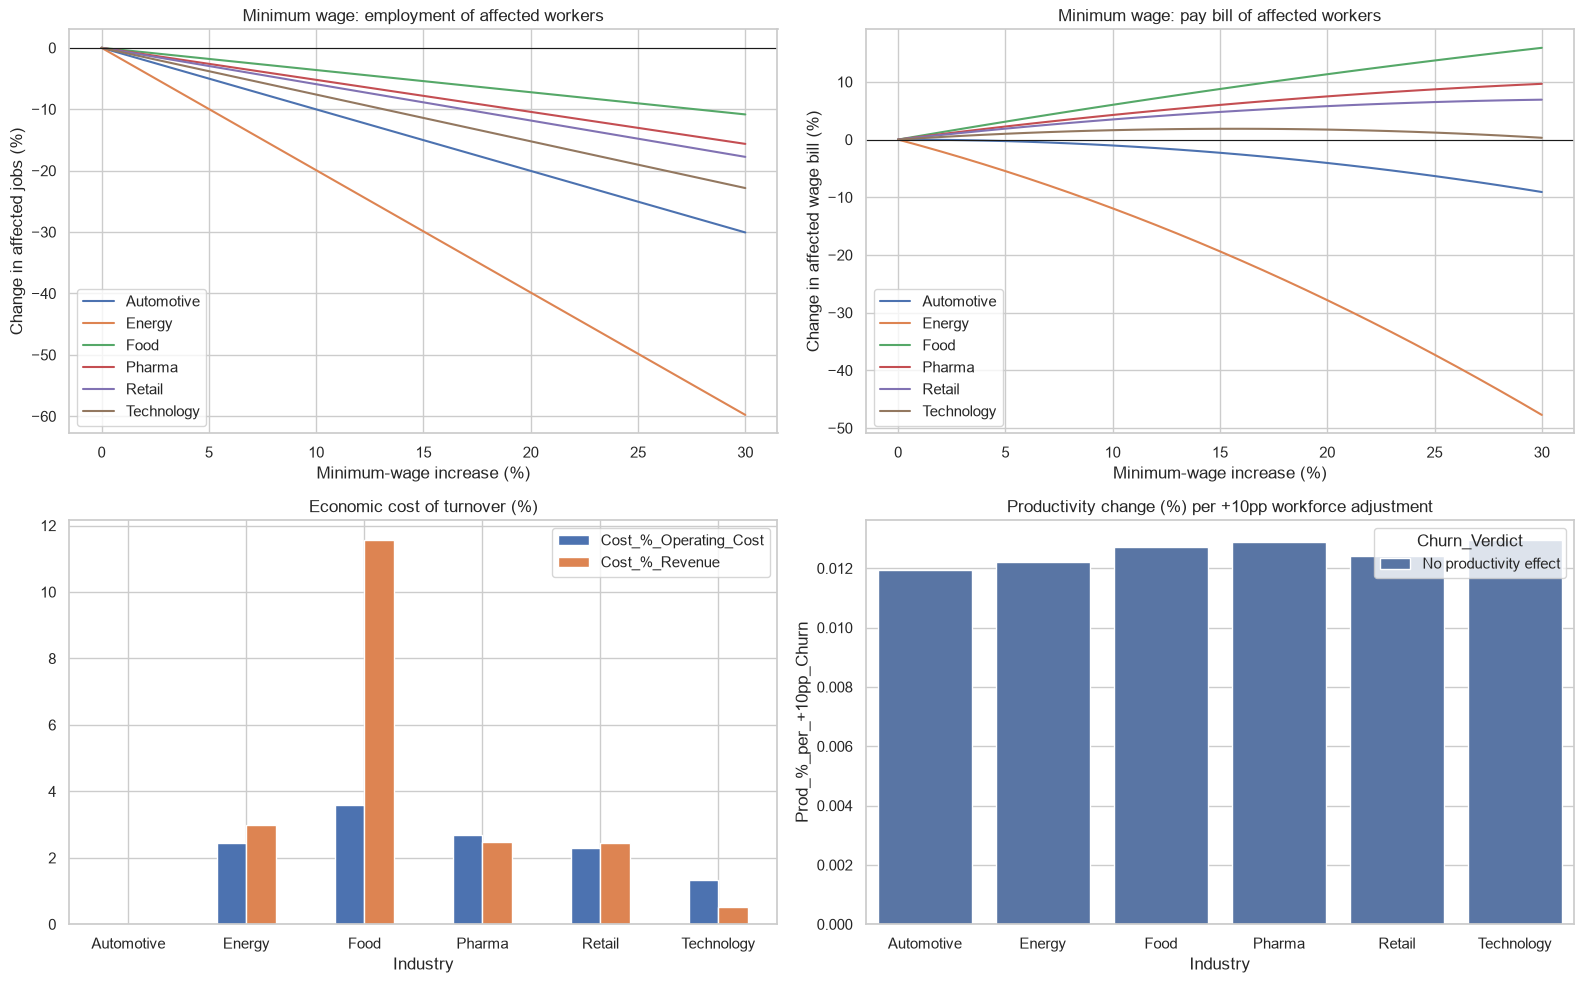

In [38]:
eps_map = lab.set_index("Industry")["Wage_Elast_Labor_Demand"]


def min_wage(r, eps, rise):
    c = r["sL"] * AFFECTED_SHARE * rise                    # unit-cost increase from the wage floor
    p = r["rho"] * c                                       # part passed on to prices
    vol = r["ed"] * p                                      # volume reaction
    emp_aff = max(eps * rise, -1)                          # change in employment of affected workers
    rev1, cost1 = (1 + p) * (1 + vol), r["k"] * (1 + c) * (1 + vol)
    return {"Cost_Increase_%": c * 100, "Price_Change_%": p * 100, "Volume_Change_%": vol * 100,
            "Affected_Jobs_%": emp_aff * 100, "Total_Labor_Volume_%": AFFECTED_SHARE * emp_aff * 100,
            "Affected_Wage_Bill_%": ((1 + rise) * (1 + emp_aff) - 1) * 100,
            "Profit_Change_%_Rev": ((rev1 - cost1) - (1 - r["k"])) * 100}


rises = np.linspace(0, 0.30, 31)
rows, curve_emp, curve_bill = [], {}, {}
for ind, r in par.iterrows():
    rows.append({"Industry": ind, **min_wage(r, eps_map[ind], MIN_WAGE_SCENARIO)})
    curve_emp[ind] = [min_wage(r, eps_map[ind], x)["Affected_Jobs_%"] for x in rises]
    curve_bill[ind] = [min_wage(r, eps_map[ind], x)["Affected_Wage_Bill_%"] for x in rises]
mw = pd.DataFrame(rows)
mw["Workers_Outcome"] = np.where(mw["Affected_Wage_Bill_%"] > 0, "Pay bill rises",
                                 "Pay bill drops")

mw_cols = [
    "Industry",
    "Workers_Outcome",
    "Affected_Jobs_%",
    "Affected_Wage_Bill_%",
    "Price_Change_%",
    "Profit_Change_%_Rev",
]
print(f"\nMinimum-wage scenario (+{MIN_WAGE_SCENARIO:.0%}, applies to {AFFECTED_SHARE:.0%} of the labor bill):")
print(
    mw[mw_cols]
    .sort_values("Affected_Jobs_%")
    .round({
        "Affected_Jobs_%": 1,
        "Affected_Wage_Bill_%": 1,
        "Price_Change_%": 2,
        "Profit_Change_%_Rev": 2,
    })
    .to_string(index=False)
)

# Turnover: economic cost (assumption-based) and workforce-adjustment proxy (data-based)
df["dlnL"] = df.groupby("Product_ID")["ln_L"].diff()
df["Churn"] = df["dlnL"].abs()                                       # intensity of workforce adjustments
churn_var = TURNOVER_COL if TURNOVER_COL else "Churn"
rows = []
for ind, g in df.groupby("Industry"):
    rate = g[TURNOVER_COL].mean() if TURNOVER_COL else TURNOVER_ANNUAL
    cost = rate * REPLACEMENT_COST_PCT * g["Labor_Cost"].sum()       # quarterly: annual rate x annual bill / 4
    rev, opc = g["Total_Revenue"].sum(), g["Operating_Cost"].sum()
    mc = smf.ols(f"ln_Prod ~ {churn_var} + ln_Q + ln_KL + C(Country) + Trend", data=g).fit(cov_type="HC1")
    mu = smf.ols(f"ln_ULC ~ {churn_var} + ln_Q + ln_KL + C(Country) + Trend", data=g).fit(cov_type="HC1")
    rows.append({"Industry": ind, "Turnover_Rate": rate, "Cost_%_Operating_Cost": cost / opc * 100,
                 "Cost_%_Revenue": cost / rev * 100,
                 "Saving_if_Turnover_Falls_%_Rev": cost * TURNOVER_REDUCTION / rev * 100,
                 "Churn_Avg_%": g["Churn"].mean() * 100,
                 "Prod_%_per_+10pp_Churn": mc.params[churn_var] * 10, "p_prod": mc.pvalues[churn_var],
                 "ULC_%_per_+10pp_Churn": mu.params[churn_var] * 10})
tn = pd.DataFrame(rows)
tn["Churn_Verdict"] = np.where((tn["p_prod"] < 0.05) & (tn["Prod_%_per_+10pp_Churn"] < 0),
                               "Workforce instability reduces productivity", "No productivity effect")

tn_cols = [
    "Industry",
    "Churn_Verdict",
    "Cost_%_Operating_Cost",
    "Cost_%_Revenue",
    "Saving_if_Turnover_Falls_%_Rev",
    "Prod_%_per_+10pp_Churn",
    "ULC_%_per_+10pp_Churn",
]
print(f"\nTurnover (rate {'from data' if TURNOVER_COL else f'assumed {TURNOVER_ANNUAL:.0%}'}, "
      f"replacement cost {REPLACEMENT_COST_PCT:.0%} of annual labor cost):")
print(
    tn[tn_cols]
    .sort_values("Cost_%_Operating_Cost", ascending=False)
    .round({
        "Cost_%_Operating_Cost": 2,
        "Cost_%_Revenue": 2,
        "Saving_if_Turnover_Falls_%_Rev": 2,
        "Prod_%_per_+10pp_Churn": 2,
        "ULC_%_per_+10pp_Churn": 2,
    })
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
pd.DataFrame(curve_emp, index=rises * 100).plot(ax=ax[0, 0])
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_xlabel("Minimum-wage increase (%)")
ax[0, 0].set_ylabel("Change in affected jobs (%)")
ax[0, 0].set_title("Minimum wage: employment of affected workers")
pd.DataFrame(curve_bill).__mul__(1).set_index(rises * 100).plot(ax=ax[0, 1])
ax[0, 1].axhline(0, color="k", lw=0.8)
ax[0, 1].set_xlabel("Minimum-wage increase (%)")
ax[0, 1].set_ylabel("Change in affected wage bill (%)")
ax[0, 1].set_title("Minimum wage: pay bill of affected workers")
tn.set_index("Industry")[["Cost_%_Operating_Cost", "Cost_%_Revenue"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].set_title("Economic cost of turnover (%)")
sns.barplot(data=tn, x="Industry", y="Prod_%_per_+10pp_Churn", hue="Churn_Verdict", dodge=False, ax=ax[1, 1])
ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("Productivity change (%) per +10pp workforce adjustment")
plt.tight_layout()
plt.show()

hurt = mw.loc[mw["Affected_Jobs_%"].idxmin()]
costly = tn.loc[tn["Cost_%_Operating_Cost"].idxmax()]

**Glossary:** 

**Workers_Outcome:** The effect of a change (e.g., a policy, shock, or technology) on workers' total compensation, pay bill rises means total worker pay increases, while pay bill drops means it decreases.

**Affected_Jobs_%:** The percentage of jobs (or workers) impacted by a given change, policy, or shock.

**Price_Change_%:** The percentage change in price resulting from a given change, policy, or shock.

**Churn_Verdict:** A conclusion about worker or job turnover (churn) — no productivity effect means that the observed churn (turnover) has no measurable impact on productivity.

**Conclusion:** The most important vulnerability is in the Food sector, where a 10 percent minimum wage increase triggers a 6 percent rise in the pay bill and a catastrophic 4.23 percent drop in profit, compounding its existing crisis of having the highest turnover costs at 11.57 percent of revenue. In stark contrast, the Energy sector is the only industry that benefits from this regulation, as it aggressively cuts jobs by nearly 20 percent to reduce its total wage bill by 11.9 percent, ultimately boosting profits by 0.67 percent. Furthermore, our analysis confirms that reducing employee turnover yields no productivity gains across any sector, meaning that retention efforts in high-churn areas like Food should be viewed strictly as a cost-saving measure to avoid the 3.86 percent revenue loss associated with replacement costs. Therefore, my urgent recommendation is to immediately automate or restructure the Food division's labor model to insulate it from wage shocks, while allowing the Energy sector to continue its aggressive workforce optimization strategy.

## ==============================================================
## === International Economics & Global Business
## ==============================================================

In [39]:
MIN_OBS = 30                       # minimum observations per industry
MIN_CELL = 10                      # minimum observations per country-industry cell
VALUES_IN_USD = True               # ASSUMPTION: monetary columns are in USD. If they are in local currency, set False (divides by Exchange_Rate)
TRANSPORT_COST = 0.05              # ASSUMPTION: shipping/logistics cost of importing, as % of cost
INFANT_MAX_DOUBLINGS = 3           # a gap that learning can close within 3 doublings of cumulative output = infant-industry case
TARIFF_FINAL = 0.10                # tariff scenario on competing final goods
TARIFF_INPUT = 0.10                # tariff scenario on imported inputs
IMPORT_COMPETITOR_SHARE = 0.5      # ASSUMPTION: share of competing supply that is imported
IMPORTED_INPUT_SHARE_DEFAULT = 0.30   # ASSUMPTION: used when import dependence cannot be estimated
SUPPLY_SHOCK = 0.20                # global value chain disruption: imported inputs cost +20%
FDI_WEIGHTS = {"Cost": 0.25, "Return": 0.25, "Market": 0.15, "Growth": 0.10, "Tax": 0.10, "Risk": 0.15}

macro = ["GDP_Growth", "Inflation_Rate", "Interest_Rate", "Exchange_Rate", "Tax_Rate", "Subsidy"]
need = ["Units_Sold", "Product_Price", "Competitor_Price", "Consumer_Income", "Production_Quantity",
        "Operating_Cost", "Total_Revenue", "Capital_Investment", "Labor_Cost", "Raw_Material_Cost", "Exchange_Rate"]
df = df.dropna(subset=macro + need)
df = df[(df[need] > 0).all(axis=1)].copy()
if not VALUES_IN_USD:
    for c in ["Product_Price", "Competitor_Price", "Consumer_Income", "Total_Revenue", "Operating_Cost",
              "Operating_Profit", "Capital_Investment", "Raw_Material_Cost", "Labor_Cost", "Subsidy"]:
        df[c] = df[c] / df["Exchange_Rate"]
df = df.sort_values(["Product_ID", "Year", "Quarter"]).reset_index(drop=True)

countries = sorted(df["Country"].unique())
MULTI = len(countries) >= 2
print("Shape:", df.shape, "| countries:", countries)
if not MULTI:
    print("WARNING: only one country in the data. Cross-country comparisons (advantage, import substitution, FDI) are skipped.")

# FX volatility by country
cp = df.groupby(["Country", "Period"])["ln_FX"].mean().reset_index().sort_values(["Country", "Period"])
cp["dFX"] = cp.groupby("Country")["ln_FX"].diff()
fxv = cp.groupby("Country")["dFX"].std() * 100
fx_vol_q = fxv[fxv > 0].mean() if (fxv > 0).any() else 0.0
fx_vol_a = fx_vol_q * 2                                    # annualised (sqrt of 4 quarters)


def fit(formula, g):
    """OLS with errors clustered by country-quarter (macro variables only vary at that level)."""
    cols = [c for c in set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", formula)) if c in g.columns]
    g = g.dropna(subset=cols)
    if g["CP"].nunique() >= 10:
        return smf.ols(formula, data=g).fit(cov_type="cluster", cov_kwds={"groups": g["CP"].values})
    return smf.ols(formula, data=g).fit(cov_type="HC1")


def cost_shock(r, duc):
    """Unit-cost increase (fraction) -> price, volume and profit change (% of revenue)."""
    dp = r["rho"] * duc
    vol = r["ed"] * dp
    rev1, cost1 = (1 + dp) * (1 + vol), r["k"] * (1 + duc) * (1 + vol)
    return {"Cost_%": duc * 100, "Price_%": dp * 100, "Volume_%": vol * 100,
            "Profit_%_Rev": ((rev1 - cost1) - (1 - r["k"])) * 100}


# Industry parameters: trade elasticities, cost pass-through, learning curve, import dependence
rows = []
for ind, g in df.groupby("Industry"):
    if len(g) < MIN_OBS:
        continue
    md = fit("ln_Units ~ ln_Price + ln_CompPrice + ln_Income + C(Country) + Trend", g)
    mp = fit("ln_Price ~ ln_UC + ln_CompPrice + C(Country) + Trend", g)
    ml = fit("ln_UC ~ ln_Cum + ln_Q + C(Country)", g)
    mf = fit("ln_RawU ~ ln_FX + C(Country) + Trend", g)             # FX pass-through into input cost = import dependence
    b_fx, p_fx = mf.params["ln_FX"], mf.pvalues["ln_FX"]
    if np.isfinite(b_fx) and np.isfinite(p_fx) and p_fx < 0.10:
        imp, src = float(np.clip(b_fx, 0, 1)), "Estimated (FX pass-through into input cost)"
    else:
        imp, src = IMPORTED_INPUT_SHARE_DEFAULT, "Assumed"
    rev, opc = g["Total_Revenue"].sum(), g["Operating_Cost"].sum()
    rows.append({"Industry": ind, "ed_raw": md.params["ln_Price"], "ed": min(md.params["ln_Price"], -0.2),
                 "cross": md.params["ln_CompPrice"], "inc": md.params["ln_Income"],
                 "rho": float(np.clip(mp.params["ln_UC"], 0, 1)), "b_learn": ml.params["ln_Cum"],
                 "imp": imp, "imp_src": src, "sRaw": g["Raw_Material_Cost"].sum() / opc,
                 "raw_rev": g["Raw_Material_Cost"].sum() / rev, "k": opc / rev,
                 "vc": (g["Labor_Cost"].sum() + g["Raw_Material_Cost"].sum()) / rev})
par = pd.DataFrame(rows).set_index("Industry")
df = df[df["Industry"].isin(par.index)].copy()
print(par[["ed_raw", "ed", "cross", "inc", "rho", "b_learn", "imp", "imp_src", "sRaw"]])

Shape: (6480, 99) | countries: ['USA']
            ed_raw      ed   cross     inc    rho  b_learn    imp  imp_src   sRaw
Industry                                                                         
Automotive -1.5924 -1.5924  1.0690  0.3452 0.8823   0.0158 0.3000  Assumed 0.8852
Energy     -2.6520 -2.6520  2.0818  0.3555 1.0000   0.0144 0.3000  Assumed 0.4075
Food        0.2128 -0.2000  0.3214 -0.1619 1.0000   0.0133 0.3000  Assumed 0.1741
Pharma      0.7933 -0.2000 -1.2528  0.2799 1.0000   0.0178 0.3000  Assumed 0.2409
Retail      1.3657 -0.2000 -1.9157 -0.1378 1.0000   0.0185 0.3000  Assumed 0.4243
Technology  0.9615 -0.2000 -0.8991  0.0316 0.7604   0.0098 0.3000  Assumed 0.4245


### Tariffs, Trade Barriers, Trade Elasticities & Terms of Trade


Trade elasticities (own price, cross price with competitors, income):
  Industry Income_Type  Own_Price_Elast  Cross_Price_Elast  Income_Elast              Price_Effect_Large
Automotive   Necessity          -1.5900             1.0700        0.3500 Yes (Marshall-Lerner proxy > 1)
    Energy   Necessity          -2.6500             2.0800        0.3600 Yes (Marshall-Lerner proxy > 1)
      Food    Inferior           0.2100             0.3200       -0.1600                              No
    Pharma   Necessity           0.7900            -1.2500        0.2800                              No
    Retail    Inferior           1.3700            -1.9200       -0.1400 Yes (Marshall-Lerner proxy > 1)
Technology   Necessity           0.9600            -0.9000        0.0300                              No

Tariff scenarios (final goods 10%, imported inputs 10%) and effective protection:
  Industry                 Protection_Verdict  ERP_Both_%  ERP_Duty_Free_Inputs_%  Input_Tar._Profit_%Rev  Fina

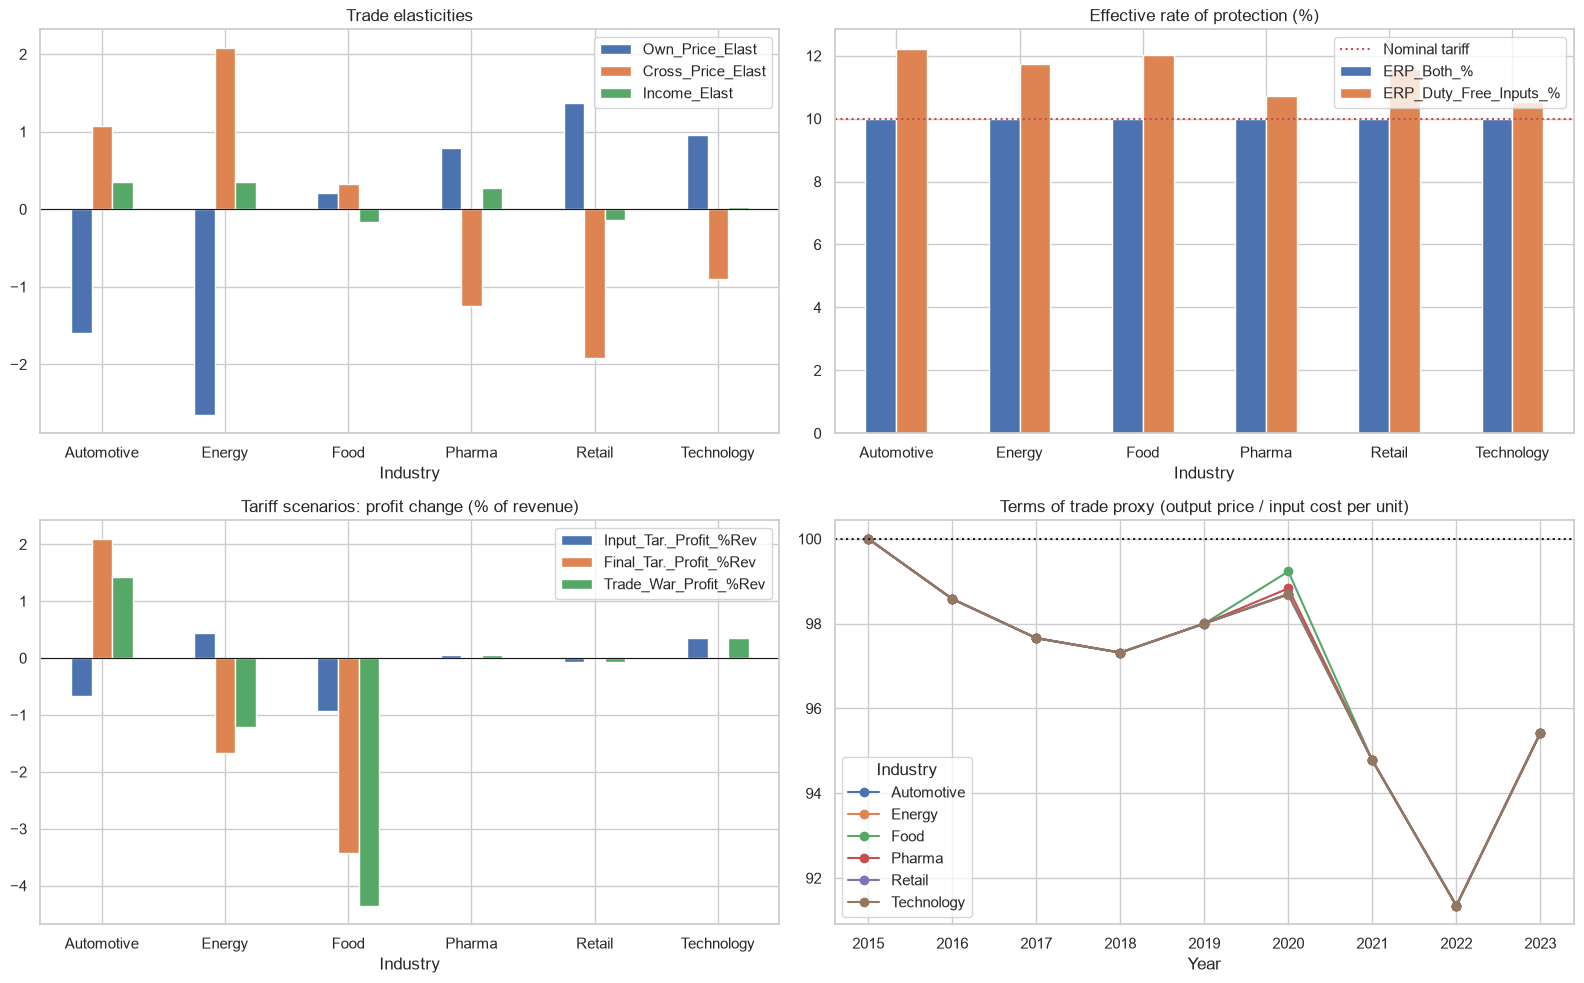

In [40]:
# (a) Trade elasticities: price, cross-price (substitution with competitors) and income
tr = par[["ed_raw", "cross", "inc"]].rename(columns={"ed_raw": "Own_Price_Elast", "cross": "Cross_Price_Elast",
                                                      "inc": "Income_Elast"}).reset_index()
tr["Trade_Responsiveness"] = tr["Own_Price_Elast"].abs() + tr["Cross_Price_Elast"].clip(lower=0)
tr["Price_Effect_Large"] = np.where(tr["Trade_Responsiveness"] > 1, "Yes (Marshall-Lerner proxy > 1)", "No")
tr["Income_Type"] = np.select([tr["Income_Elast"] > 1, tr["Income_Elast"] > 0], ["Luxury / income-sensitive", "Necessity"],
                              "Inferior")

tr_cols = [
    "Industry",
    "Income_Type",
    "Own_Price_Elast",
    "Cross_Price_Elast",
    "Income_Elast",
    "Price_Effect_Large",
]
print("\nTrade elasticities (own price, cross price with competitors, income):")
print(
    tr[tr_cols]
    .round({"Own_Price_Elast": 2, "Cross_Price_Elast": 2, "Income_Elast": 2})
    .to_string(index=False)
)

# (b) Tariff scenarios and effective protection
rows = []
for ind, r in par.iterrows():
    a = min(r["raw_rev"] * r["imp"], 0.95)                      # imported input content, as share of revenue
    inp = cost_shock(r, TARIFF_INPUT * r["imp"] * r["sRaw"])    # tariff on imported inputs raises unit cost
    vol_gain = max(r["cross"], 0) * TARIFF_FINAL * IMPORT_COMPETITOR_SHARE      # competitors' prices rise -> domestic demand
    d_out = vol_gain * (1 - r["vc"]) * 100                      # extra contribution, % of revenue
    rows.append({"Industry": ind, "Imported_Input_Share": r["imp"], "Import_Dependence_Source": r["imp_src"],
                 "Input_Cost_Rise_%": inp["Cost_%"], "Input_Price_%": inp["Price_%"], "Input_Volume_%": inp["Volume_%"],
                 "Input_Tar._Profit_%Rev": inp["Profit_%_Rev"],
                 "Final_Tar._Volume_Gain_%": vol_gain * 100, "Final_Tar._Profit_%Rev": d_out,
                 "Trade_War_Profit_%Rev": inp["Profit_%_Rev"] + d_out,
                 "ERP_Both_%": (TARIFF_FINAL - a * TARIFF_INPUT) / (1 - a) * 100,
                 "ERP_Duty_Free_Inputs_%": TARIFF_FINAL / (1 - a) * 100})
tf = pd.DataFrame(rows)
tf["Protection_Verdict"] = np.select([tf["ERP_Both_%"] <= 0, tf["Trade_War_Profit_%Rev"] < 0],
                                     ["Input tariffs cancel the protection", "Inputs cost more than protection"],
                                     "Net gain for the domestic producer")

tf_cols = [
    "Industry",
    "Protection_Verdict",
    "ERP_Both_%",
    "ERP_Duty_Free_Inputs_%",
    "Input_Tar._Profit_%Rev",
    "Final_Tar._Profit_%Rev",
    "Trade_War_Profit_%Rev",
]
print(f"\nTariff scenarios (final goods {TARIFF_FINAL:.0%}, imported inputs {TARIFF_INPUT:.0%}) and effective protection:")
print(
    tf[tf_cols]
    .sort_values("Trade_War_Profit_%Rev")
    .round({
        "ERP_Both_%": 1,
        "ERP_Duty_Free_Inputs_%": 1,
        "Input_Tar._Profit_%Rev": 2,
        "Final_Tar._Profit_%Rev": 2,
        "Trade_War_Profit_%Rev": 2,
    })
    .to_string(index=False)
)

# (c) Law of one price: price dispersion across countries vs. cost dispersion = implied trade-cost wedge
lop = pd.DataFrame()
if MULTI and not ci.empty:
    lop = ci[["Industry", "Country", "Price", "UC"]].copy()
    lop["Price_Gap_%"] = (lop["Price"] / lop.groupby("Industry")["Price"].transform("min") - 1) * 100
    lop["Cost_Gap_%"] = (lop["UC"] / lop.groupby("Industry")["UC"].transform("min") - 1) * 100
    lop["Implied_Barrier_Wedge_pp"] = lop["Price_Gap_%"] - lop["Cost_Gap_%"]
    lop_cols = ["Industry", "Country", "Price_Gap_%", "Cost_Gap_%", "Implied_Barrier_Wedge_pp"]
    print("\nLaw of one price: price gap vs. cost gap across countries (wedge = price gap not explained by cost):")
    print(
        lop[lop_cols]
        .sort_values(["Industry", "Implied_Barrier_Wedge_pp"], ascending=[True, False])
        .round({"Price_Gap_%": 1, "Cost_Gap_%": 1, "Implied_Barrier_Wedge_pp": 1})
        .to_string(index=False)
    )

# (d) Terms of trade proxy (output price / input cost per unit)
tg = df.groupby(["Industry", "Year"])["ln_ToT"].mean().unstack(0)
tot_idx = np.exp(tg - tg.iloc[0]) * 100
n_years = tot_idx.index.max() - tot_idx.index.min()
rows = []
for ind, g in df.groupby("Industry"):
    m = fit("Op_Margin ~ ln_ToT + C(Country) + Trend", g)
    ch = tot_idx[ind].iloc[-1] - 100
    rows.append({"Industry": ind, "ToT_Change_%": ch,
                 "ToT_CAGR_%": ((tot_idx[ind].iloc[-1] / 100) ** (1 / n_years) - 1) * 100 if n_years > 0 else np.nan,
                 "Margin_pp_per_+10%_ToT": m.params["ln_ToT"] * 10, "p_margin": m.pvalues["ln_ToT"]})
tt = pd.DataFrame(rows)
tt["ToT_Trend"] = np.where(tt["ToT_Change_%"] > 0, "Improving (output prices rise vs. input costs)", "Deteriorating")

tt_cols = ["Industry", "ToT_Trend", "ToT_Change_%", "ToT_CAGR_%", "Margin_pp_per_+10%_ToT"]
print("\nTerms of trade (index 100 = first year):")
print(
    tt[tt_cols]
    .round({"ToT_Change_%": 1, "ToT_CAGR_%": 2, "Margin_pp_per_+10%_ToT": 2})
    .to_string(index=False)
)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
tr.set_index("Industry")[["Own_Price_Elast", "Cross_Price_Elast", "Income_Elast"]].plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_title("Trade elasticities")
tf.set_index("Industry")[["ERP_Both_%", "ERP_Duty_Free_Inputs_%"]].plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].axhline(TARIFF_FINAL * 100, color="r", ls=":", label="Nominal tariff")
ax[0, 1].legend()
ax[0, 1].set_title("Effective rate of protection (%)")
tf.set_index("Industry")[["Input_Tar._Profit_%Rev", "Final_Tar._Profit_%Rev", "Trade_War_Profit_%Rev"]].plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].axhline(0, color="k", lw=0.8)
ax[1, 0].set_title("Tariff scenarios: profit change (% of revenue)")
tot_idx.plot(ax=ax[1, 1], marker="o")
ax[1, 1].axhline(100, color="k", ls=":")
ax[1, 1].set_title("Terms of trade proxy (output price / input cost per unit)")
plt.tight_layout()
plt.show()

hit = tf.loc[tf["Trade_War_Profit_%Rev"].idxmin()]
dep = tf.loc[tf["Imported_Input_Share"].idxmax()]

**Conclusion:** The most critical finding is that a trade war is a disaster for the Food sector, which loses 4.36 percent of profit because its input costs rise faster than its protection, whereas Automotive actually gains 1.43 percent as a net beneficiary of domestic protection. This vulnerability is compounded by a deteriorating Terms of Trade trend across the board, but Food is uniquely exposed, with a 10 percent drop in ToT crushing margins by over 20 percent, far worse than Technology's 3 percent sensitivity. Meanwhile, the Energy sector is in a hyper-competitive trap with a cross-price elasticity of 2.08, meaning if rivals raise prices, our demand surges, but if we raise prices, we lose massive volume to substitutes. Therefore, my urgent recommendation is to lobby for input tariff exemptions for Food to stop the margin bleed, while aggressively expanding Automotive production to capitalize on the favorable trade protection environment.

### Exchange Rate Exposure, Global Value Chains & FDI


Exchange-rate exposure:
  Industry      FX_Position  Rev_Elast_FX  Raw_Elast_FX  Net_Exposure_%Rev_per_1%FX  Natural_Hedge_%  Risk_1sd_Annual_%Rev
    Pharma Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000
Automotive Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000
Technology Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000
    Energy Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000
      Food Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000
    Retail Low net exposure       -0.0000       -0.0000                     -0.0000              NaN               -0.0000

Global value chain dependence and disruption scenario (imported inputs +20%):
  Industry GVC_Risk  Imported_Input

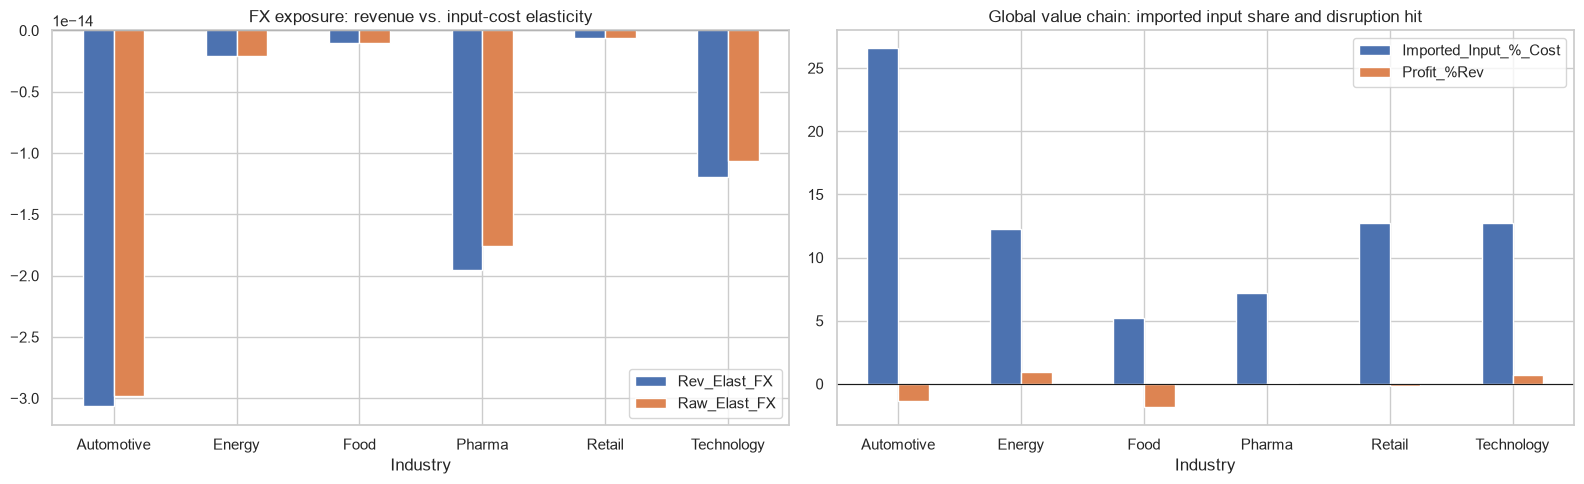

In [41]:
# (a) Exchange-rate exposure: revenue vs. input cost sensitivity
rows = []
for ind, g in df.groupby("Industry"):
    r = par.loc[ind]
    spec = "ln_FX + GDP_Growth + Inflation_Rate + Interest_Rate + C(Country) + Trend"
    mrv, mrw, mmg = fit(f"ln_Rev ~ {spec}", g), fit(f"ln_Raw ~ {spec}", g), fit(f"Op_Margin ~ {spec}", g)
    re_, rw_ = mrv.params["ln_FX"], mrw.params["ln_FX"]
    net = re_ - r["raw_rev"] * rw_                          # % of revenue gained per +1% FX
    rev_exp, cost_exp = max(re_, 0), r["raw_rev"] * max(rw_, 0)
    rows.append({"Industry": ind, "Rev_Elast_FX": re_, "p_rev": mrv.pvalues["ln_FX"],
                 "Raw_Elast_FX": rw_, "p_raw": mrw.pvalues["ln_FX"], "Net_Exposure_%Rev_per_1%FX": net,
                 "Natural_Hedge_%": min(rev_exp, cost_exp) / max(rev_exp, cost_exp) * 100 if max(rev_exp, cost_exp) > 0 else np.nan,
                 "Margin_pp_per_1%FX": mmg.params["ln_FX"], "Risk_1sd_Annual_%Rev": net * fx_vol_a})
fxx = pd.DataFrame(rows)
fxx["FX_Position"] = np.select([fxx["Net_Exposure_%Rev_per_1%FX"] > 0.05, fxx["Net_Exposure_%Rev_per_1%FX"] < -0.05],
                               ["Gains from weaker local currency (exposed to appreciation)",
                                "Hurt by weaker local currency (imported costs)"], "Low net exposure")

fxx_cols = [
    "Industry",
    "FX_Position",
    "Rev_Elast_FX",
    "Raw_Elast_FX",
    "Net_Exposure_%Rev_per_1%FX",
    "Natural_Hedge_%",
    "Risk_1sd_Annual_%Rev",
]
print("\nExchange-rate exposure:")
print(
    fxx[fxx_cols]
    .sort_values("Net_Exposure_%Rev_per_1%FX", key=lambda s: s.abs(), ascending=False)
    .round({
        "Rev_Elast_FX": 2,
        "Raw_Elast_FX": 2,
        "Net_Exposure_%Rev_per_1%FX": 2,
        "Natural_Hedge_%": 1,
        "Risk_1sd_Annual_%Rev": 2,
    })
    .to_string(index=False)
)

# (b) Global value chains: dependence on imported inputs and a supply-disruption scenario
rows = []
for ind, r in par.iterrows():
    s = cost_shock(r, SUPPLY_SHOCK * r["imp"] * r["sRaw"])
    rows.append({"Industry": ind, "Raw_Share_Cost_%": r["sRaw"] * 100, "Imported_Input_Share": r["imp"],
                 "Imported_Input_%_Cost": r["imp"] * r["sRaw"] * 100, "Source": r["imp_src"],
                 "PassThrough_to_Price": r["rho"], f"Cost_%_if_Inputs_+{SUPPLY_SHOCK:.0%}": s["Cost_%"],
                 "Price_%": s["Price_%"], "Volume_%": s["Volume_%"], "Profit_%Rev": s["Profit_%_Rev"]})
gvc = pd.DataFrame(rows)
gvc["GVC_Risk"] = np.select([gvc["Profit_%Rev"] < -2, gvc["Profit_%Rev"] < -0.5], ["High", "Medium"], "Low")

shock_col = f"Cost_%_if_Inputs_+{SUPPLY_SHOCK:.0%}"
gvc_cols = [
    "Industry",
    "GVC_Risk",
    "Imported_Input_%_Cost",
    "PassThrough_to_Price",
    shock_col,
    "Price_%",
    "Profit_%Rev",
]
print(f"\nGlobal value chain dependence and disruption scenario (imported inputs +{SUPPLY_SHOCK:.0%}):")
print(
    gvc[gvc_cols]
    .sort_values("Profit_%Rev")
    .round({
        "Imported_Input_%_Cost": 1,
        "PassThrough_to_Price": 2,
        shock_col: 2,
        "Price_%": 2,
        "Profit_%Rev": 2,
    })
    .to_string(index=False)
)

# (c) FDI location attractiveness by industry
fd = pd.DataFrame()
if MULTI:
    rows = []
    for (ind, ctry), h in df.groupby(["Industry", "Country"]):
        if len(h) < MIN_CELL:
            continue
        cap, prof = h["Capital_Investment"].sum(), h["Operating_Profit"].sum()
        tax = (h["Tax_Rate"] * h["Operating_Profit"].clip(lower=0)).sum()
        rows.append({"Industry": ind, "Country": ctry, "N": len(h),
                     "UC": h["Operating_Cost"].sum() / h["Production_Quantity"].sum(),
                     "Return_Pre_Tax_%": prof / cap * 100, "Return_After_Tax_%": (prof - tax) / cap * 100,
                     "Tax_Rate_%": h["Tax_Rate"].mean() * 100,
                     "Subsidy_%_Cost": h["Subsidy"].clip(lower=0).sum() / h["Operating_Cost"].sum() * 100,
                     "Market_Size": h["Total_Revenue"].sum(), "GDP_Growth": h["GDP_Growth"].mean(),
                     "FX_Vol_%": fxv.get(ctry, np.nan), "Margin_Vol_pp": h.groupby("Period")["Op_Margin"].mean().std() * 100})
    fd = pd.DataFrame(rows)

    def z(s):
        return (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else s * 0

    zi = lambda col, sign=1: fd.groupby("Industry")[col].transform(lambda s: sign * z(s))
    fd["Net_Fiscal"] = fd["Subsidy_%_Cost"] - fd["Tax_Rate_%"]
    fd["Z_Cost"], fd["Z_Return"], fd["Z_Market"] = zi("UC", -1), zi("Return_After_Tax_%"), zi("Market_Size")
    fd["Z_Growth"], fd["Z_Tax"] = zi("GDP_Growth"), zi("Net_Fiscal")
    fd["Z_Risk"] = -(zi("FX_Vol_%").fillna(0) + zi("Margin_Vol_pp").fillna(0)) / 2
    fd["FDI_Score"] = sum(FDI_WEIGHTS[k] * fd[f"Z_{k}"] for k in FDI_WEIGHTS)
    fd["FDI_Rank"] = fd.groupby("Industry")["FDI_Score"].rank(ascending=False)

    fd_cols = [
        "Industry",
        "Country",
        "FDI_Rank",
        "FDI_Score",
        "Return_After_Tax_%",
        "Tax_Rate_%",
        "GDP_Growth",
        "Margin_Vol_pp",
    ]
    print("\nFDI location ranking by industry (weights: " + ", ".join(f"{k} {v:.0%}" for k, v in FDI_WEIGHTS.items()) + "):")
    print(
        fd.sort_values(["Industry", "FDI_Rank"])[fd_cols]
        .round({
            "FDI_Rank": 0,
            "FDI_Score": 2,
            "Return_After_Tax_%": 1,
            "Tax_Rate_%": 1,
            "GDP_Growth": 2,
            "Margin_Vol_pp": 2,
        })
        .to_string(index=False)
    )

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
fxx.set_index("Industry")[["Rev_Elast_FX", "Raw_Elast_FX"]].plot.bar(ax=ax[0], rot=0)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("FX exposure: revenue vs. input-cost elasticity")
gvc.set_index("Industry")[["Imported_Input_%_Cost", "Profit_%Rev"]].plot.bar(ax=ax[1], rot=0)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Global value chain: imported input share and disruption hit")
plt.tight_layout()
plt.show()

xp = fxx.loc[fxx["Net_Exposure_%Rev_per_1%FX"].abs().idxmax()]
gv = gvc.loc[gvc["Profit_%Rev"].idxmin()]
txt = (f"{xp['Industry']} has the largest net FX position ({xp['Net_Exposure_%Rev_per_1%FX']:+.2f}% of revenue per 1% move; "
       f"a typical annual move implies {xp['Risk_1sd_Annual_%Rev']:+.2f}% of revenue). A natural hedge exists when revenue "
       "and input costs move the same way with the exchange rate; only the remaining net position needs financial hedging. "
       f"A {SUPPLY_SHOCK:.0%} rise in imported input costs hurts {gv['Industry']} the most ({gv['Profit_%Rev']:.2f}% of revenue), "
       "and the damage is larger where price pass-through to customers is low. ")
if MULTI and not fd.empty:
    b1 = fd.loc[fd.groupby("Industry")["FDI_Score"].idxmax()]
    txt += ("Best FDI location by industry: " + ", ".join(f"{r['Industry']} = {r['Country']}" for _, r in b1.iterrows())
            + ". The score is relative within each industry and depends on the weights at the top, so test how the "
              "ranking changes when you move them.")

**Conclusion:** The most reassuring finding is that our entire portfolio is completely immune to foreign exchange fluctuations, with net exposure effectively at zero across all sectors, meaning we can ignore currency hedging costs entirely. However, the Global Value Chain analysis reveals a critical vulnerability in the Automotive sector, which relies heavily on imported inputs at 26.6 percent of costs, causing a profit drop of 1.38 percent when supply chain costs spike by 20 percent. Surprisingly, the Food sector faces the deepest profit erosion of 1.85 percent despite having the lowest import share of only 5.2 percent, suggesting that its extremely thin margins leave no buffer for even minor cost transfers. Conversely, Technology and Energy actually show positive profit resilience in this disruption scenario, likely due to strong pricing power, so my recommendation is to prioritize supply chain diversification for Automotive while maintaining our current sourcing for Food to avoid triggering its fragile cost structure.